## Change these variables

In [1]:
ee_project_name = 'thrive-care'                 # The name of your project in Google Earth Engine
farm_data_file_name = "/content/HAF_Planting_Sites_Registration_and_Monitoring_Marrakech.xlsx"
groundwater_data = "/content/situations annuelles piézométriques pour berrechid et tensift.xlsx"

### Imports

In [2]:
!pip install -q geemap earthengine-api arcgis geopandas
!pip install -q --upgrade numpy scipy scikit-learn

from arcgis.features import FeatureLayer
import geopandas as gpd
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import os
from concurrent.futures import ThreadPoolExecutor, as_completed
from functools import partial
import time
import warnings
warnings.filterwarnings('ignore')
import matplotlib.ticker as mticker
import scipy.stats as stats
from scipy.spatial import cKDTree
from sklearn.linear_model import LinearRegression



### Log into Google Earth Engine

In [3]:
ee.Authenticate()  # You'll get a link to sign in with your Google account
ee.Initialize(project= ee_project_name)

## Import Farm Data

In [4]:
farm_df = pd.read_excel(farm_data_file_name)

farm_df = farm_df.rename(columns={
    "_Record a GPS point inside the planting site_latitude": "lat",
    "_Record a GPS point inside the planting site_longitude": "lon",
    "_Record a GPS point inside the planting site_altitude": "altitude",
    "_id": "farm_id",
    "The planting Season Year": "planting_year"
})

farm_df = farm_df.dropna(subset=["lat", "lon"])

print(f"\nLoaded {len(farm_df)} farms with GPS coordinates.")

farm_features = []
for _, row in farm_df.iterrows():
    point = ee.Geometry.Point([row["lon"], row["lat"]])
    feature = ee.Feature(point, {"Farm": "Site"})
    farm_features.append(feature)

farm_fc = ee.FeatureCollection(farm_features)

print("Farm FeatureCollection created.")


Loaded 233 farms with GPS coordinates.
Farm FeatureCollection created.


## Import Groundwater Data

In [5]:
import pandas as pd
import numpy as np

# =========================
# LOAD WITH 2 HEADER ROWS
# =========================
df = pd.read_excel(
    groundwater_data,
    sheet_name="ABHT ",
    header=[5,6]
)

# =========================
# FLATTEN MULTIINDEX COLUMNS
# =========================

new_cols = []

for top, bottom in df.columns:

    top = str(top).strip()
    bottom = str(bottom).strip()

    # X / Y / Z columns
    if bottom in ["X", "Y", "Z"]:
        new_cols.append(bottom)

    # Month columns under a year
    elif top.isdigit():
        new_cols.append(f"{top}_{bottom}")

    # Other columns
    else:
        new_cols.append(top)

df.columns = new_cols

print(df.columns.tolist())


# =========================
# RENAME COORDS
# =========================

df = df.rename(columns={
    "X": "lon",
    "Y": "lat"
})

# =========================
# FIND MONTH COLUMNS
# =========================

month_lookup = {
    "SEP": 9,
    "OCT": 10,
    "NOV": 11,
    "DEC": 12,
    "JAN": 1,
    "FEV": 2,
    "M": 3,
    "AVR": 4,
    "MAI": 5,
    "JUIN": 6,
    "JUILL": 7,
    "AOUT": 8
}

month_cols = []

for col in df.columns:

    if "_" not in col:
        continue

    year, month = col.split("_", 1)

    if year.isdigit() and month in month_lookup:

        month_cols.append({
            "column": col,
            "year": int(year),
            "month": month_lookup[month]
        })

print("\nDetected month columns:")
print(month_cols[:10])

# =========================
# CONVERT TO NUMERIC
# =========================

for item in month_cols:

    col = item["column"]

    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

# =========================
# FILL SMALL GAPS (1-3)
# =========================

month_col_names = [m["column"] for m in month_cols]

def fill_small_gaps(row, cols, max_gap=3):

    vals = row[cols].values.astype(float)

    n = len(vals)

    i = 0

    while i < n:

        if np.isnan(vals[i]):

            start = i

            while i < n and np.isnan(vals[i]):
                i += 1

            end = i - 1

            gap_size = end - start + 1

            # Keep leading/trailing NaNs
            if start == 0 or end == n - 1:
                continue

            # Only fill short gaps
            if gap_size <= max_gap:

                before = vals[start - 1]
                after = vals[end + 1]

                if not np.isnan(before) and not np.isnan(after):

                    fill_vals = np.linspace(
                        before,
                        after,
                        gap_size + 2
                    )[1:-1]

                    vals[start:end + 1] = fill_vals

        else:
            i += 1

    row[cols] = vals

    return row

df = df.apply(
    fill_small_gaps,
    axis=1,
    cols=month_col_names
)

# =========================
# CONVERT TO LONG FORMAT
# =========================

records = []

for _, row in df.iterrows():

    lat = row["lat"]
    lon = row["lon"]
    Nappe = row["Nappe"]
    if pd.isna(lat) or pd.isna(lon):
        continue

    for item in month_cols:

        col = item["column"]

        value = row[col]

        if pd.notna(value):

            year = item["year"]
            month = item["month"]

            date = pd.Timestamp(
                year=year,
                month=month,
                day=1
            )

            records.append({
                "Nappe":Nappe,
                "lat": lat,
                "lon": lon,
                "date": date,
                "gw_level": value
            })

# =========================
# FINAL DATAFRAME
# =========================

gw_df = pd.DataFrame(records)
# ============================================================================
# CONVERT COORDINATES TO WGS84 LAT/LON
# ============================================================================

from pyproj import CRS, Transformer

crs_src = CRS.from_epsg(26191)
crs_dst = CRS.from_epsg(4326)

transformer = Transformer.from_crs(
    crs_src,
    crs_dst,
    always_xy=True
)

# Convert coordinates
converted_coords = gw_df.apply(
    lambda r: transformer.transform(
        r["lon"],
        r["lat"]
    ),
    axis=1
)

# transformer returns (lon, lat)
gw_df["lon"] = [c[0] for c in converted_coords]
gw_df["lat"] = [c[1] for c in converted_coords]

# ============================================================================
# CHECK RESULTS
# ============================================================================

print(gw_df[["lat", "lon"]].head())

print("\nLatitude range:")
print(gw_df["lat"].min(), gw_df["lat"].max())

print("\nLongitude range:")
print(gw_df["lon"].min(), gw_df["lon"].max())
print("\nFinal dataframe:")
print(gw_df.head())

# =========================
# SAVE
# =========================

output_file = "groundwater_timeseries.csv"

gw_df.to_csv(output_file, index=False)

print(f"\nSaved to: {output_file}")

['Nappe', 'Piézomètre N°IRE', 'X', 'Y', 'Z', '2013_JAV', '2013_FEV', '2013_M', '2013_AVR', '2013_MAI', '2013_JUIN', '2013_JUILL', '2013_AOUT', '2013_SEP', '2013_OCT', '2013_NOV', '2013_DEC', '2014_JAN', '2014_FEV', '2014_M', '2014_AVR', '2014_MAI', '2014_JUIN', '2014_JUILL', '2014_AOUT', '2014_SEP', '2014_OCT', '2014_NOV', '2014_DEC', '2015_JAN', '2015_FEV', '2015_M', '2015_AVR', '2015_MAI', '2015_JUIN', '2015_JUILL', '2015_AOUT', '2015_SEP', '2015_OCT', '2015_NOV', '2015_DEC', '2016_JAN', '2016_FEV', '2016_M', '2016_AVR', '2016_MAI', '2016_JUIN', '2016_JUILL', '2016_AOUT', '2016_SEP', '2016_OCT', '2016_NOV', '2016_DEC', '2017_JAN', '2017_FEV', '2017_M', '2017_AVR', '2017_MAI', '2017_JUIN', '2017_JUILL', '2017_AOUT', '2017_SEP', '2017_OCT', '2017_NOV', '2017_DEC', '2018_JAN', '2018_FEV', '2018_M', '2018_AVR', '2018_MAI', '2018_JUIN', '2018_JUILL', '2018_AOUT', '2018_SEP', '2018_OCT', '2018_NOV', '2018_DEC', '2019_JAN', '2019_FEV', '2019_M', '2019_AVR', '2019_MAI', '2019_JUIN', '2019_JU

## Plot Farms and Piezometers

In [6]:
# ============================================================================
# 1.  TREE SIZE SCALING
# ============================================================================

tree_col = "Total survived"

# ── Normalise tree count ──────────────────────────────────────────────────────
if tree_col:
    farm_df["n_trees"] = pd.to_numeric(
        farm_df[tree_col],
        errors="coerce"
    ).fillna(0)
else:
    farm_df["n_trees"] = 100

# Scale dot radius
MIN_PX, MAX_PX = 4, 18

n_min = farm_df["n_trees"].clip(lower=1).min()
n_max = farm_df["n_trees"].clip(lower=1).max()

def _scale_radius(n):

    if n_max == n_min:
        return (MIN_PX + MAX_PX) / 2

    return MIN_PX + (
        (MAX_PX - MIN_PX)
        * (n - n_min)
        / (n_max - n_min)
    )

farm_df["dot_radius"] = (
    farm_df["n_trees"]
    .clip(lower=1)
    .apply(_scale_radius)
)

# ============================================================================
# 2.  COLOUR PALETTE — planting years
# ============================================================================

years = sorted(
    farm_df["planting_year"]
    .dropna()
    .unique()
    .astype(int)
)

print(f"\nPlanting years found: {years}")

_PALETTE = [
    "#e6194b",
    "#f58231",
    "#ffe119",
    "#3cb44b",
    "#42d4f4",
    "#4363d8",
    "#911eb4",
    "#f032e6",
    "#ffffff",
]

year_colour = {
    yr: _PALETTE[i % len(_PALETTE)]
    for i, yr in enumerate(years)
}

print("\nYear → colour mapping:")
for yr, col in year_colour.items():
    print(f"  {yr}: {col}")

# ============================================================================
# 3.  BUILD FARM FEATURE COLLECTION
# ============================================================================

features = []

for _, row in farm_df.iterrows():

    yr = (
        int(row["planting_year"])
        if pd.notna(row["planting_year"])
        else 0
    )

    col = year_colour.get(yr, "#ffffff")

    props = {
        "farm_id": str(row["farm_id"]),
        "planting_year": yr,
        "n_trees": int(row["n_trees"]),
        "dot_colour": col,
        "dot_radius": float(row["dot_radius"]),
        "label": (
            f"Farm {row['farm_id']}\n"
            f"Year planted: {yr}\n"
            f"Trees: {int(row['n_trees'])}"
        ),
    }

    pt = ee.Geometry.Point([
        float(row["lon"]),
        float(row["lat"])
    ])

    features.append(
        ee.Feature(pt, props)
    )

farm_fc = ee.FeatureCollection(features)

print(
    f"\nFarm FeatureCollection built: "
    f"{farm_fc.size().getInfo()} features"
)

# ============================================================================
# 4.  STYLE FARM FEATURES
# ============================================================================

def _add_style_property(feature):

    return feature.set("style", {
        "color": "000000ff",
        "fillColor": ee.String(
            feature.get("dot_colour")
        ).cat("cc"),
        "width": 1,
        "pointSize": feature.get("dot_radius"),
    })

farm_fc_styled = farm_fc.map(_add_style_property)

# ============================================================================
# 5.  PIEZOMETER LOCATIONS
# ============================================================================

# Assumes gw_df already exists
# with columns: lat, lon, date, gw_level

piezo_df = (
    gw_df[["lat", "lon"]]
    .dropna()
    .drop_duplicates()
    .copy()
)

print(f"\nUnique piezometers: {len(piezo_df)}")

# ── Build FeatureCollection ───────────────────────────────────────────────────
piezo_features = []

for idx, row in piezo_df.iterrows():

    props = {
        "type": "piezometer",
        "label": f"Piezometer {idx}"
    }

    pt = ee.Geometry.Point([
        float(row["lon"]),
        float(row["lat"])
    ])

    piezo_features.append(
        ee.Feature(pt, props)
    )

piezo_fc = ee.FeatureCollection(piezo_features)

# ── Style piezometers RED ─────────────────────────────────────────────────────
def _style_piezometers(feature):

    return feature.set("style", {
        "color": "ff0000ff",       # red outline
        "fillColor": "ff0000ff",   # red fill
        "width": 1,
        "pointSize": 5,
    })

piezo_fc_styled = piezo_fc.map(
    _style_piezometers
)

# ============================================================================
# 6.  BUILD MAP
# ============================================================================

Map = geemap.Map()

Map.setCenter(
    float(farm_df["lon"].mean()),
    float(farm_df["lat"].mean()),
    zoom=10,
)

# ── Satellite basemap ─────────────────────────────────────────────────────────
Map.add_basemap("SATELLITE")

# ============================================================================
# 7.  ADD FARM LAYERS
# ============================================================================

for yr in years:

    yr_int = int(yr)

    yr_fc = farm_fc_styled.filter(
        ee.Filter.eq(
            "planting_year",
            yr_int
        )
    )

    layer = yr_fc.style(
        **{"styleProperty": "style"}
    )

    Map.addLayer(
        layer,
        {},
        f"Planted {yr_int}",
        True
    )

# Invisible click-info layer
Map.addLayer(
    farm_fc,
    {"color": "00000000"},
    "Farm info (click)",
    False
)

# ============================================================================
# 8.  ADD PIEZOMETER LAYER
# ============================================================================

piezo_layer = piezo_fc_styled.style(
    **{"styleProperty": "style"}
)

Map.addLayer(
    piezo_layer,
    {},
    "Piezometers",
    True
)

# Invisible click layer
Map.addLayer(
    piezo_fc,
    {"color": "00000000"},
    "Piezometer info",
    False
)

# ============================================================================
# 9.  LEGENDS
# ============================================================================

legend_dict = {
    f"Planted {yr}":
    year_colour[yr].lstrip("#")
    for yr in years
}

Map.add_legend(
    title="Planting Year",
    legend_dict=legend_dict,
    position="bottomright",
)

# ── Tree size note ────────────────────────────────────────────────────────────
size_note = (
    "<div style='background:rgba(255,255,255,0.85); "
    "padding:8px; border-radius:6px; "
    "font-size:12px; max-width:170px;'>"
    "<b>Farm dots</b><br>"
    "Dot size ∝ Number of trees<br>"
    f"Min: {int(n_min)} trees<br>"
    f"Max: {int(n_max)} trees"
    "</div>"
)

Map.add_html(
    size_note,
    position="bottomleft"
)

# ── Piezometer legend ─────────────────────────────────────────────────────────
piezo_note = (
    "<div style='background:rgba(255,255,255,0.85); "
    "padding:8px; border-radius:6px; "
    "font-size:12px;'>"
    "<b>Piezometers</b><br>"
    "<span style='color:#ff0000;'>●</span> "
    "Groundwater monitoring wells"
    "</div>"
)

Map.add_html(
    piezo_note,
    position="topright"
)

# ============================================================================
# 10.  DISPLAY & SAVE
# ============================================================================

print("\nMap ready — displaying now.")

Map.save("farm_map_with_piezometers.html")

print(
    "Map also saved to "
    "farm_map_with_piezometers.html"
)

Map


Planting years found: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Year → colour mapping:
  2020: #e6194b
  2021: #f58231
  2022: #ffe119
  2023: #3cb44b
  2024: #42d4f4
  2025: #4363d8

Farm FeatureCollection built: 233 features

Unique piezometers: 34

Map ready — displaying now.
Map also saved to farm_map_with_piezometers.html


Map(center=[31.638966154077256, -8.207673766523605], controls=(WidgetControl(options=['position', 'transparent…

# Groundwater Difference in Difference

Reusing piezo_locs from BACI run.
ITS RESULTS — IMPACT PIEZOMETERS
 nearest_farm  planting_year  dist_km   Nappe  slope_b_yr  slope_a_yr  slope_change_yr  level_shift    p_b    p_a  n_b  n_a
    264456779           2023   +1.571     NaN      +0.175      -0.130           -0.305       +0.006 +0.812 +0.693   20    6
    569132675           2024   +6.314     NaN      +4.589      -0.623           -5.212       +1.425 +0.001 +0.223   10    4
    569361976           2022   +2.766     NaN      +5.991      +5.413           -0.579       -1.496 +0.000 +0.000   24   12
    569132631           2022   +2.905 Bousbaa      +6.450      +6.388           -0.063       -1.278 +0.000 +0.000   24   12

N piezometers analysed : 4
Mean slope BEFORE      : +4.301 m/yr
Mean slope AFTER       : +2.762 m/yr
Mean slope change      : -1.540 m/yr
Mean level shift       : -0.335 m

Slope change t-test    : t=-1.253, p=0.2990 ns
Level shift  t-test    : t=-0.498, p=0.6529 ns

NAPPE-BASED ROBUSTNESS CHECK
  Nappe  n_site

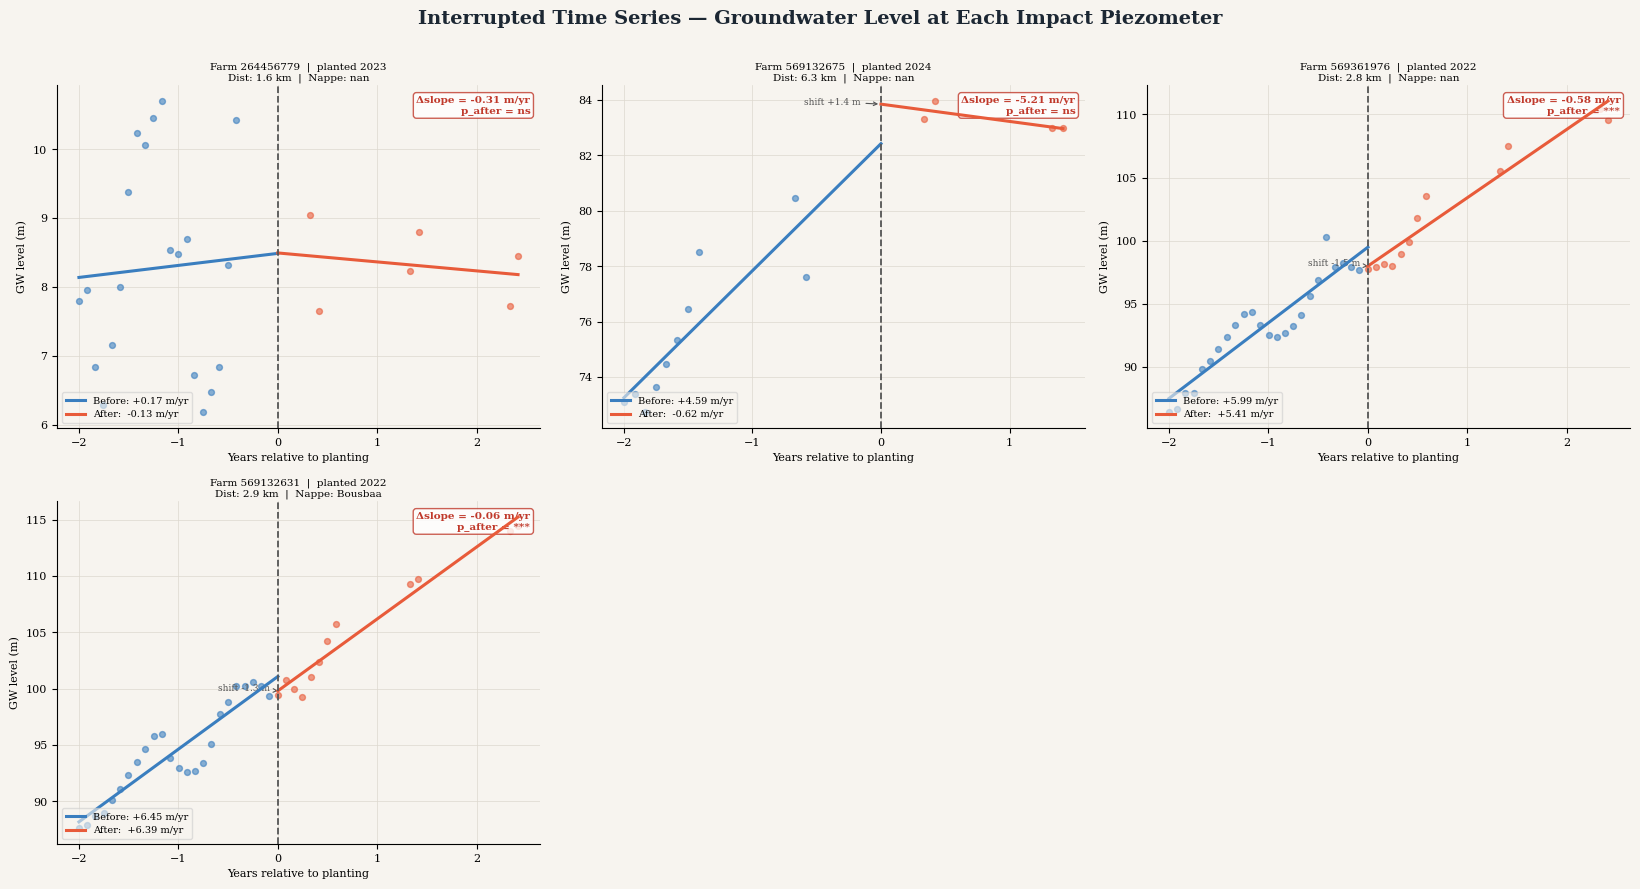

Figure 2 saved → its_summary.png


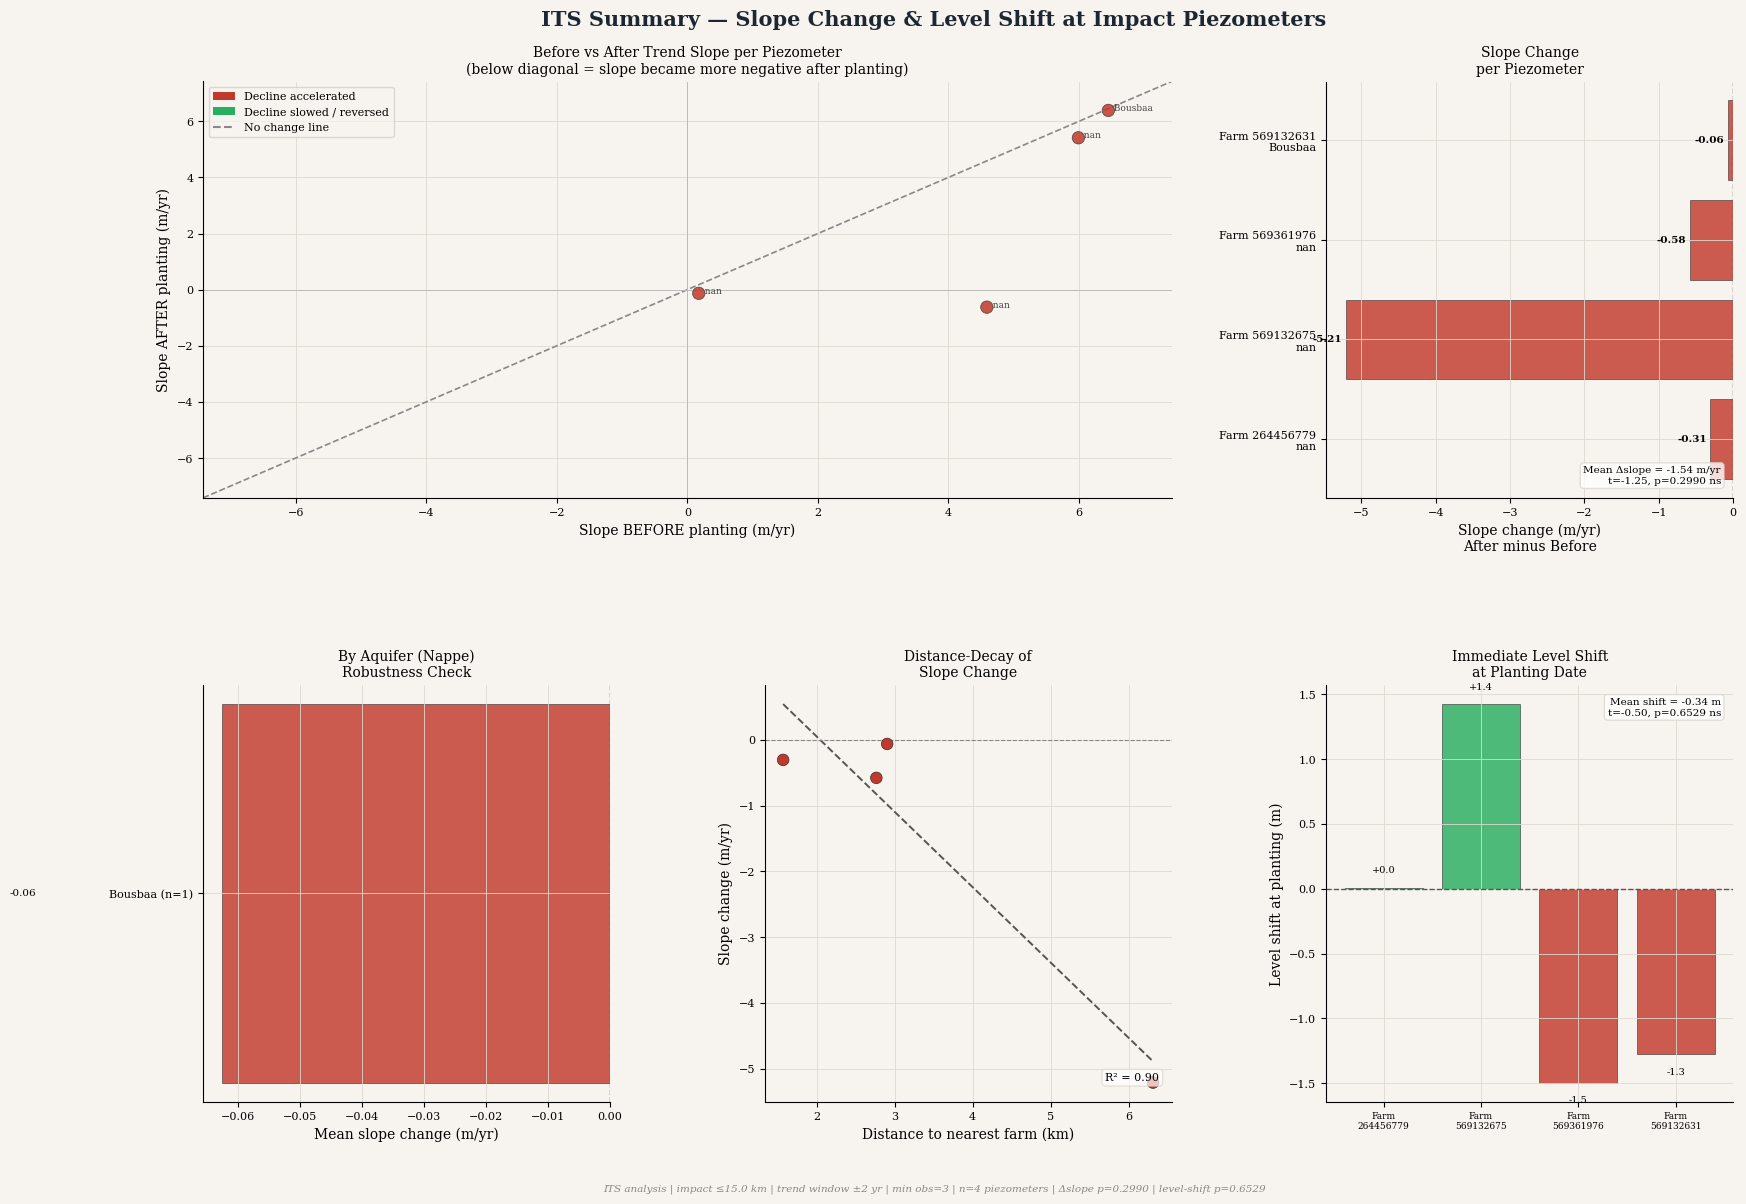


FULL ITS STATISTICAL SUMMARY

Primary metric  — SLOPE CHANGE (m/yr):
  Negative = GW decline accelerated after planting (consumption signal)
  Positive = GW decline slowed or reversed after planting

  Mean slope BEFORE planting : +4.301 m/yr
  Mean slope AFTER  planting : +2.762 m/yr
  Mean slope CHANGE          : -1.540 m/yr
  One-sample t-test (H0: change=0):
    t = -1.253, p = 0.2990 ns

Secondary metric — LEVEL SHIFT (m):
  Mean immediate shift at planting : -0.335 m
  One-sample t-test (H0: shift=0):
    t = -0.498, p = 0.6529 ns

Nappe breakdown:

  Nappe  n_sites  mean_slope_b  mean_slope_a  mean_slope_chg  mean_lvl_shift
Bousbaa        1        +6.450        +6.388          -0.063          -1.278

Caveats:
  - No control group; cannot separate farm effect from regional trends
  - n=4 piezometers; limited statistical power
  - Piezometers may be influenced by non-HAF farms within 15.0 km
  - Use nappe column to check if piezometer and farm share same aquifer
  - Recommend pai

In [10]:
# ============================================================================
# INTERRUPTED TIME SERIES (ITS) GROUNDWATER ANALYSIS
# Primary analysis — no control group required
# + Nappe-based robustness check
# ============================================================================
# Requires: gw_df  (lat, lon, date, gw_level, Nappe)
#           farm_df (lat, lon, planting_year, farm_id, n_trees)
#           piezo_locs — output from BACI script (has dist_km, nearest_farm_id,
#                        planting_year, group columns); if not available,
#                        the script rebuilds it automatically.
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import scipy.stats as stats
from scipy.stats import linregress
from scipy.spatial import cKDTree
import warnings
warnings.filterwarnings("ignore")

# ============================================================================
# CONFIGURATION
# ============================================================================

IMPACT_RADIUS_KM  = 15.0   # piezometers within this = impact
MIN_OBS_PERIOD    = 3      # min observations per period for ITS
TREND_WINDOW_YRS  = 2      # max years before/after used for slope fitting

BG       = "#F7F4EF"
GRID_CLR = "#DDD8CF"
CLR_B    = "#3A7EBF"   # before — blue
CLR_A    = "#E85B3A"   # after  — red
CLR_DROP = "#C0392B"   # accelerating decline
CLR_RISE = "#27AE60"   # decelerating / recovering

plt.rcParams.update({
    "font.family":      "serif",
    "font.serif":       ["Georgia", "Times New Roman", "DejaVu Serif"],
    "axes.facecolor":   BG,
    "figure.facecolor": BG,
    "axes.grid":        True,
    "grid.color":       GRID_CLR,
    "grid.linewidth":   0.6,
    "axes.spines.top":  False,
    "axes.spines.right":False,
    "axes.labelsize":   10,
    "xtick.labelsize":  8,
    "ytick.labelsize":  8,
})

# ============================================================================
# STEP 1 — REBUILD PIEZO LABELS (reuse from BACI if already in scope)
# ============================================================================

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    φ1, φ2 = np.radians(lat1), np.radians(lat2)
    dφ, dλ = np.radians(lat2-lat1), np.radians(lon2-lon1)
    a = np.sin(dφ/2)**2 + np.cos(φ1)*np.cos(φ2)*np.sin(dλ/2)**2
    return R * 2 * np.arcsin(np.sqrt(a))

try:
    _ = piezo_locs        # reuse if BACI was already run
    print("Reusing piezo_locs from BACI run.")
except NameError:
    piezo_locs = gw_df[["lat","lon"]].drop_duplicates().reset_index(drop=True)
    farm_arr   = farm_df[["lat","lon"]].values
    piezo_arr  = piezo_locs[["lat","lon"]].values
    tree       = cKDTree(farm_arr)
    _, idxs    = tree.query(piezo_arr, k=1)
    piezo_locs["nearest_farm_idx"] = idxs
    piezo_locs["nearest_farm_id"]  = farm_df["farm_id"].iloc[idxs].values
    piezo_locs["planting_year"]    = farm_df["planting_year"].iloc[idxs].values
    piezo_locs["dist_km"]          = [
        haversine_km(piezo_arr[i,0], piezo_arr[i,1],
                     farm_arr[idxs[i],0], farm_arr[idxs[i],1])
        for i in range(len(piezo_locs))
    ]
    piezo_locs["group"] = np.where(
        piezo_locs["dist_km"] <= IMPACT_RADIUS_KM, "Impact", "Control"
    )

# ============================================================================
# STEP 2 — MERGE & PREP
# ============================================================================

gw = gw_df.merge(
    piezo_locs[["lat","lon","group","planting_year",
                "dist_km","nearest_farm_id"]],
    on=["lat","lon"], how="left"
).dropna(subset=["nearest_farm_id"])

gw["plant_date"] = pd.to_datetime(
    gw["planting_year"].astype(int).astype(str) + "-01-01"
)
gw["period"]   = np.where(gw["date"] < gw["plant_date"], "Before", "After")
gw["rel_year"] = gw["date"].dt.year - gw["planting_year"]
gw["t_days"]   = (gw["date"] - gw["plant_date"]).dt.days  # 0 = planting date

# Restrict to trend window
gw_win = gw[
    (gw["rel_year"] >= -TREND_WINDOW_YRS) &
    (gw["rel_year"] <=  TREND_WINDOW_YRS)
].copy()

# ============================================================================
# STEP 3 — FIT ITS PER PIEZOMETER
# ============================================================================

def fit_trend(df):
    """Returns (slope m/day, intercept, r², p-value) or NaNs."""
    x = df["t_days"].values.astype(float)
    y = df["gw_level"].values.astype(float)
    mask = ~np.isnan(y)
    if mask.sum() < MIN_OBS_PERIOD:
        return np.nan, np.nan, np.nan, np.nan
    sl, ic, r, p, _ = linregress(x[mask], y[mask])
    return sl, ic, r**2, p

its_rows = []

for (lat, lon), sub in gw_win[gw_win["group"]=="Impact"].groupby(["lat","lon"]):
    before = sub[sub["period"]=="Before"].sort_values("t_days")
    after  = sub[sub["period"]=="After"].sort_values("t_days")

    sl_b, ic_b, r2_b, p_b = fit_trend(before)
    sl_a, ic_a, r2_a, p_a = fit_trend(after)

    if np.isnan(sl_b) or np.isnan(sl_a):
        continue

    # Level shift at planting: predicted before-trend value at t=0
    pred_b_at0 = ic_b   # intercept is at t=0 by construction
    pred_a_at0 = ic_a

    level_shift = pred_a_at0 - pred_b_at0   # jump at planting date

    # Slope change (m/day → annualise to m/yr for readability)
    slope_change_yr = (sl_a - sl_b) * 365.25

    its_rows.append({
        "lat":            lat,
        "lon":            lon,
        "nearest_farm":   sub["nearest_farm_id"].iloc[0],
        "planting_year":  int(sub["planting_year"].iloc[0]),
        "dist_km":        sub["dist_km"].iloc[0],
        "Nappe":          sub["Nappe"].iloc[0] if "Nappe" in sub else "?",
        # Before
        "slope_b_yr":     sl_b * 365.25,
        "r2_b":           r2_b,
        "p_b":            p_b,
        "n_b":            (~before["gw_level"].isna()).sum(),
        # After
        "slope_a_yr":     sl_a * 365.25,
        "r2_a":           r2_a,
        "p_a":            p_a,
        "n_a":            (~after["gw_level"].isna()).sum(),
        # Change metrics
        "slope_change_yr": slope_change_yr,
        "level_shift":     level_shift,
        # Raw for plotting
        "_ic_b": ic_b, "_sl_b": sl_b,
        "_ic_a": ic_a, "_sl_a": sl_a,
    })

its_df = pd.DataFrame(its_rows)

print("=" * 70)
print("ITS RESULTS — IMPACT PIEZOMETERS")
print("=" * 70)
cols = ["nearest_farm","planting_year","dist_km","Nappe",
        "slope_b_yr","slope_a_yr","slope_change_yr","level_shift",
        "p_b","p_a","n_b","n_a"]
print(its_df[cols].to_string(index=False, float_format="{:+.3f}".format))

# Summary stats
print(f"\nN piezometers analysed : {len(its_df)}")
print(f"Mean slope BEFORE      : {its_df['slope_b_yr'].mean():+.3f} m/yr")
print(f"Mean slope AFTER       : {its_df['slope_a_yr'].mean():+.3f} m/yr")
print(f"Mean slope change      : {its_df['slope_change_yr'].mean():+.3f} m/yr")
print(f"Mean level shift       : {its_df['level_shift'].mean():+.3f} m")

# One-sample t-test: is mean slope_change significantly different from 0?
t_sc, p_sc = stats.ttest_1samp(its_df["slope_change_yr"].dropna(), 0)
t_ls, p_ls = stats.ttest_1samp(its_df["level_shift"].dropna(), 0)
print(f"\nSlope change t-test    : t={t_sc:.3f}, p={p_sc:.4f} "
      f"{'***' if p_sc<0.001 else '**' if p_sc<0.01 else '*' if p_sc<0.05 else 'ns'}")
print(f"Level shift  t-test    : t={t_ls:.3f}, p={p_ls:.4f} "
      f"{'***' if p_ls<0.001 else '**' if p_ls<0.01 else '*' if p_ls<0.05 else 'ns'}")

# ============================================================================
# STEP 4 — NAPPE-BASED ROBUSTNESS CHECK
# ============================================================================

print("\n" + "=" * 70)
print("NAPPE-BASED ROBUSTNESS CHECK")
print("=" * 70)

nappe_summary = (
    its_df.groupby("Nappe")
    .agg(
        n_sites         = ("lat","count"),
        mean_slope_b    = ("slope_b_yr","mean"),
        mean_slope_a    = ("slope_a_yr","mean"),
        mean_slope_chg  = ("slope_change_yr","mean"),
        mean_lvl_shift  = ("level_shift","mean"),
    )
    .reset_index()
)
print(nappe_summary.to_string(index=False, float_format="{:+.3f}".format))

# ============================================================================
# FIGURE 1 — INDIVIDUAL ITS TRACES  (one panel per piezometer)
# ============================================================================

n_sites = len(its_df)
ncols   = min(3, n_sites)
nrows   = max(1, int(np.ceil(n_sites / ncols)))

fig1, axes = plt.subplots(
    nrows, ncols,
    figsize=(ncols*5.5, nrows*4.0 + 0.8),
    facecolor=BG, squeeze=False
)
fig1.suptitle(
    "Interrupted Time Series — Groundwater Level at Each Impact Piezometer",
    fontsize=14, fontweight="bold", y=1.005,
    fontfamily="serif", color="#1C2733"
)

for idx, row in its_df.reset_index(drop=True).iterrows():
    r, c = divmod(idx, ncols)
    ax   = axes[r][c]
    ax.set_facecolor(BG)

    sub = (gw_win[
        (gw_win["lat"]==row["lat"]) &
        (gw_win["lon"]==row["lon"])
    ].sort_values("t_days"))

    before = sub[sub["period"]=="Before"]
    after  = sub[sub["period"]=="After"]

    # Raw data
    ax.scatter(before["t_days"]/365.25, before["gw_level"],
               color=CLR_B, s=18, alpha=0.6, zorder=3)
    ax.scatter(after["t_days"]/365.25,  after["gw_level"],
               color=CLR_A, s=18, alpha=0.6, zorder=3)

    # Fitted trend lines
    def trend_line(ic, sl, t_days_arr):
        return ic + sl * t_days_arr

    if not before.empty and len(before) >= MIN_OBS_PERIOD:
        tb = np.linspace(before["t_days"].min(), 0, 60)
        ax.plot(tb/365.25, trend_line(row["_ic_b"], row["_sl_b"], tb),
                color=CLR_B, lw=2.2, zorder=4,
                label=f"Before: {row['slope_b_yr']:+.2f} m/yr")

    if not after.empty and len(after) >= MIN_OBS_PERIOD:
        ta = np.linspace(0, after["t_days"].max(), 60)
        ax.plot(ta/365.25, trend_line(row["_ic_a"], row["_sl_a"], ta),
                color=CLR_A, lw=2.2, zorder=4,
                label=f"After:  {row['slope_a_yr']:+.2f} m/yr")

    # Planting line
    ax.axvline(0, color="#555", lw=1.3, ls="--", zorder=5)

    # Slope-change badge
    sc  = row["slope_change_yr"]
    clr = CLR_DROP if sc < 0 else CLR_RISE
    sig = ('***' if row['p_a']<0.001 else
           '**'  if row['p_a']<0.01  else
           '*'   if row['p_a']<0.05  else 'ns')
    ax.text(0.98, 0.97,
            f"Δslope = {sc:+.2f} m/yr\np_after = {sig}",
            transform=ax.transAxes, ha="right", va="top",
            fontsize=7.5, color=clr, fontweight="bold",
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                      alpha=0.8, edgecolor=clr))

    # Level shift arrow
    if abs(row["level_shift"]) > 0.1:
        ax.annotate(
            f"shift {row['level_shift']:+.1f} m",
            xy=(0, row["_ic_a"]),
            xytext=(-0.6, row["_ic_a"]),
            fontsize=6.5, color="#555",
            arrowprops=dict(arrowstyle="->", color="#555", lw=0.8),
        )

    ax.set_title(
        f"Farm {row['nearest_farm']}  |  planted {row['planting_year']}\n"
        f"Dist: {row['dist_km']:.1f} km  |  Nappe: {row['Nappe']}",
        fontsize=7.5, pad=4
    )
    ax.set_xlabel("Years relative to planting", fontsize=8)
    ax.set_ylabel("GW level (m)", fontsize=8)
    ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
    ax.legend(fontsize=7, framealpha=0.6, loc="lower left")
    ax.grid(color=GRID_CLR, lw=0.5)

for idx in range(n_sites, nrows*ncols):
    r, c = divmod(idx, ncols)
    axes[r][c].set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 1])
plt.savefig("its_traces.png", dpi=180, bbox_inches="tight", facecolor=BG)
print("\nFigure 1 saved → its_traces.png")
plt.show()

# ============================================================================
# FIGURE 2 — SUMMARY PANEL  (slope change + level shift + nappe)
# ============================================================================

fig2 = plt.figure(figsize=(17, 12), facecolor=BG)
fig2.suptitle(
    "ITS Summary — Slope Change & Level Shift at Impact Piezometers",
    fontsize=15, fontweight="bold", y=0.99,
    fontfamily="serif", color="#1C2733"
)

gs = gridspec.GridSpec(
    2, 3, figure=fig2,
    hspace=0.45, wspace=0.38,
    left=0.07, right=0.97,
    top=0.93, bottom=0.08
)

ax_sc    = fig2.add_subplot(gs[0, :2])   # slope before vs after scatter
ax_bar   = fig2.add_subplot(gs[0, 2])    # slope-change bar
ax_nappe = fig2.add_subplot(gs[1, 0])    # nappe breakdown
ax_dist  = fig2.add_subplot(gs[1, 1])    # distance vs slope change
ax_shift = fig2.add_subplot(gs[1, 2])    # level shift distribution

# ── 2A  BEFORE vs AFTER SLOPE SCATTER ────────────────────────────────────────
ax = ax_sc
clrs = [CLR_DROP if sc < 0 else CLR_RISE
        for sc in its_df["slope_change_yr"]]

ax.scatter(its_df["slope_b_yr"], its_df["slope_a_yr"],
           c=clrs, s=80, edgecolors="#333", lw=0.5,
           zorder=3, alpha=0.85)

# 1:1 line (no change)
lim = max(abs(its_df[["slope_b_yr","slope_a_yr"]].values.flatten())) * 1.15
ax.plot([-lim, lim], [-lim, lim], color="#888", lw=1.2,
        ls="--", label="No change (slope_A = slope_B)")
ax.axhline(0, color="#bbb", lw=0.7)
ax.axvline(0, color="#bbb", lw=0.7)

for _, row in its_df.iterrows():
    ax.annotate(
        f"  {row['Nappe']}",
        (row["slope_b_yr"], row["slope_a_yr"]),
        fontsize=6.5, color="#444"
    )

ax.set_xlabel("Slope BEFORE planting (m/yr)")
ax.set_ylabel("Slope AFTER planting (m/yr)")
ax.set_title("Before vs After Trend Slope per Piezometer\n"
             "(below diagonal = slope became more negative after planting)",
             fontsize=10)
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.legend(fontsize=8, framealpha=0.7)

legend_elems = [
    Patch(facecolor=CLR_DROP, label="Decline accelerated"),
    Patch(facecolor=CLR_RISE, label="Decline slowed / reversed"),
]
ax.legend(handles=legend_elems + [
    Line2D([0],[0], color="#888", ls="--", label="No change line")
], fontsize=8, framealpha=0.7)

# ── 2B  SLOPE CHANGE BAR ─────────────────────────────────────────────────────
ax = ax_bar
labels = [f"Farm {r['nearest_farm']}\n{r['Nappe']}"
          for _, r in its_df.iterrows()]
colors = [CLR_DROP if sc < 0 else CLR_RISE
          for sc in its_df["slope_change_yr"]]

bars = ax.barh(labels, its_df["slope_change_yr"],
               color=colors, alpha=0.82, edgecolor="#333", lw=0.5)
ax.axvline(0, color="#555", lw=1, ls="--")

for bar, val in zip(bars, its_df["slope_change_yr"]):
    ax.text(val + (0.05 if val >= 0 else -0.05),
            bar.get_y() + bar.get_height()/2,
            f"{val:+.2f}", va="center",
            ha="left" if val >= 0 else "right",
            fontsize=7.5, fontweight="bold")

sig_txt = (f"Mean Δslope = {its_df['slope_change_yr'].mean():+.2f} m/yr\n"
           f"t={t_sc:.2f}, p={p_sc:.4f} "
           f"{'***' if p_sc<0.001 else '**' if p_sc<0.01 else '*' if p_sc<0.05 else 'ns'}")
ax.text(0.97, 0.03, sig_txt, transform=ax.transAxes,
        ha="right", va="bottom", fontsize=7.5,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                  alpha=0.8, edgecolor=GRID_CLR))

ax.set_xlabel("Slope change (m/yr)\nAfter minus Before")
ax.set_title("Slope Change\nper Piezometer", fontsize=10)

# ── 2C  NAPPE BREAKDOWN ───────────────────────────────────────────────────────
ax = ax_nappe
nappe_grp = its_df.groupby("Nappe").agg(
    mean_sc = ("slope_change_yr","mean"),
    n       = ("lat","count")
).reset_index().sort_values("mean_sc")

clrs_n = [CLR_DROP if v < 0 else CLR_RISE for v in nappe_grp["mean_sc"]]
bars_n = ax.barh(
    [f"{r['Nappe']} (n={r['n']})" for _, r in nappe_grp.iterrows()],
    nappe_grp["mean_sc"],
    color=clrs_n, alpha=0.82, edgecolor="#333", lw=0.5
)
ax.axvline(0, color="#555", lw=1, ls="--")
for bar, val in zip(bars_n, nappe_grp["mean_sc"]):
    ax.text(val + (0.03 if val >= 0 else -0.03),
            bar.get_y() + bar.get_height()/2,
            f"{val:+.2f}", va="center",
            ha="left" if val >= 0 else "right", fontsize=7.5)
ax.set_xlabel("Mean slope change (m/yr)")
ax.set_title("By Aquifer (Nappe)\nRobustness Check", fontsize=10)

# ── 2D  DISTANCE vs SLOPE CHANGE ─────────────────────────────────────────────
ax = ax_dist
clrs_d = [CLR_DROP if sc < 0 else CLR_RISE
          for sc in its_df["slope_change_yr"]]
ax.scatter(its_df["dist_km"], its_df["slope_change_yr"],
           c=clrs_d, s=70, edgecolors="#333", lw=0.5, zorder=3)

if len(its_df) > 2:
    from sklearn.linear_model import LinearRegression
    X = its_df["dist_km"].values.reshape(-1,1)
    y = its_df["slope_change_yr"].values
    reg = LinearRegression().fit(X, y)
    xs  = np.linspace(its_df["dist_km"].min(), its_df["dist_km"].max(), 100)
    ax.plot(xs, reg.predict(xs.reshape(-1,1)),
            color="#555", lw=1.4, ls="--")
    r2 = reg.score(X, y)
    ax.text(0.97, 0.05, f"R² = {r2:.2f}",
            transform=ax.transAxes, ha="right", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                      alpha=0.7, edgecolor=GRID_CLR))

ax.axhline(0, color="#888", lw=0.8, ls="--")
ax.set_xlabel("Distance to nearest farm (km)")
ax.set_ylabel("Slope change (m/yr)")
ax.set_title("Distance-Decay of\nSlope Change", fontsize=10)

# ── 2E  LEVEL SHIFT DISTRIBUTION ─────────────────────────────────────────────
ax = ax_shift
clrs_s = [CLR_DROP if v < 0 else CLR_RISE
          for v in its_df["level_shift"]]
ax.bar(range(len(its_df)), its_df["level_shift"].values,
       color=clrs_s, alpha=0.82, edgecolor="#333", lw=0.5)
ax.axhline(0, color="#555", lw=1, ls="--")
ax.set_xticks(range(len(its_df)))
ax.set_xticklabels(
    [f"Farm\n{r['nearest_farm_id'] if 'nearest_farm_id' in r else r['nearest_farm']}"
     for _, r in its_df.iterrows()],
    fontsize=6.5
)
for i, val in enumerate(its_df["level_shift"]):
    ax.text(i, val + (0.1 if val >= 0 else -0.1),
            f"{val:+.1f}", ha="center",
            va="bottom" if val >= 0 else "top", fontsize=7)

sig_ls = (f"Mean shift = {its_df['level_shift'].mean():+.2f} m\n"
          f"t={t_ls:.2f}, p={p_ls:.4f} "
          f"{'***' if p_ls<0.001 else '**' if p_ls<0.01 else '*' if p_ls<0.05 else 'ns'}")
ax.text(0.97, 0.97, sig_ls, transform=ax.transAxes,
        ha="right", va="top", fontsize=7.5,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                  alpha=0.8, edgecolor=GRID_CLR))
ax.set_ylabel("Level shift at planting (m)")
ax.set_title("Immediate Level Shift\nat Planting Date", fontsize=10)

caption = (
    f"ITS analysis | impact ≤{IMPACT_RADIUS_KM} km | "
    f"trend window ±{TREND_WINDOW_YRS} yr | min obs={MIN_OBS_PERIOD} | "
    f"n={len(its_df)} piezometers | "
    f"Δslope p={p_sc:.4f} | level-shift p={p_ls:.4f}"
)
fig2.text(0.5, 0.005, caption, ha="center", fontsize=7.5,
          color="#888", style="italic")

plt.savefig("its_summary.png", dpi=180, bbox_inches="tight", facecolor=BG)
print("Figure 2 saved → its_summary.png")
plt.show()

# ============================================================================
# FULL PRINT SUMMARY
# ============================================================================

print("\n" + "=" * 70)
print("FULL ITS STATISTICAL SUMMARY")
print("=" * 70)
print(f"""
Primary metric  — SLOPE CHANGE (m/yr):
  Negative = GW decline accelerated after planting (consumption signal)
  Positive = GW decline slowed or reversed after planting

  Mean slope BEFORE planting : {its_df['slope_b_yr'].mean():+.3f} m/yr
  Mean slope AFTER  planting : {its_df['slope_a_yr'].mean():+.3f} m/yr
  Mean slope CHANGE          : {its_df['slope_change_yr'].mean():+.3f} m/yr
  One-sample t-test (H0: change=0):
    t = {t_sc:.3f}, p = {p_sc:.4f} {'***' if p_sc<0.001 else '**' if p_sc<0.01 else '*' if p_sc<0.05 else 'ns'}

Secondary metric — LEVEL SHIFT (m):
  Mean immediate shift at planting : {its_df['level_shift'].mean():+.3f} m
  One-sample t-test (H0: shift=0):
    t = {t_ls:.3f}, p = {p_ls:.4f} {'***' if p_ls<0.001 else '**' if p_ls<0.01 else '*' if p_ls<0.05 else 'ns'}

Nappe breakdown:
""")
print(nappe_summary.to_string(index=False, float_format="{:+.3f}".format))

print(f"""
Caveats:
  - No control group; cannot separate farm effect from regional trends
  - n={len(its_df)} piezometers; limited statistical power
  - Piezometers may be influenced by non-HAF farms within {IMPACT_RADIUS_KM} km
  - Use nappe column to check if piezometer and farm share same aquifer
  - Recommend pairing with rainfall covariate if CHIRPS/TRMM data available
""")

PIEZOMETER CLASSIFICATION
      lat       lon  nearest_farm_id   dist_km  planting_year    group
31.380169 -7.781540        264456779  1.570887           2023   Impact
31.588795 -9.040096        569361976  2.445896           2022   Impact
31.581601 -9.048626        569361976  2.766231           2022   Impact
31.425291 -7.839585        507239742  2.881736           2025   Impact
31.592685 -9.029481        569132631  2.904834           2022   Impact
31.513494 -8.327809        550566834  3.201183           2025   Impact
31.549014 -8.821411        388948578  4.105647           2024   Impact
31.574646 -8.298211        550566834  4.194152           2025   Impact
31.416075 -7.806413        507239742  4.755692           2025   Impact
31.488847 -9.001089        569132675  5.316746           2024   Impact
31.524062 -9.037333        569132675  6.314427           2024   Impact
31.456517 -8.646072        470718016  6.551966           2025   Impact
31.472265 -8.993388        569132675  6.676668     

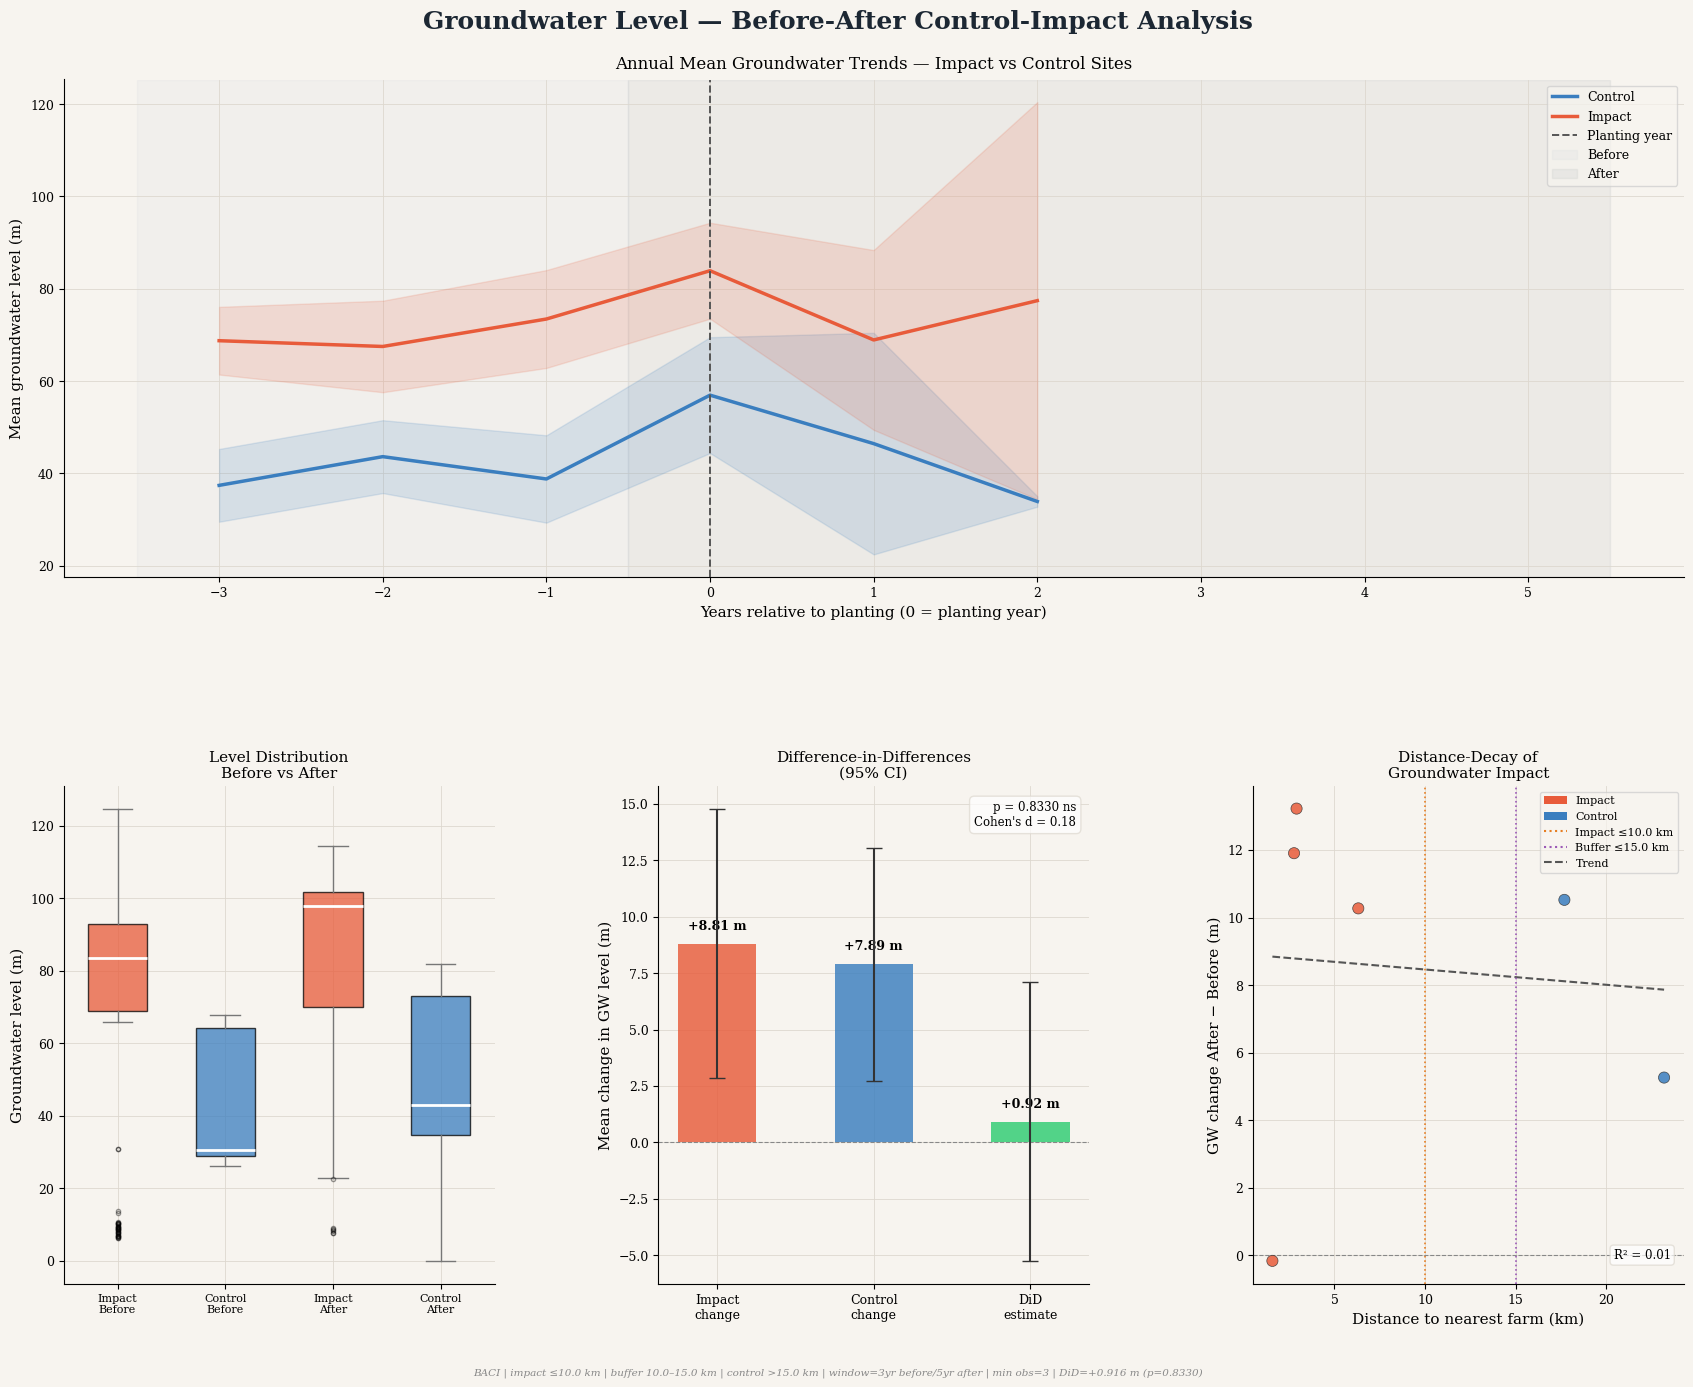


Farms to plot (nearest piezometer): 11
Figure 2 saved → baci_farm_lines.png


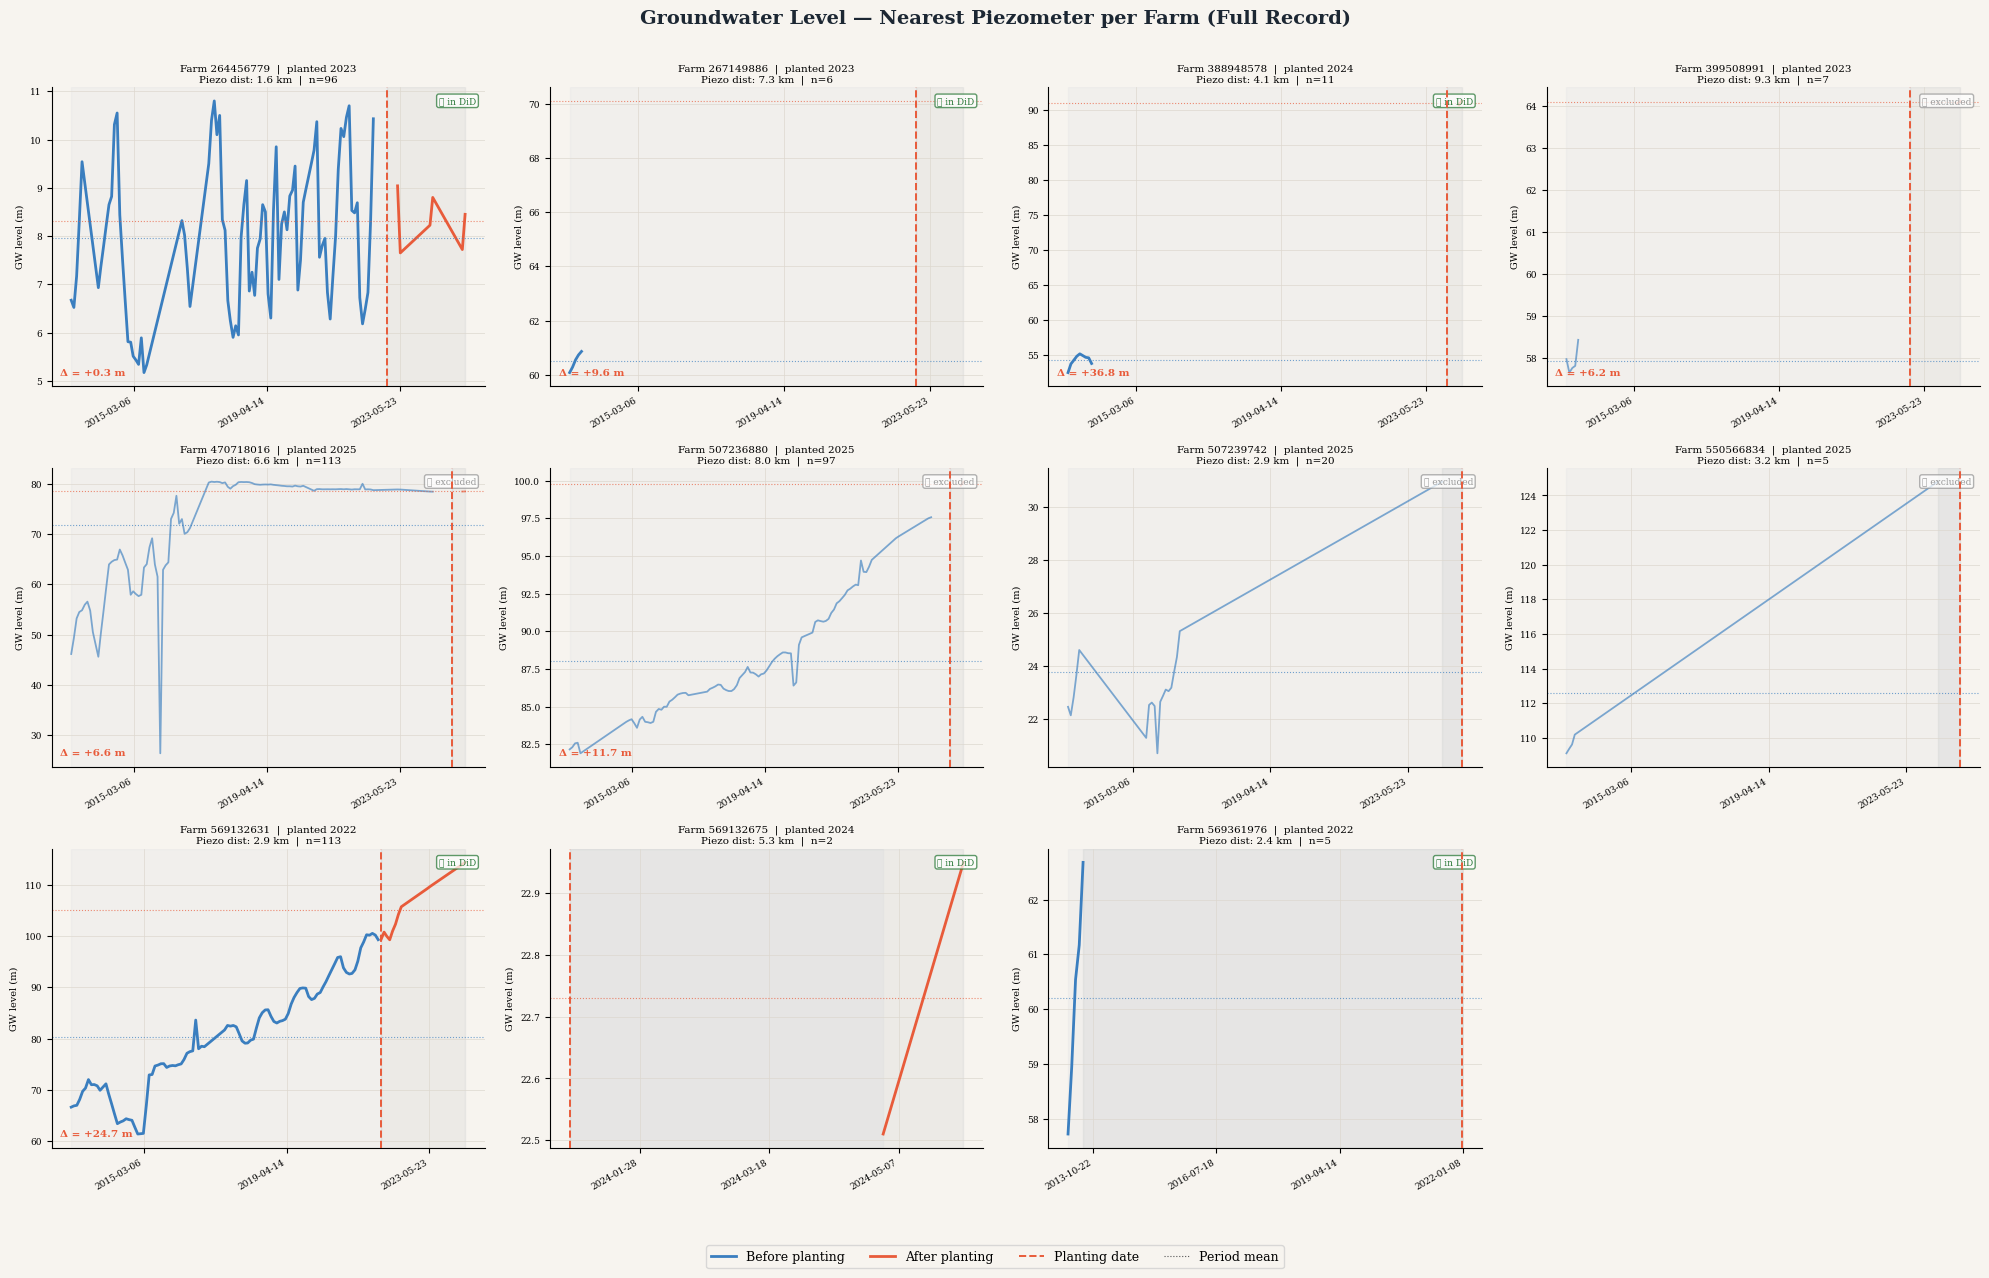


FULL STATISTICAL SUMMARY

  IMPACT SITES
    Before : mean=69.759 m, std=33.586, n=159
    After  : mean=79.134 m, std=34.268, n=49
    Change : +9.375 m
    t-test : t=-1.682, p=0.0965 ns

  CONTROL SITES
    Before : mean=40.421 m, std=16.676, n=46
    After  : mean=50.898 m, std=23.324, n=18
    Change : +10.477 m
    t-test : t=-1.740, p=0.0947 ns

  DIFFERENCE-IN-DIFFERENCES
    DiD estimate  : +0.916 m
    95% CI        : [-5.447, +6.893] m
    t-statistic   : 0.227
    p-value       : 0.8330  ns
    Cohen's d     : 0.181
    N impact      : 4 sites
    N control     : 2 sites

  Interpretation (negative DiD = farms drawing down water):
    A DiD of +0.916 m means impact sites changed by 0.916 m
    LESS than control sites after planting.
    → No evidence of groundwater depletion near farms.



In [21]:
# ============================================================================
# BACI GROUNDWATER ANALYSIS
# Before-After-Control-Impact + Difference-in-Differences
# ============================================================================
# Requires: gw_df (lat, lon, date, gw_level, Nappe)
#           farm_df (lat, lon, planting_year, farm_id, n_trees)
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.colors as mc
import matplotlib.cm as cm
import scipy.stats as stats
from scipy.spatial import cKDTree
from sklearn.linear_model import LinearRegression
import warnings
warnings.filterwarnings("ignore")

# ============================================================================
# CONFIGURATION
# ============================================================================

IMPACT_RADIUS_KM   = 10.0  # piezometers within this = Impact
BUFFER_RADIUS_KM   = 15.0  # piezometers between impact & buffer = Excluded
#                            piezometers beyond buffer = Control
BEFORE_WINDOW_YRS  = 3     # years before planting to include
AFTER_WINDOW_YRS   = 5     # years after planting to include
MIN_OBS_PER_PERIOD = 3     # min monthly obs needed per period

# ── Aesthetic config ──────────────────────────────────────────────────────────
CLR_IMPACT  = "#E85B3A"
CLR_CONTROL = "#3A7EBF"
CLR_BEFORE  = "#A8B8C8"
CLR_AFTER   = "#2C3E50"
BG          = "#F7F4EF"
GRID_CLR    = "#DDD8CF"

plt.rcParams.update({
    "font.family":       "serif",
    "font.serif":        ["Georgia", "Times New Roman", "DejaVu Serif"],
    "axes.facecolor":    BG,
    "figure.facecolor":  BG,
    "axes.grid":         True,
    "grid.color":        GRID_CLR,
    "grid.linewidth":    0.6,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.labelsize":    11,
    "xtick.labelsize":   9,
    "ytick.labelsize":   9,
})

GRP_CLR = {"Impact": CLR_IMPACT, "Control": CLR_CONTROL}

# ============================================================================
# STEP 1 — ASSIGN PIEZOMETERS TO NEAREST FARM & LABEL IMPACT / CONTROL
# ============================================================================

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    φ1, φ2 = np.radians(lat1), np.radians(lat2)
    dφ = np.radians(lat2 - lat1)
    dλ = np.radians(lon2 - lon1)
    a = np.sin(dφ/2)**2 + np.cos(φ1)*np.cos(φ2)*np.sin(dλ/2)**2
    return R * 2 * np.arcsin(np.sqrt(a))

piezo_locs = (
    gw_df[["lat","lon"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

farm_arr  = farm_df[["lat","lon"]].values
piezo_arr = piezo_locs[["lat","lon"]].values

tree = cKDTree(farm_arr)
_, idxs = tree.query(piezo_arr, k=1)

piezo_locs["nearest_farm_idx"] = idxs
piezo_locs["nearest_farm_id"]  = farm_df["farm_id"].iloc[idxs].values
piezo_locs["planting_year"]    = farm_df["planting_year"].iloc[idxs].values
piezo_locs["dist_km"] = [
    haversine_km(piezo_arr[i,0], piezo_arr[i,1],
                 farm_arr[idxs[i],0], farm_arr[idxs[i],1])
    for i in range(len(piezo_locs))
]

# Buffer zone: exclude ambiguous middle-distance piezometers
piezo_locs["group"] = np.where(
    piezo_locs["dist_km"] <= IMPACT_RADIUS_KM, "Impact",
    np.where(piezo_locs["dist_km"] >= BUFFER_RADIUS_KM, "Control", "Excluded")
)

print("=" * 60)
print("PIEZOMETER CLASSIFICATION")
print("=" * 60)
print(piezo_locs[["lat","lon","nearest_farm_id","dist_km","planting_year","group"]]
      .sort_values("dist_km").to_string(index=False))
print(f"\nImpact sites  : {(piezo_locs['group']=='Impact').sum()}")
print(f"Excluded (buf): {(piezo_locs['group']=='Excluded').sum()}")
print(f"Control sites : {(piezo_locs['group']=='Control').sum()}")

# ============================================================================
# STEP 2 — MERGE, FILTER, TEMPORAL ALIGNMENT
# ============================================================================

gw = gw_df.merge(
    piezo_locs[["lat","lon","group","planting_year","dist_km","nearest_farm_id"]],
    on=["lat","lon"], how="left"
)

# Drop buffer zone
gw = gw[gw["group"] != "Excluded"].copy()

# Relative year aligned to each site's nearest farm planting year
gw["rel_year"] = gw["date"].dt.year - gw["planting_year"]
gw["period"]   = np.where(gw["rel_year"] < 0, "Before", "After")

# Keep only within analysis windows
gw = gw[
    (gw["rel_year"] >= -BEFORE_WINDOW_YRS) &
    (gw["rel_year"] <=  AFTER_WINDOW_YRS)
].copy()

# ── Drop sites where planting is too recent for MIN_OBS_PER_PERIOD after data ──
latest_date = gw["date"].max()

def months_of_after_data(planting_year):
    return (latest_date.year - planting_year) * 12 + latest_date.month

gw["months_after_available"] = gw["planting_year"].apply(months_of_after_data)
gw = gw[gw["months_after_available"] >= MIN_OBS_PER_PERIOD].copy()

print(f"\nRecords in analysis window (after filters): {len(gw):,}")
print(gw.groupby(["group","period"])["gw_level"].describe().round(3))

# ============================================================================
# DIAGNOSTIC — show why sites pass/fail
# ============================================================================

diag = []
for (lat, lon, group), sub in gw.groupby(["lat","lon","group"]):
    before = sub[sub["period"]=="Before"]["gw_level"].dropna()
    after  = sub[sub["period"]=="After"]["gw_level"].dropna()
    diag.append({
        "lat": lat, "lon": lon, "group": group,
        "planting_year": sub["planting_year"].iloc[0],
        "dist_km": sub["dist_km"].iloc[0],
        "n_before": len(before), "n_after": len(after),
        "passes": len(before) >= MIN_OBS_PER_PERIOD and len(after) >= MIN_OBS_PER_PERIOD
    })

diag_df = pd.DataFrame(diag).sort_values(["group","n_after"], ascending=[True,False])
print(f"\nSite filter summary (MIN_OBS={MIN_OBS_PER_PERIOD}):")
print(diag_df[["group","planting_year","dist_km","n_before","n_after","passes"]]
      .to_string(index=False))
print(f"\nPasses: {diag_df['passes'].sum()} / {len(diag_df)}")

# ============================================================================
# STEP 3 — SITE-LEVEL BEFORE/AFTER MEANS
# ============================================================================

site_stats = []

for (lat, lon, group), sub in gw.groupby(["lat","lon","group"]):
    before = sub[sub["period"]=="Before"]["gw_level"].dropna()
    after  = sub[sub["period"]=="After"]["gw_level"].dropna()

    if len(before) < MIN_OBS_PER_PERIOD or len(after) < MIN_OBS_PER_PERIOD:
        continue

    site_stats.append({
        "lat":          lat,
        "lon":          lon,
        "group":        group,
        "dist_km":      sub["dist_km"].iloc[0],
        "planting_year": int(sub["planting_year"].iloc[0]),
        "nearest_farm_id": sub["nearest_farm_id"].iloc[0],
        "mean_before":  before.mean(),
        "mean_after":   after.mean(),
        "std_before":   before.std(),
        "std_after":    after.std(),
        "n_before":     len(before),
        "n_after":      len(after),
        "change":       after.mean() - before.mean(),
    })

site_df = pd.DataFrame(site_stats)
print(f"\nSites with sufficient data: {len(site_df)}")
print(site_df[["group","planting_year","dist_km","mean_before",
               "mean_after","change","n_before","n_after"]]
      .to_string(index=False))

# ============================================================================
# STEP 4 — DIFFERENCE-IN-DIFFERENCES
# ============================================================================

imp = site_df[site_df["group"]=="Impact"]["change"]
ctl = site_df[site_df["group"]=="Control"]["change"]

did = imp.mean() - ctl.mean()
t_stat, p_val = stats.ttest_ind(imp, ctl, equal_var=False)

pooled_std = np.sqrt((imp.std()**2 + ctl.std()**2) / 2)
cohens_d   = did / pooled_std if pooled_std > 0 else np.nan

np.random.seed(42)
boot_dids = [
    np.random.choice(imp, len(imp), replace=True).mean() -
    np.random.choice(ctl, len(ctl), replace=True).mean()
    for _ in range(5000)
]
ci_lo, ci_hi = np.percentile(boot_dids, [2.5, 97.5])

print("\n" + "=" * 60)
print("DIFFERENCE-IN-DIFFERENCES RESULTS")
print("=" * 60)
print(f"  Impact mean change   : {imp.mean():+.3f} m")
print(f"  Control mean change  : {ctl.mean():+.3f} m")
print(f"  DiD estimate         : {did:+.3f} m")
print(f"  95% CI               : [{ci_lo:+.3f}, {ci_hi:+.3f}] m")
print(f"  t-statistic          : {t_stat:.3f}")
print(f"  p-value              : {p_val:.4f}  {'***' if p_val<0.001 else '**' if p_val<0.01 else '*' if p_val<0.05 else 'ns'}")
print(f"  Cohen's d            : {cohens_d:.3f}")
print(f"  N impact sites       : {len(imp)}")
print(f"  N control sites      : {len(ctl)}")

# ============================================================================
# STEP 5 — AGGREGATE TRENDS
# ============================================================================

trend = (
    gw.groupby(["group","rel_year"])["gw_level"]
    .agg(mean="mean", se=lambda x: x.std()/np.sqrt(len(x)))
    .reset_index()
)

# Per-farm aggregate (for individual farm lines plot)
farm_trend = (
    gw[gw["group"]=="Impact"]
    .groupby(["nearest_farm_id","planting_year","rel_year"])["gw_level"]
    .agg(mean="mean", se=lambda x: x.std()/np.sqrt(len(x)), n="count")
    .reset_index()
)

# ============================================================================
# FIGURE 1 — MAIN BACI SUMMARY (4 panels)
# ============================================================================

fig1 = plt.figure(figsize=(18, 14), facecolor=BG)
fig1.suptitle(
    "Groundwater Level — Before-After Control-Impact Analysis",
    fontsize=18, fontweight="bold", y=0.98,
    fontfamily="serif", color="#1C2733"
)

gs = gridspec.GridSpec(
    2, 3, figure=fig1,
    hspace=0.42, wspace=0.38,
    left=0.07, right=0.97,
    top=0.93, bottom=0.07
)

ax_ts   = fig1.add_subplot(gs[0, :])
ax_box  = fig1.add_subplot(gs[1, 0])
ax_did  = fig1.add_subplot(gs[1, 1])
ax_dist = fig1.add_subplot(gs[1, 2])

# ── 1A  TIME SERIES ──────────────────────────────────────────────────────────
ax = ax_ts
for grp, sub in trend.groupby("group"):
    clr = GRP_CLR[grp]
    sub = sub.sort_values("rel_year")
    ax.plot(sub["rel_year"], sub["mean"], color=clr, lw=2.5,
            label=grp, zorder=3)
    ax.fill_between(sub["rel_year"],
                    sub["mean"] - 1.96*sub["se"],
                    sub["mean"] + 1.96*sub["se"],
                    color=clr, alpha=0.15, zorder=2)

ax.axvline(0, color="#555", lw=1.4, ls="--", label="Planting year", zorder=4)
ax.axvspan(-BEFORE_WINDOW_YRS-0.5, -0.5, color=CLR_BEFORE, alpha=0.07, label="Before")
ax.axvspan(-0.5, AFTER_WINDOW_YRS+0.5, color=CLR_AFTER,  alpha=0.05, label="After")
ax.set_xlabel("Years relative to planting (0 = planting year)")
ax.set_ylabel("Mean groundwater level (m)")
ax.set_title("Annual Mean Groundwater Trends — Impact vs Control Sites",
             fontsize=12, pad=8)
ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
ax.legend(framealpha=0.7, fontsize=9, loc="best")

# ── 1B  BOXPLOT ───────────────────────────────────────────────────────────────
ax = ax_box
box_data, box_labels, box_colors = [], [], []
for period in ["Before","After"]:
    for grp in ["Impact","Control"]:
        vals = gw[(gw["period"]==period)&(gw["group"]==grp)]["gw_level"].dropna()
        box_data.append(vals); box_labels.append(f"{grp}\n{period}")
        box_colors.append(GRP_CLR[grp])

bp = ax.boxplot(box_data, patch_artist=True, widths=0.55,
                medianprops=dict(color="white", lw=2),
                whiskerprops=dict(color="#777"), capprops=dict(color="#777"),
                flierprops=dict(marker="o", markersize=3, linestyle="none", alpha=0.4))
for patch, clr in zip(bp["boxes"], box_colors):
    patch.set_facecolor(clr); patch.set_alpha(0.75)
ax.set_xticks(range(1, len(box_labels)+1))
ax.set_xticklabels(box_labels, fontsize=8)
ax.set_ylabel("Groundwater level (m)")
ax.set_title("Level Distribution\nBefore vs After", fontsize=11)

# ── 1C  DiD BAR ───────────────────────────────────────────────────────────────
ax = ax_did
changes = [imp.mean(), ctl.mean(), did]
labels  = ["Impact\nchange", "Control\nchange", "DiD\nestimate"]
colors  = [CLR_IMPACT, CLR_CONTROL, "#2ECC71" if did > 0 else "#E74C3C"]
ci_vals = [imp.std()/np.sqrt(len(imp))*1.96,
           ctl.std()/np.sqrt(len(ctl))*1.96,
           (ci_hi-ci_lo)/2]
bars = ax.bar(labels, changes, color=colors, alpha=0.82, width=0.5, zorder=3)
ax.errorbar(labels, changes, yerr=ci_vals,
            fmt="none", color="#333", capsize=6, lw=1.5, zorder=4)
ax.axhline(0, color="#888", lw=0.8, ls="--")
for bar, val in zip(bars, changes):
    ax.text(bar.get_x()+bar.get_width()/2,
            val+(0.5 if val>=0 else -0.5),
            f"{val:+.2f} m",
            ha="center", va="bottom" if val>=0 else "top",
            fontsize=9, fontweight="bold")
sig_label = (f"p = {p_val:.4f} "
             f"{'***' if p_val<0.001 else '**' if p_val<0.01 else '*' if p_val<0.05 else 'ns'}\n"
             f"Cohen's d = {cohens_d:.2f}")
ax.text(0.97, 0.97, sig_label, transform=ax.transAxes,
        ha="right", va="top", fontsize=8.5,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white",
                  alpha=0.7, edgecolor=GRID_CLR))
ax.set_ylabel("Mean change in GW level (m)")
ax.set_title("Difference-in-Differences\n(95% CI)", fontsize=11)

# ── 1D  DISTANCE DECAY ────────────────────────────────────────────────────────
ax = ax_dist
ax.scatter(site_df["dist_km"], site_df["change"],
           c=site_df["group"].map(GRP_CLR),
           s=65, alpha=0.85, edgecolors="#333", lw=0.5, zorder=3)
if len(site_df) > 3:
    X = site_df["dist_km"].values.reshape(-1,1)
    y = site_df["change"].values
    reg = LinearRegression().fit(X, y)
    xs = np.linspace(site_df["dist_km"].min(), site_df["dist_km"].max(), 100)
    ax.plot(xs, reg.predict(xs.reshape(-1,1)),
            color="#555", lw=1.5, ls="--", zorder=2)
    r2 = reg.score(X, y)
    ax.text(0.97, 0.05, f"R² = {r2:.2f}", transform=ax.transAxes,
            ha="right", fontsize=8.5,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                      alpha=0.7, edgecolor=GRID_CLR))
ax.axvline(IMPACT_RADIUS_KM, color="#E67E22", lw=1.2, ls=":",
           label=f"Impact ≤{IMPACT_RADIUS_KM} km")
ax.axvline(BUFFER_RADIUS_KM, color="#9B59B6", lw=1.2, ls=":",
           label=f"Buffer ≤{BUFFER_RADIUS_KM} km")
ax.axhline(0, color="#888", lw=0.8, ls="--")
ax.set_xlabel("Distance to nearest farm (km)")
ax.set_ylabel("GW change After − Before (m)")
ax.set_title("Distance-Decay of\nGroundwater Impact", fontsize=11)
ax.legend(handles=[
    Patch(facecolor=CLR_IMPACT,  label="Impact"),
    Patch(facecolor=CLR_CONTROL, label="Control"),
    Line2D([0],[0], color="#E67E22", ls=":", label=f"Impact ≤{IMPACT_RADIUS_KM} km"),
    Line2D([0],[0], color="#9B59B6", ls=":", label=f"Buffer ≤{BUFFER_RADIUS_KM} km"),
    Line2D([0],[0], color="#555",    ls="--", label="Trend"),
], fontsize=8, framealpha=0.7)

caption = (
    f"BACI | impact ≤{IMPACT_RADIUS_KM} km | buffer {IMPACT_RADIUS_KM}–{BUFFER_RADIUS_KM} km | "
    f"control >{BUFFER_RADIUS_KM} km | window={BEFORE_WINDOW_YRS}yr before/{AFTER_WINDOW_YRS}yr after | "
    f"min obs={MIN_OBS_PER_PERIOD} | DiD={did:+.3f} m (p={p_val:.4f})"
)
fig1.text(0.5, 0.005, caption, ha="center", fontsize=7.5,
          color="#888", style="italic")

plt.savefig("baci_groundwater.png", dpi=180, bbox_inches="tight", facecolor=BG)
print("\nFigure 1 saved → baci_groundwater.png")
plt.show()

# ============================================================================
# FIGURE 2 — NEAREST PIEZOMETER PER FARM (all farms, absolute dates)
# Uses gw_df directly so NO window/filter restrictions apply
# ============================================================================

# Build full (unfiltered) gw with group labels for all impact farms
gw_full = gw_df.merge(
    piezo_locs[["lat","lon","group","planting_year","dist_km","nearest_farm_id"]],
    on=["lat","lon"], how="left"
).dropna(subset=["nearest_farm_id"])

# For each farm pick the single nearest piezometer
nearest_piezo = (
    piezo_locs[piezo_locs["group"]=="Impact"]
    .sort_values("dist_km")
    .groupby("nearest_farm_id")
    .first()
    .reset_index()[["nearest_farm_id","lat","lon","dist_km","planting_year"]]
)

# All farms that have a farm_id in farm_df (not just those with enough data)
all_farm_ids = sorted(nearest_piezo["nearest_farm_id"].unique())
n_farms      = len(all_farm_ids)

print(f"\nFarms to plot (nearest piezometer): {n_farms}")

if n_farms == 0:
    print("No impact farms to plot.")
else:
    ncols = min(4, n_farms)
    nrows = int(np.ceil(n_farms / ncols))
    fw    = ncols * 5.0
    fh    = nrows * 3.8

    fig2, axes = plt.subplots(
        nrows, ncols,
        figsize=(fw, fh + 1.0),
        facecolor=BG, squeeze=False
    )
    fig2.suptitle(
        "Groundwater Level — Nearest Piezometer per Farm (Full Record)",
        fontsize=14, fontweight="bold", y=1.005,
        fontfamily="serif", color="#1C2733"
    )

    for ax_idx, farm_id in enumerate(all_farm_ids):
        row, col = divmod(ax_idx, ncols)
        ax = axes[row][col]
        ax.set_facecolor(BG)

        # Get nearest piezometer info for this farm
        piezo_row = nearest_piezo[nearest_piezo["nearest_farm_id"]==farm_id]
        if piezo_row.empty:
            ax.set_visible(False)
            continue

        p_lat      = piezo_row["lat"].iloc[0]
        p_lon      = piezo_row["lon"].iloc[0]
        dist       = piezo_row["dist_km"].iloc[0]
        plant_yr   = int(piezo_row["planting_year"].iloc[0])
        plant_date = pd.Timestamp(year=plant_yr, month=1, day=1)

        # Pull full time series for this piezometer (no window filter)
        ts = (gw_full[(gw_full["lat"]==p_lat) & (gw_full["lon"]==p_lon)]
              .sort_values("date")[["date","gw_level"]]
              .dropna(subset=["gw_level"]))

        if ts.empty:
            ax.text(0.5, 0.5, "No data", transform=ax.transAxes,
                    ha="center", va="center", color="#888", fontsize=9)
            ax.set_title(f"Farm {farm_id}\n(planted {plant_yr})", fontsize=8)
            continue

        # Split before / after planting
        before = ts[ts["date"] <  plant_date]
        after  = ts[ts["date"] >= plant_date]

        in_did = farm_id in site_df["nearest_farm_id"].values
        lw_val = 2.0 if in_did else 1.3
        alpha_val = 1.0 if in_did else 0.65

        if not before.empty:
            ax.plot(before["date"], before["gw_level"],
                    color=CLR_CONTROL, lw=lw_val, alpha=alpha_val,
                    label="Before")
        if not after.empty:
            ax.plot(after["date"], after["gw_level"],
                    color=CLR_IMPACT, lw=lw_val, alpha=alpha_val,
                    label="After")

        # Before/after means as horizontal dashed lines
        if not before.empty:
            ax.axhline(before["gw_level"].mean(), color=CLR_CONTROL,
                       lw=0.8, ls=":", alpha=0.7)
        if not after.empty:
            ax.axhline(after["gw_level"].mean(), color=CLR_IMPACT,
                       lw=0.8, ls=":", alpha=0.7)

        # Planting line
        ax.axvline(plant_date, color="#E85B3A", lw=1.4, ls="--", zorder=4)

        # Shade periods
        x_min = ts["date"].min()
        x_max = ts["date"].max()
        ax.axvspan(x_min, plant_date, color=CLR_BEFORE, alpha=0.07)
        ax.axvspan(plant_date, x_max, color=CLR_AFTER,  alpha=0.05)

        # DiD badge
        did_tag = "✓ in DiD" if in_did else "✗ excluded"
        did_clr = "#2C7A3A" if in_did else "#999"
        ax.text(0.98, 0.97, did_tag,
                transform=ax.transAxes, ha="right", va="top",
                fontsize=6.5, color=did_clr,
                bbox=dict(boxstyle="round,pad=0.25", facecolor="white",
                          alpha=0.75, edgecolor=did_clr))

        # Before→after change annotation
        if not before.empty and not after.empty:
            chg = after["gw_level"].mean() - before["gw_level"].mean()
            ax.text(0.02, 0.03, f"Δ = {chg:+.1f} m",
                    transform=ax.transAxes, ha="left", va="bottom",
                    fontsize=7.5, fontweight="bold",
                    color=CLR_IMPACT if chg > 0 else CLR_CONTROL)

        ax.set_title(
            f"Farm {farm_id}  |  planted {plant_yr}\n"
            f"Piezo dist: {dist:.1f} km  |  n={len(ts)}",
            fontsize=7.5, pad=4
        )
        ax.set_ylabel("GW level (m)", fontsize=7)
        ax.tick_params(labelsize=6.5)
        ax.xaxis.set_major_locator(
            mticker.MaxNLocator(nbins=4, integer=False)
        )
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
        ax.grid(color=GRID_CLR, lw=0.5)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    # Hide unused panels
    for ax_idx in range(n_farms, nrows * ncols):
        row, col = divmod(ax_idx, ncols)
        axes[row][col].set_visible(False)

    # Shared legend
    fig2.legend(
        handles=[
            Line2D([0],[0], color=CLR_CONTROL, lw=2, label="Before planting"),
            Line2D([0],[0], color=CLR_IMPACT,  lw=2, label="After planting"),
            Line2D([0],[0], color="#E85B3A", lw=1.4, ls="--", label="Planting date"),
            Line2D([0],[0], color="#555",    lw=0.8, ls=":",  label="Period mean"),
        ],
        loc="lower center", ncol=4, fontsize=9,
        framealpha=0.7, bbox_to_anchor=(0.5, -0.015)
    )

    plt.tight_layout(rect=[0, 0.04, 1, 1])
    plt.savefig("baci_farm_lines.png", dpi=180,
                bbox_inches="tight", facecolor=BG)
    print("Figure 2 saved → baci_farm_lines.png")
    plt.show()

# ============================================================================
# FULL STATISTICAL SUMMARY
# ============================================================================

print("\n" + "=" * 60)
print("FULL STATISTICAL SUMMARY")
print("=" * 60)

for grp in ["Impact","Control"]:
    sub = gw[gw["group"]==grp]
    b = sub[sub["period"]=="Before"]["gw_level"].dropna()
    a = sub[sub["period"]=="After"]["gw_level"].dropna()
    t, p = stats.ttest_ind(b, a, equal_var=False)
    print(f"\n  {grp.upper()} SITES")
    print(f"    Before : mean={b.mean():.3f} m, std={b.std():.3f}, n={len(b)}")
    print(f"    After  : mean={a.mean():.3f} m, std={a.std():.3f}, n={len(a)}")
    print(f"    Change : {a.mean()-b.mean():+.3f} m")
    print(f"    t-test : t={t:.3f}, p={p:.4f} "
          f"{'***' if p<0.001 else '**' if p<0.01 else '*' if p<0.05 else 'ns'}")

print(f"""
  DIFFERENCE-IN-DIFFERENCES
    DiD estimate  : {did:+.3f} m
    95% CI        : [{ci_lo:+.3f}, {ci_hi:+.3f}] m
    t-statistic   : {t_stat:.3f}
    p-value       : {p_val:.4f}  {'***' if p_val<0.001 else '**' if p_val<0.01 else '*' if p_val<0.05 else 'ns'}
    Cohen's d     : {cohens_d:.3f}
    N impact      : {len(imp)} sites
    N control     : {len(ctl)} sites

  Interpretation (negative DiD = farms drawing down water):
    A DiD of {did:+.3f} m means impact sites changed by {abs(did):.3f} m
    {'MORE' if did < 0 else 'LESS'} than control sites after planting.
    {'→ Consistent with groundwater DEPLETION near farms.' if did < 0
     else '→ No evidence of groundwater depletion near farms.'}
""")

REGIONAL TREND (from control piezometers)
  Slope  : +2.3052 m/yr  (p=0.0000)
  R²     : 0.231
  N obs  : 82
  N sites: 6

DETRENDED ITS RESULTS
 nearest_farm  planting_year  dist_km  slope_b_yr  slope_a_yr  slope_change_yr  level_shift    p_b    p_a  n_b  n_a
    264456779           2023   +1.571      -2.225      -2.435           -0.210       -0.037 +0.000 +0.001   44    6
    569132675           2024   +6.314      +3.062      -2.928           -5.990       -0.338 +0.000 +0.015   34    4
    569361976           2022   +2.766      +2.825      +3.107           +0.282       -0.648 +0.000 +0.000   48   12
    569132631           2022   +2.905      +2.862      +4.082           +1.220       -0.176 +0.000 +0.000   48   12

  Regional trend removed : +2.3052 m/yr
  Mean slope BEFORE      : +1.631 m/yr (detrended)
  Mean slope AFTER       : +0.456 m/yr (detrended)
  Mean slope CHANGE      : -1.175 m/yr
  Slope-change t-test    : t=-0.720, p=0.5238 ns
  Mean level shift       : -0.300 m
  Level-

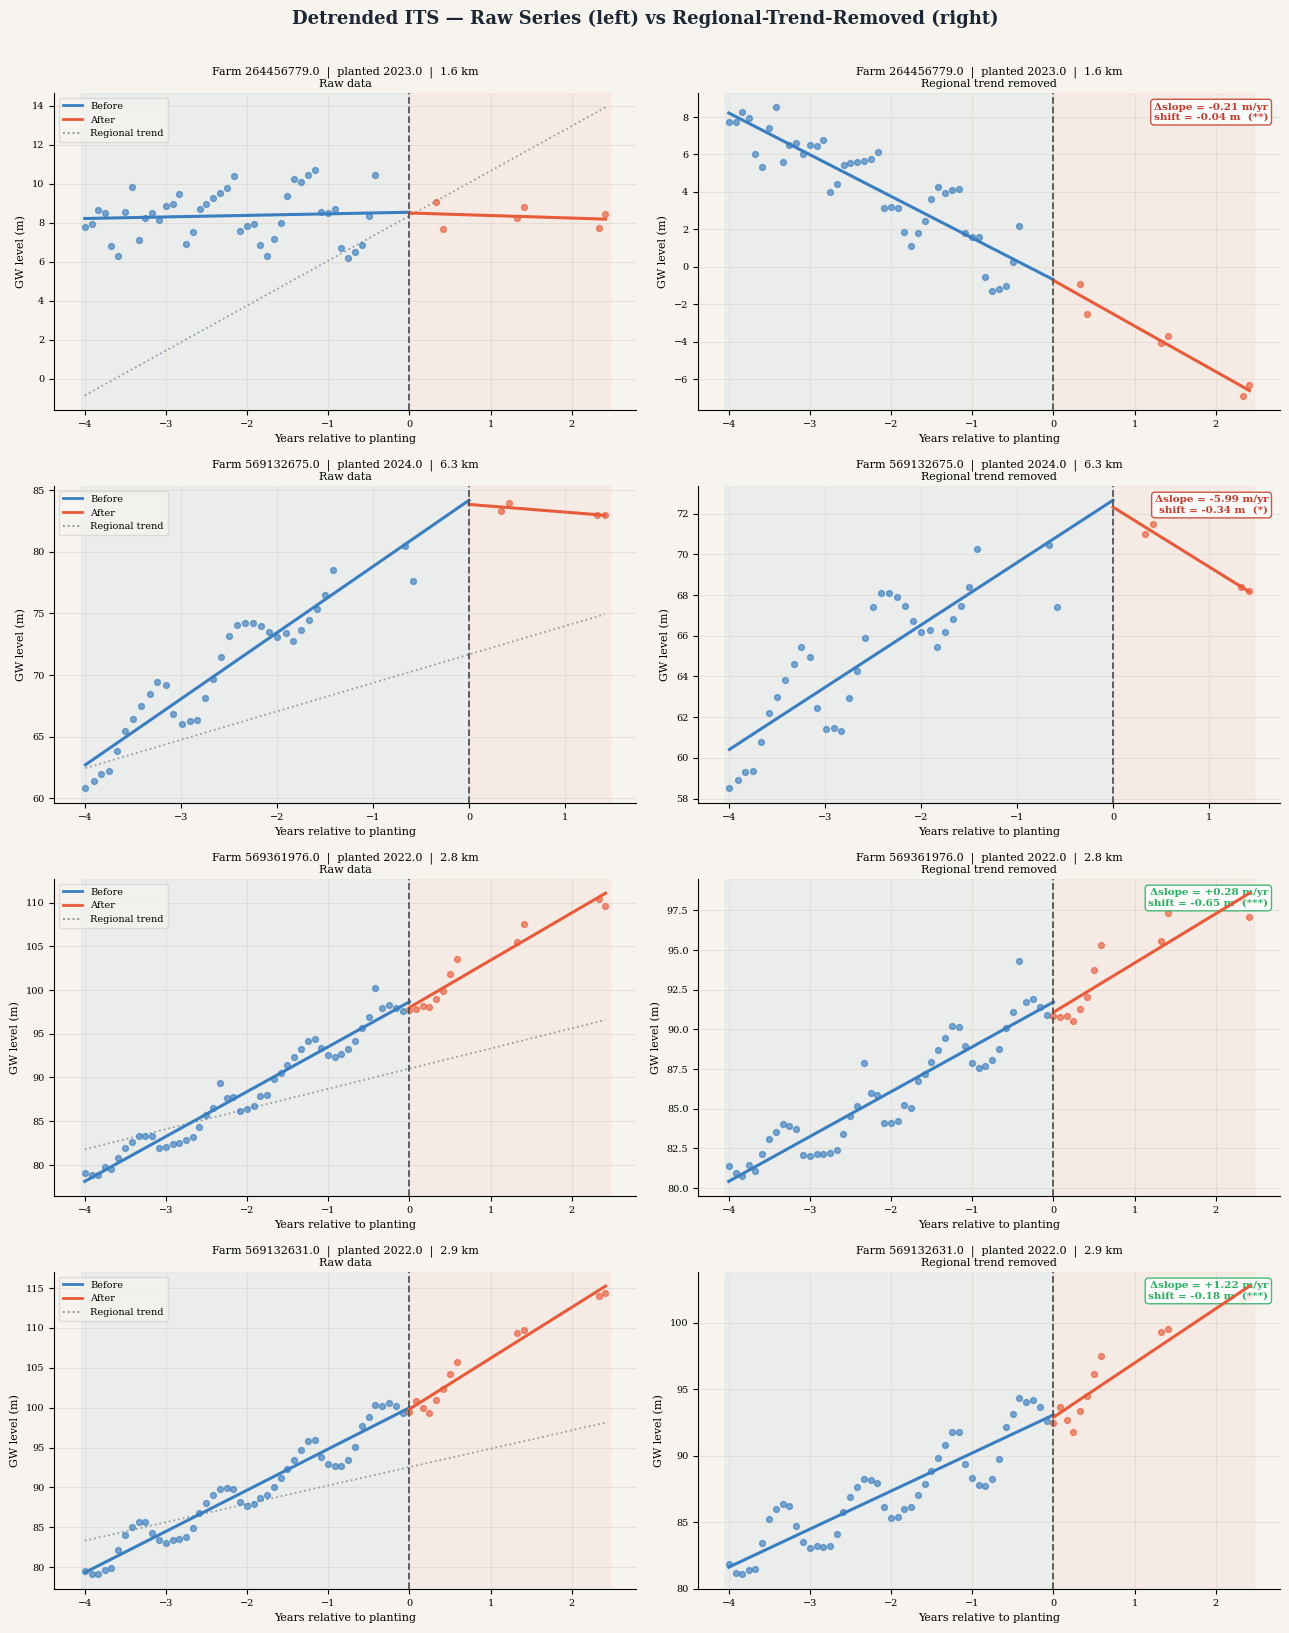

Figure 2 saved → its_summary.png


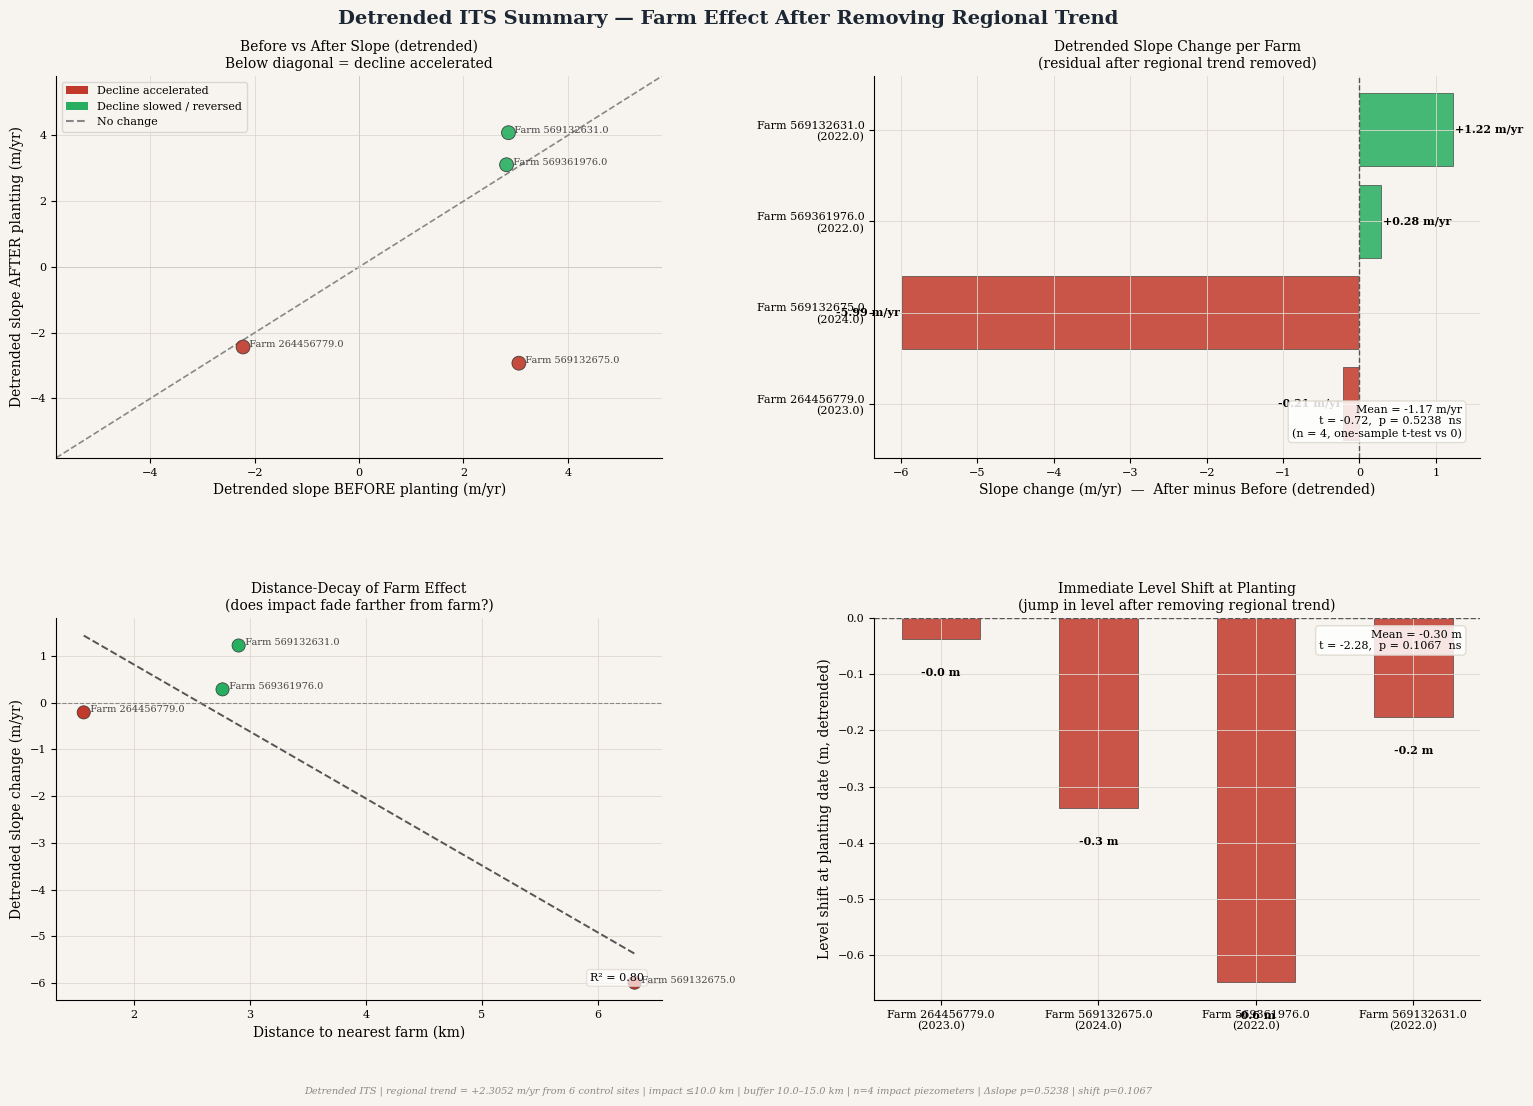


FULL STATISTICAL SUMMARY

REGIONAL TREND (control piezometers, n=6):
  Slope : +2.3052 m/yr  (R²=0.231, p=0.0000)
  Interpretation: this is the background regional trend in GW levels
  shared across all sites (climate / drought / seasonal).
  It has been SUBTRACTED from impact sites before ITS fitting.

DETRENDED ITS — SLOPE CHANGE:
  Mean before : +1.631 m/yr
  Mean after  : +0.456 m/yr
  Mean change : -1.175 m/yr
  t = -0.720,  p = 0.5238  ns
  (H0: mean slope change = 0 after removing regional trend)

DETRENDED ITS — LEVEL SHIFT:
  Mean shift  : -0.300 m
  t = -2.283,  p = 0.1067  ns

INTERPRETATION:
  Negative slope change → GW decline ACCELERATED beyond regional trend
  Positive slope change → GW decline SLOWED relative to regional trend
  → Evidence of farm-driven depletion beyond regional trend.

CAVEATS (be explicit about these):
  - n=4 impact piezometers: low statistical power, treat p-values
    as indicative rather than confirmatory.
  - Control sites may also be near non-

In [7]:
# ============================================================================
# DETRENDED INTERRUPTED TIME SERIES (ITS) — GROUNDWATER ANALYSIS
# Control group used to remove regional trend before testing farm effect
# ============================================================================
# Requires: gw_df  (lat, lon, date, gw_level)
#           farm_df (lat, lon, planting_year, farm_id, n_trees)
#           piezo_locs — rebuilt automatically if not in scope
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import scipy.stats as stats
from scipy.stats import linregress
from scipy.spatial import cKDTree
from sklearn.linear_model import LinearRegression
import warnings
warnings.filterwarnings("ignore")

# ============================================================================
# CONFIGURATION
# ============================================================================

IMPACT_RADIUS_KM  = 10.0
BUFFER_RADIUS_KM  = 15.0
MIN_OBS_PERIOD    = 4
TREND_WINDOW_YRS  = 4

BG       = "#F7F4EF"
GRID_CLR = "#DDD8CF"
CLR_B    = "#3A7EBF"
CLR_A    = "#E85B3A"
CLR_CTL  = "#7F8C8D"
CLR_DROP = "#C0392B"
CLR_RISE = "#27AE60"

plt.rcParams.update({
    "font.family":       "serif",
    "font.serif":        ["Georgia", "Times New Roman", "DejaVu Serif"],
    "axes.facecolor":    BG,
    "figure.facecolor":  BG,
    "axes.grid":         True,
    "grid.color":        GRID_CLR,
    "grid.linewidth":    0.6,
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.labelsize":    10,
    "xtick.labelsize":   8,
    "ytick.labelsize":   8,
})

# ============================================================================
# STEP 1 — REBUILD PIEZO LABELS
# ============================================================================

def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    φ1, φ2 = np.radians(lat1), np.radians(lat2)
    dφ, dλ = np.radians(lat2 - lat1), np.radians(lon2 - lon1)
    a = np.sin(dφ/2)**2 + np.cos(φ1)*np.cos(φ2)*np.sin(dλ/2)**2
    return R * 2 * np.arcsin(np.sqrt(a))

try:
    _ = piezo_locs
    print("Reusing piezo_locs from BACI run.")
except NameError:
    piezo_locs = gw_df[["lat","lon"]].drop_duplicates().reset_index(drop=True)
    farm_arr   = farm_df[["lat","lon"]].values
    piezo_arr  = piezo_locs[["lat","lon"]].values
    tree       = cKDTree(farm_arr)
    _, idxs    = tree.query(piezo_arr, k=1)
    piezo_locs["nearest_farm_id"] = farm_df["farm_id"].iloc[idxs].values
    piezo_locs["planting_year"]   = farm_df["planting_year"].iloc[idxs].values
    piezo_locs["dist_km"]         = [
        haversine_km(piezo_arr[i,0], piezo_arr[i,1],
                     farm_arr[idxs[i],0], farm_arr[idxs[i],1])
        for i in range(len(piezo_locs))
    ]
    piezo_locs["group"] = np.where(
        piezo_locs["dist_km"] <= IMPACT_RADIUS_KM, "Impact",
        np.where(piezo_locs["dist_km"] >= BUFFER_RADIUS_KM, "Control", "Excluded")
    )

# ============================================================================
# STEP 2 — MERGE & PREP
# ============================================================================

gw = gw_df.merge(
    piezo_locs[["lat","lon","group","planting_year","dist_km","nearest_farm_id"]],
    on=["lat","lon"], how="left"
).dropna(subset=["nearest_farm_id"])

gw = gw[gw["group"] != "Excluded"].copy()

gw["plant_date"] = pd.to_datetime(
    gw["planting_year"].astype(int).astype(str) + "-01-01"
)
gw["t_days"] = (gw["date"] - gw["plant_date"]).dt.days
gw["rel_year"] = gw["date"].dt.year - gw["planting_year"]
gw["period"]   = np.where(gw["t_days"] < 0, "Before", "After")

gw_win = gw[
    (gw["rel_year"] >= -TREND_WINDOW_YRS) &
    (gw["rel_year"] <=  TREND_WINDOW_YRS)
].copy()

# ============================================================================
# STEP 3 — BUILD REGIONAL TREND FROM CONTROL SITES
# Fit one pooled linear trend across all control piezometers using
# calendar time (not relative time), then subtract it from impact sites.
# This removes the shared regional signal (drought, seasonal, climate).
# ============================================================================

ctl = gw_win[gw_win["group"] == "Control"].copy()
ctl["t_cal"] = (ctl["date"] - ctl["date"].min()).dt.days.astype(float)

# Normalise each control site to zero-mean so absolute level differences
# don't dominate the slope estimate
ctl_norm = []
for (lat, lon), sub in ctl.groupby(["lat","lon"]):
    s = sub.copy()
    s["gw_norm"] = s["gw_level"] - s["gw_level"].mean()
    ctl_norm.append(s)
ctl_norm = pd.concat(ctl_norm)

sl_r, ic_r, r_r, p_r, _ = linregress(
    ctl_norm["t_cal"].values,
    ctl_norm["gw_norm"].values
)
r2_r = r_r**2

print("=" * 65)
print("REGIONAL TREND (from control piezometers)")
print("=" * 65)
print(f"  Slope  : {sl_r*365.25:+.4f} m/yr  (p={p_r:.4f})")
print(f"  R²     : {r2_r:.3f}")
print(f"  N obs  : {len(ctl_norm)}")
print(f"  N sites: {ctl_norm.groupby(['lat','lon']).ngroups}")

# ── Subtract regional trend from each impact site ────────────────────────────
imp_win = gw_win[gw_win["group"] == "Impact"].copy()

# Calendar reference = same as control
cal_ref = ctl["date"].min()
imp_win["t_cal"] = (imp_win["date"] - cal_ref).dt.days.astype(float)

# Remove regional slope (keep site mean so levels stay interpretable)
imp_win["gw_detrended"] = (
    imp_win["gw_level"] - sl_r * imp_win["t_cal"]
)

# ============================================================================
# STEP 4 — FIT ITS ON DETRENDED SERIES
# ============================================================================

def fit_trend(df, y_col="gw_detrended", x_col="t_days"):
    x = df[x_col].values.astype(float)
    y = df[y_col].values.astype(float)
    mask = ~np.isnan(y)
    if mask.sum() < MIN_OBS_PERIOD:
        return (np.nan,)*4
    sl, ic, r, p, _ = linregress(x[mask], y[mask])
    return sl, ic, r**2, p

its_rows = []

for (lat, lon), sub in imp_win.groupby(["lat","lon"]):
    before = sub[sub["period"] == "Before"].sort_values("t_days")
    after  = sub[sub["period"] == "After"].sort_values("t_days")

    sl_b, ic_b, r2_b, p_b = fit_trend(before)
    sl_a, ic_a, r2_a, p_a = fit_trend(after)

    if np.isnan(sl_b) or np.isnan(sl_a):
        continue

    # Also fit on raw (non-detrended) for display
    sl_b_raw, ic_b_raw, _, _ = fit_trend(before, y_col="gw_level")
    sl_a_raw, ic_a_raw, _, _ = fit_trend(after,  y_col="gw_level")

    its_rows.append({
        "lat":             lat,
        "lon":             lon,
        "nearest_farm":    sub["nearest_farm_id"].iloc[0],
        "planting_year":   int(sub["planting_year"].iloc[0]),
        "dist_km":         sub["dist_km"].iloc[0],
        # Detrended slopes
        "slope_b_yr":      sl_b * 365.25,
        "slope_a_yr":      sl_a * 365.25,
        "slope_change_yr": (sl_a - sl_b) * 365.25,
        "level_shift":     ic_a - ic_b,
        "r2_b": r2_b, "p_b": p_b, "n_b": len(before),
        "r2_a": r2_a, "p_a": p_a, "n_a": len(after),
        # Raw slopes (for trace plot)
        "_ic_b_raw": ic_b_raw, "_sl_b_raw": sl_b_raw,
        "_ic_a_raw": ic_a_raw, "_sl_a_raw": sl_a_raw,
        "_ic_b": ic_b, "_sl_b": sl_b,
        "_ic_a": ic_a, "_sl_a": sl_a,
    })

its_df = pd.DataFrame(its_rows)

# One-sample t-tests (H0: no change beyond regional trend)
t_sc, p_sc = stats.ttest_1samp(its_df["slope_change_yr"].dropna(), 0)
t_ls, p_ls = stats.ttest_1samp(its_df["level_shift"].dropna(), 0)

print("\n" + "=" * 65)
print("DETRENDED ITS RESULTS")
print("=" * 65)
cols = ["nearest_farm","planting_year","dist_km",
        "slope_b_yr","slope_a_yr","slope_change_yr","level_shift",
        "p_b","p_a","n_b","n_a"]
print(its_df[cols].to_string(index=False, float_format="{:+.3f}".format))

print(f"""
  Regional trend removed : {sl_r*365.25:+.4f} m/yr
  Mean slope BEFORE      : {its_df['slope_b_yr'].mean():+.3f} m/yr (detrended)
  Mean slope AFTER       : {its_df['slope_a_yr'].mean():+.3f} m/yr (detrended)
  Mean slope CHANGE      : {its_df['slope_change_yr'].mean():+.3f} m/yr
  Slope-change t-test    : t={t_sc:.3f}, p={p_sc:.4f} {'***' if p_sc<0.001 else '**' if p_sc<0.01 else '*' if p_sc<0.05 else 'ns'}
  Mean level shift       : {its_df['level_shift'].mean():+.3f} m
  Level-shift  t-test    : t={t_ls:.3f}, p={p_ls:.4f} {'***' if p_ls<0.001 else '**' if p_ls<0.01 else '*' if p_ls<0.05 else 'ns'}
  N impact piezometers   : {len(its_df)}
  N control piezometers  : {ctl_norm.groupby(['lat','lon']).ngroups}
""")

# ============================================================================
# FIGURE 1 — INDIVIDUAL TRACES  (raw + detrended side by side)
# ============================================================================

n_sites = len(its_df)
fig1, axes = plt.subplots(
    n_sites, 2,
    figsize=(13, n_sites * 3.8 + 1.0),
    facecolor=BG, squeeze=False
)
fig1.suptitle(
    "Detrended ITS — Raw Series (left) vs Regional-Trend-Removed (right)",
    fontsize=13, fontweight="bold", y=1.005,
    fontfamily="serif", color="#1C2733"
)

for idx, row in its_df.reset_index(drop=True).iterrows():

    sub = imp_win[
        (imp_win["lat"] == row["lat"]) &
        (imp_win["lon"] == row["lon"])
    ].sort_values("t_days")

    before = sub[sub["period"] == "Before"]
    after  = sub[sub["period"] == "After"]

    # Also get control mean trend for overlay on raw plot
    ctl_mean = (
        ctl_norm.groupby("t_cal")["gw_norm"]
        .mean().reset_index().sort_values("t_cal")
    )

    for col_idx, (y_col, ic_b, sl_b, ic_a, sl_a, title_sfx) in enumerate([
        ("gw_level",     row["_ic_b_raw"], row["_sl_b_raw"],
                         row["_ic_a_raw"], row["_sl_a_raw"], "Raw data"),
        ("gw_detrended", row["_ic_b"],     row["_sl_b"],
                         row["_ic_a"],     row["_sl_a"],     "Regional trend removed"),
    ]):
        ax = axes[idx][col_idx]
        ax.set_facecolor(BG)

        ax.scatter(before["t_days"]/365.25, before[y_col],
                   color=CLR_B, s=18, alpha=0.65, zorder=3, label="Before")
        ax.scatter(after["t_days"]/365.25,  after[y_col],
                   color=CLR_A, s=18, alpha=0.65, zorder=3, label="After")

        # Trend lines
        if not np.isnan(sl_b) and len(before) >= MIN_OBS_PERIOD:
            tb = np.linspace(before["t_days"].min(), 0, 80)
            ax.plot(tb/365.25, ic_b + sl_b*tb,
                    color=CLR_B, lw=2.2, zorder=4)
        if not np.isnan(sl_a) and len(after) >= MIN_OBS_PERIOD:
            ta = np.linspace(0, after["t_days"].max(), 80)
            ax.plot(ta/365.25, ic_a + sl_a*ta,
                    color=CLR_A, lw=2.2, zorder=4)

        # On raw plot: overlay normalised control trend as reference
        if col_idx == 0:
            # Scale control to sit near the site's mean level
            site_mean = sub["gw_level"].mean()
            t_ref = (sub["t_days"].values / 365.25)
            ctl_trend_vals = site_mean + sl_r * 365.25 * t_ref
            ax.plot(t_ref, ctl_trend_vals,
                    color=CLR_CTL, lw=1.3, ls=":",
                    alpha=0.8, label="Regional trend")

        ax.axvline(0, color="#555", lw=1.3, ls="--", zorder=5)
        ax.axvspan(before["t_days"].min()/365.25 - 0.05, 0,
                   color=CLR_B, alpha=0.06)
        ax.axvspan(0, after["t_days"].max()/365.25 + 0.05,
                   color=CLR_A, alpha=0.06)

        # Badge (only on detrended panel)
        if col_idx == 1:
            sc  = row["slope_change_yr"]
            clr = CLR_DROP if sc < 0 else CLR_RISE
            sig = ('***' if row['p_a']<0.001 else '**' if row['p_a']<0.01
                   else '*' if row['p_a']<0.05 else 'ns')
            ax.text(0.98, 0.97,
                    f"Δslope = {sc:+.2f} m/yr\n"
                    f"shift = {row['level_shift']:+.2f} m  ({sig})",
                    transform=ax.transAxes, ha="right", va="top",
                    fontsize=7.5, color=clr, fontweight="bold",
                    bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                              alpha=0.85, edgecolor=clr))

        ax.set_xlabel("Years relative to planting", fontsize=8)
        ax.set_ylabel("GW level (m)", fontsize=8)
        ax.set_title(
            f"Farm {row['nearest_farm']}  |  planted {row['planting_year']}  |  "
            f"{row['dist_km']:.1f} km\n{title_sfx}",
            fontsize=8, pad=4
        )
        ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
        ax.tick_params(labelsize=7)
        ax.grid(color=GRID_CLR, lw=0.5)

        if col_idx == 0:
            ax.legend(fontsize=7, framealpha=0.6,
                      handles=[
                          Line2D([0],[0], color=CLR_B,   lw=2, label="Before"),
                          Line2D([0],[0], color=CLR_A,   lw=2, label="After"),
                          Line2D([0],[0], color=CLR_CTL, lw=1.3, ls=":",
                                 label="Regional trend"),
                      ])

plt.tight_layout(rect=[0, 0, 1, 1])
plt.savefig("its_traces.png", dpi=180, bbox_inches="tight", facecolor=BG)
print("Figure 1 saved → its_traces.png")
plt.show()

# ============================================================================
# FIGURE 2 — SUMMARY  (4 panels, no nappe)
# ============================================================================

fig2 = plt.figure(figsize=(16, 11), facecolor=BG)
fig2.suptitle(
    "Detrended ITS Summary — Farm Effect After Removing Regional Trend",
    fontsize=14, fontweight="bold", y=0.99,
    fontfamily="serif", color="#1C2733"
)

gs = gridspec.GridSpec(
    2, 2, figure=fig2,
    hspace=0.42, wspace=0.35,
    left=0.08, right=0.97,
    top=0.93, bottom=0.09
)

ax_scatter = fig2.add_subplot(gs[0, 0])
ax_bar     = fig2.add_subplot(gs[0, 1])
ax_dist    = fig2.add_subplot(gs[1, 0])
ax_shift   = fig2.add_subplot(gs[1, 1])

# ── 2A  BEFORE vs AFTER SLOPE ─────────────────────────────────────────────────
ax = ax_scatter
clrs = [CLR_DROP if sc < 0 else CLR_RISE
        for sc in its_df["slope_change_yr"]]
ax.scatter(its_df["slope_b_yr"], its_df["slope_a_yr"],
           c=clrs, s=100, edgecolors="#333", lw=0.6, zorder=3, alpha=0.9)

lim = max(abs(its_df[["slope_b_yr","slope_a_yr"]].values.flatten())) * 1.3 + 0.5
ax.plot([-lim, lim], [-lim, lim], color="#888", lw=1.2, ls="--")
ax.axhline(0, color="#ccc", lw=0.7)
ax.axvline(0, color="#ccc", lw=0.7)

for _, r in its_df.iterrows():
    ax.annotate(
        f"  Farm {r['nearest_farm']}",
        (r["slope_b_yr"], r["slope_a_yr"]),
        fontsize=7, color="#444"
    )

ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel("Detrended slope BEFORE planting (m/yr)")
ax.set_ylabel("Detrended slope AFTER planting (m/yr)")
ax.set_title("Before vs After Slope (detrended)\nBelow diagonal = decline accelerated",
             fontsize=10)
ax.legend(handles=[
    Patch(facecolor=CLR_DROP, label="Decline accelerated"),
    Patch(facecolor=CLR_RISE, label="Decline slowed / reversed"),
    Line2D([0],[0], color="#888", ls="--", label="No change"),
], fontsize=8, framealpha=0.7)

# ── 2B  SLOPE CHANGE BAR ──────────────────────────────────────────────────────
ax = ax_bar
labels = [f"Farm {r['nearest_farm']}\n({r['planting_year']})"
          for _, r in its_df.iterrows()]
clrs_b = [CLR_DROP if sc < 0 else CLR_RISE
          for sc in its_df["slope_change_yr"]]
bars = ax.barh(labels, its_df["slope_change_yr"],
               color=clrs_b, alpha=0.85, edgecolor="#333", lw=0.5)
ax.axvline(0, color="#555", lw=1, ls="--")

for bar, val in zip(bars, its_df["slope_change_yr"]):
    ax.text(val + (0.03 if val >= 0 else -0.03),
            bar.get_y() + bar.get_height()/2,
            f"{val:+.2f} m/yr", va="center",
            ha="left" if val >= 0 else "right",
            fontsize=8, fontweight="bold")

sig_txt = (
    f"Mean = {its_df['slope_change_yr'].mean():+.2f} m/yr\n"
    f"t = {t_sc:.2f},  p = {p_sc:.4f}  "
    f"{'***' if p_sc<0.001 else '**' if p_sc<0.01 else '*' if p_sc<0.05 else 'ns'}\n"
    f"(n = {len(its_df)}, one-sample t-test vs 0)"
)
ax.text(0.97, 0.05, sig_txt, transform=ax.transAxes,
        ha="right", va="bottom", fontsize=8,
        bbox=dict(boxstyle="round,pad=0.35", facecolor="white",
                  alpha=0.85, edgecolor=GRID_CLR))
ax.set_xlabel("Slope change (m/yr)  —  After minus Before (detrended)")
ax.set_title("Detrended Slope Change per Farm\n(residual after regional trend removed)",
             fontsize=10)

# ── 2C  DISTANCE vs SLOPE CHANGE ──────────────────────────────────────────────
ax = ax_dist
clrs_d = [CLR_DROP if sc < 0 else CLR_RISE
          for sc in its_df["slope_change_yr"]]
ax.scatter(its_df["dist_km"], its_df["slope_change_yr"],
           c=clrs_d, s=90, edgecolors="#333", lw=0.5, zorder=3)

if len(its_df) > 2:
    X   = its_df["dist_km"].values.reshape(-1, 1)
    y   = its_df["slope_change_yr"].values
    reg = LinearRegression().fit(X, y)
    xs  = np.linspace(its_df["dist_km"].min(), its_df["dist_km"].max(), 100)
    ax.plot(xs, reg.predict(xs.reshape(-1, 1)),
            color="#555", lw=1.4, ls="--")
    r2 = reg.score(X, y)
    ax.text(0.97, 0.05, f"R² = {r2:.2f}",
            transform=ax.transAxes, ha="right", fontsize=8,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                      alpha=0.7, edgecolor=GRID_CLR))

for _, r in its_df.iterrows():
    ax.annotate(f"  Farm {r['nearest_farm']}",
                (r["dist_km"], r["slope_change_yr"]),
                fontsize=7, color="#444")

ax.axhline(0, color="#888", lw=0.8, ls="--")
ax.set_xlabel("Distance to nearest farm (km)")
ax.set_ylabel("Detrended slope change (m/yr)")
ax.set_title("Distance-Decay of Farm Effect\n(does impact fade farther from farm?)",
             fontsize=10)

# ── 2D  LEVEL SHIFT ───────────────────────────────────────────────────────────
ax = ax_shift
clrs_s = [CLR_DROP if v < 0 else CLR_RISE
          for v in its_df["level_shift"]]
bars_s = ax.bar(range(len(its_df)), its_df["level_shift"],
                color=clrs_s, alpha=0.85, edgecolor="#333", lw=0.5, width=0.5)
ax.axhline(0, color="#555", lw=1, ls="--")

ax.set_xticks(range(len(its_df)))
ax.set_xticklabels(
    [f"Farm {r['nearest_farm']}\n({r['planting_year']})"
     for _, r in its_df.iterrows()],
    fontsize=8
)
for i, val in enumerate(its_df["level_shift"]):
    ax.text(i, val + (0.05 if val >= 0 else -0.05),
            f"{val:+.1f} m", ha="center",
            va="bottom" if val >= 0 else "top",
            fontsize=8, fontweight="bold")

sig_ls = (
    f"Mean = {its_df['level_shift'].mean():+.2f} m\n"
    f"t = {t_ls:.2f},  p = {p_ls:.4f}  "
    f"{'***' if p_ls<0.001 else '**' if p_ls<0.01 else '*' if p_ls<0.05 else 'ns'}"
)
ax.text(0.97, 0.97, sig_ls, transform=ax.transAxes,
        ha="right", va="top", fontsize=8,
        bbox=dict(boxstyle="round,pad=0.35", facecolor="white",
                  alpha=0.85, edgecolor=GRID_CLR))
ax.set_ylabel("Level shift at planting date (m, detrended)")
ax.set_title("Immediate Level Shift at Planting\n(jump in level after removing regional trend)",
             fontsize=10)

caption = (
    f"Detrended ITS | regional trend = {sl_r*365.25:+.4f} m/yr from {ctl_norm.groupby(['lat','lon']).ngroups} control sites | "
    f"impact ≤{IMPACT_RADIUS_KM} km | buffer {IMPACT_RADIUS_KM}–{BUFFER_RADIUS_KM} km | "
    f"n={len(its_df)} impact piezometers | "
    f"Δslope p={p_sc:.4f} | shift p={p_ls:.4f}"
)
fig2.text(0.5, 0.005, caption, ha="center", fontsize=7,
          color="#888", style="italic")

plt.savefig("its_summary.png", dpi=180, bbox_inches="tight", facecolor=BG)
print("Figure 2 saved → its_summary.png")
plt.show()

# ============================================================================
# FULL PRINT SUMMARY
# ============================================================================

print("\n" + "=" * 65)
print("FULL STATISTICAL SUMMARY")
print("=" * 65)
print(f"""
REGIONAL TREND (control piezometers, n={ctl_norm.groupby(['lat','lon']).ngroups}):
  Slope : {sl_r*365.25:+.4f} m/yr  (R²={r2_r:.3f}, p={p_r:.4f})
  Interpretation: this is the background regional trend in GW levels
  shared across all sites (climate / drought / seasonal).
  It has been SUBTRACTED from impact sites before ITS fitting.

DETRENDED ITS — SLOPE CHANGE:
  Mean before : {its_df['slope_b_yr'].mean():+.3f} m/yr
  Mean after  : {its_df['slope_a_yr'].mean():+.3f} m/yr
  Mean change : {its_df['slope_change_yr'].mean():+.3f} m/yr
  t = {t_sc:.3f},  p = {p_sc:.4f}  {'***' if p_sc<0.001 else '**' if p_sc<0.01 else '*' if p_sc<0.05 else 'ns'}
  (H0: mean slope change = 0 after removing regional trend)

DETRENDED ITS — LEVEL SHIFT:
  Mean shift  : {its_df['level_shift'].mean():+.3f} m
  t = {t_ls:.3f},  p = {p_ls:.4f}  {'***' if p_ls<0.001 else '**' if p_ls<0.01 else '*' if p_ls<0.05 else 'ns'}

INTERPRETATION:
  Negative slope change → GW decline ACCELERATED beyond regional trend
  Positive slope change → GW decline SLOWED relative to regional trend
  {'→ Evidence of farm-driven depletion beyond regional trend.'
   if its_df['slope_change_yr'].mean() < 0 else
   '→ No evidence of farm-driven depletion beyond regional trend.'}

CAVEATS (be explicit about these):
  - n={len(its_df)} impact piezometers: low statistical power, treat p-values
    as indicative rather than confirmatory.
  - Control sites may also be near non-HAF farms; regional trend
    estimate carries uncertainty.
  - Rainfall not controlled for; drought years will inflate apparent
    farm signal. Add CHIRPS data as covariate if available.
  - 2025 farms excluded (insufficient after-period data).
""")

In [9]:
# Run this diagnostic first
site_counts = gw.groupby(["lat","lon","group","period"])["gw_level"].count().reset_index()
print(site_counts.to_string())

          lat       lon    group  period  gw_level
0   31.249420 -8.335437  Control   After         2
1   31.346833 -8.509617  Control   After         2
2   31.346833 -8.509617  Control  Before        12
3   31.380169 -7.781540   Impact   After         6
4   31.380169 -7.781540   Impact  Before        32
5   31.386424 -8.678771  Control  Before         2
6   31.416075 -7.806413   Impact  Before         2
7   31.425291 -7.839585   Impact  Before         2
8   31.447236 -9.004939  Control   After         2
9   31.449439 -8.379980  Control   After         2
10  31.449439 -8.379980  Control  Before        12
11  31.456517 -8.646072  Control   After         2
12  31.456517 -8.646072  Control  Before        12
13  31.458197 -7.980816  Control   After         1
14  31.488847 -9.001089  Control   After         2
15  31.492157 -8.082784  Control   After         2
16  31.500659 -8.250149  Control  Before         1
17  31.513494 -8.327809   Impact  Before         1
18  31.524062 -9.037333  Contro

# New

Loaded 233 farms with GPS coordinates.

SENTINEL-2 NDVI BACI ANALYSIS
Collection : COPERNICUS/S2_SR_HARMONIZED  |  Resolution: 10 m
Variable   : NDVI = (B8-B4)/(B8+B4)

Processing 233 farms  [PARALLEL  workers=6]


  + [1/233] Farm 255762023  NDVI=-0.0423  p=0.000
  + [2/233] Farm 255762007  NDVI=+0.0341  p=0.000
  + [3/233] Farm 257523000  NDVI=+0.0445  p=0.002


  + [4/233] Farm 257225298  NDVI=+0.0206  p=0.026


  + [5/233] Farm 257523905  NDVI=-0.0095  p=0.118


  + [6/233] Farm 255762013  NDVI=+0.0137  p=0.112


  + [7/233] Farm 257525340  NDVI=-0.0008  p=0.901


... (122 outputs left out)

  + [228/233] Farm 470728592  NDVI=-0.0017  p=0.857


  + [229/233] Farm 569132577  NDVI=+0.0597  p=0.001


  + [230/233] Farm 503026518  NDVI=+0.1057  p=0.000
  + [231/233] Farm 569132577  NDVI=+0.0394  p=0.013
  + [232/233] Farm 549325262  NDVI=+0.0075  p=0.025
  + [233/233] Farm 410255694  NDVI=-0.0087  p=0.021

Done  |  227/233 succeeded  |  1438s (24.0 min)  |  6.2s/farm
Failed IDs: [261424797, 263194339, 339405439, 336955237, 336955750, 266231451]
Results saved -> results/s2_baci_results.csv  (227 rows x 18 columns)

SUMMARY - Sentinel-2 NDVI
  Farms analysed:         227
  Significant (p<0.05):   109 (48.0%)
  Positive & significant: 93
  Mean DNDVI:             +0.0178 +/- 0.0384

By planting year:
                 N  Mean_DNDVI  Pct_significant
planting_year                                  
2020             2     -0.0030           0.0000
2021             8      0.0323           0.3750
2022             5      0.0017           0.2000
2023           144      0.0141           0.4167
2024            47      0.0223           0.6809
2025            21      0.0336           0.6190


KeyError: 'Column not found: delta'

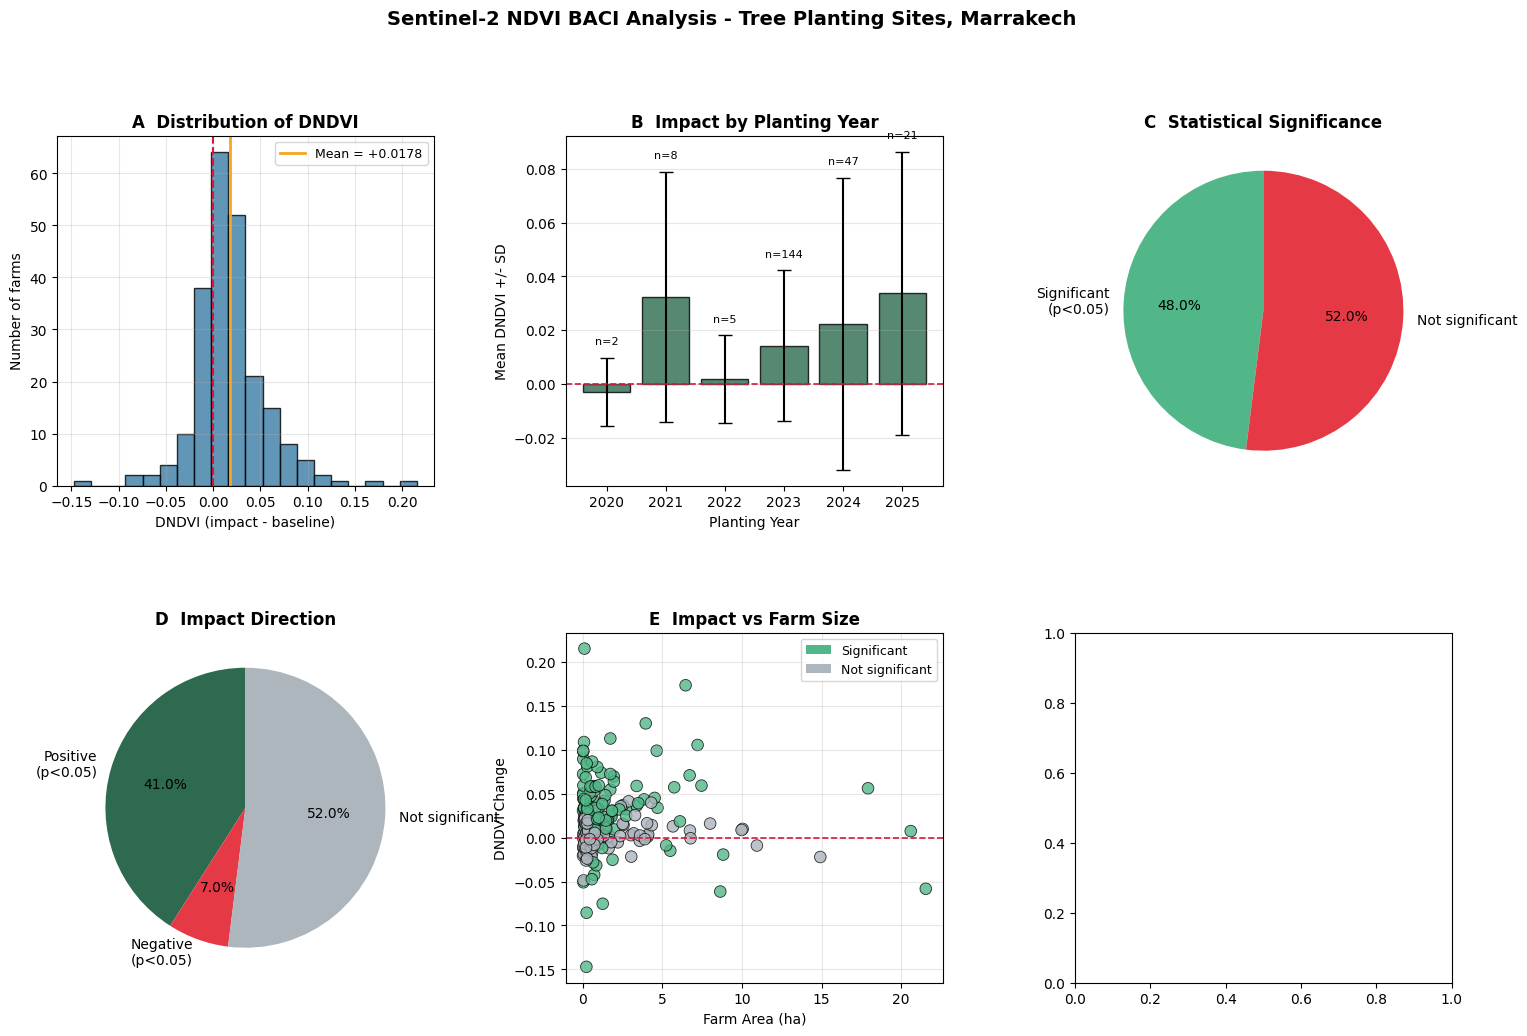

In [ ]:
# ============================================================================
# BEFORE-AFTER CONTROL-IMPACT (BACI) ANALYSIS OF TREE PLANTING SITES
# Marrakech Region, Morocco
# ============================================================================
#
# Author: [Your Name]
# Date:   2025
#
# Two independent analyses — run either or both:
#
#   run_sentinel_analysis(farm_df, dem)
#       → Sentinel-2 SR Harmonized (10 m), NDVI
#       → outputs: results/s2_baci_results.csv
#                  figures/s2_summary.png
#                  figures/s2_spatial_map.png
#
#   run_era5_analysis(farm_df, dem)
#       → ERA5-Land monthly (resampled to 1 km), 6 climate variables
#       → outputs: results/era5_baci_results.csv
#                  figures/era5_summary.png
#                  figures/era5_spatial_map.png
#
# BACI design:
#   For each treatment site the 3 nearest terrain-matched control sites are
#   identified.  Climate-corrected impact = Treatment − mean(3 Controls).
#   The before-after contrast of that difference is the BACI estimate.
#
# Performance:
#   - All GEE reductions batched into a single .getInfo() per farm
#   - ThreadPoolExecutor parallelises across farms
#   - Sentinel-2 kept at native 10 m; ERA5 extracted at 1 km
#
# ============================================================================
# OPTIONAL: fix package versions, then restart runtime before running
# ============================================================================
# import subprocess, sys
# subprocess.check_call([sys.executable, "-m", "pip", "install",
#                        "numpy==1.26.4", "scipy==1.12.0", "-q"])
# ============================================================================



# ── Scipy with pure-numpy fallback ──────────────────────────────────────────
try:
    from scipy import stats
except ImportError:
    class _Stats:
        @staticmethod
        def ttest_ind(a, b):
            n1, n2 = len(a), len(b)
            se = np.sqrt(np.var(a, ddof=1)/n1 + np.var(b, ddof=1)/n2)
            t  = (np.mean(a) - np.mean(b)) / se if se > 0 else 0
            p  = 2 * (1 - 0.5 * (1 + np.tanh(abs(t)/2)))
            return t, p
        @staticmethod
        def linregress(x, y):
            xm, ym = np.mean(x), np.mean(y)
            slope  = np.sum((x-xm)*(y-ym)) / np.sum((x-xm)**2)
            inter  = ym - slope*xm
            res    = y - (slope*x + inter)
            ss_res = np.sum(res**2)
            ss_tot = np.sum((y-ym)**2)
            r2     = max(1 - ss_res/ss_tot, 0) if ss_tot > 0 else 0
            se     = np.sqrt(ss_res/(len(x)-2)) / np.sqrt(np.sum((x-xm)**2))
            t      = slope/se if se > 0 else 0
            p      = 2*(1 - 0.5*(1 + np.tanh(abs(t)/2)))
            return slope, inter, np.sqrt(r2), p, se
    stats = _Stats()

# ── Output directories ───────────────────────────────────────────────────────
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)


# ============================================================================
# SECTION 1: STUDY CONFIGURATION
# ============================================================================

# ── Date ranges ─────────────────────────────────────────────────────────────
# Sentinel-2 SR is available from 2017-03-28.
# ERA5-Land monthly reanalysis runs from 1950 to near-present.
S2_START         = '2017-01-01'
ERA5_START       = '2017-01-01'   # match S2 for comparability; extend if needed
OVERALL_END      = '2026-04-30'
EXCLUSION_MONTHS = 6              # months post-planting excluded from 'impact' window

# ── Parallel processing ──────────────────────────────────────────────────────
USE_PARALLEL = True
MAX_WORKERS  = 6    # lower to 3-4 if you hit GEE rate limits

# ── ERA5-Land variable catalogue ─────────────────────────────────────────────
# Keys   = exact band names in ECMWF/ERA5_LAND/MONTHLY_AGGR
# Values = display metadata used by the plotting functions
ERA5_VARIABLES = {
    'evaporation_from_vegetation_transpiration_sum': {
        'label':        'Vegetation Transpiration',
        'short':        'transp',
        'scale_factor': 1000,     # m -> mm
        'unit':         'mm/month',
        'direction':    'positive',
    },
    'total_evaporation_sum': {
        'label':        'Total Evaporation',
        'short':        'evap',
        'scale_factor': -1000,    # ERA5 sign convention: negative = upward
        'unit':         'mm/month',
        'direction':    'positive',
    },
    'skin_temperature': {
        'label':        'Land Surface Temperature',
        'short':        'lst',
        'scale_factor': 1,
        'unit':         'K',
        'direction':    'negative',   # lower LST -> more vegetation cooling
    },
    'total_precipitation_sum': {
        'label':        'Total Precipitation',
        'short':        'precip',
        'scale_factor': 1000,   # m → mm
        'unit':         'mm',
        'direction':    'positive',
    },
        'potential_evaporation_sum': {
        'label':        'Potential Evaporation',
        'short':        'pet',
        'scale_factor': -1000,
        'unit':         'mm',
        'direction':    'negative',
    },

    'runoff_sum': {
        'label':        'Total Runoff',
        'short':        'runoff',
        'scale_factor': 1000,
        'unit':         'mm',
        'direction':    'negative',
    },

    'surface_runoff_sum': {
        'label':        'Surface Runoff',
        'short':        'srunoff',
        'scale_factor': 1000,
        'unit':         'mm',
        'direction':    'negative',
    },

    'sub_surface_runoff_sum': {
        'label':        'Subsurface Runoff',
        'short':        'ssrunoff',
        'scale_factor': 1000,
        'unit':         'mm',
        'direction':    'negative',
    },

    'temperature_2m': {
        'label':        'Air Temperature (2m)',
        'short':        'temp',
        'scale_factor': 1,
        'unit':         'K',
        'direction':    'neutral',
    },

    'surface_latent_heat_flux_sum': {
        'label':        'Latent Heat Flux',
        'short':        'lhf',
        'scale_factor': -1,
        'unit':         'J/m²',
        'direction':    'negative',
    },

    'leaf_area_index_high_vegetation': {
        'label':        'LAI - High Vegetation',
        'short':        'lai_high',
        'scale_factor': 1,
        'unit':         'm2/m2',
        'direction':    'positive',
    },

    'leaf_area_index_low_vegetation': {
        'label':        'LAI - Low Vegetation',
        'short':        'lai_low',
        'scale_factor': 1,
        'unit':         'm2/m2',
        'direction':    'positive',
    },
    'volumetric_soil_water_layer_1': {
        'label':        'Soil Moisture (0-7 cm)',
        'short':        'sm1',
        'scale_factor': 1,
        'unit':         'm3/m3',
        'direction':    'positive',
    },
    'volumetric_soil_water_layer_2': {
        'label':        'Soil Moisture (7–28 cm)',
        'short':        'sm_2',
        'scale_factor': 1,
        'unit':         'm3/m3',
        'direction':    'positive',
    },

    'volumetric_soil_water_layer_3': {
        'label':        'Soil Moisture (28–100 cm)',
        'short':        'sm_3',
        'scale_factor': 1,
        'unit':         'm3/m3',
        'direction':    'positive',
    },

    'volumetric_soil_water_layer_4': {
        'label':        'Soil Moisture (100–289 cm)',
        'short':        'sm_4',
        'scale_factor': 1,
        'unit':         'm3/m3',
        'direction':    'positive',
    }
}


# ============================================================================
# SECTION 2: FARM DATA LOADING
# ============================================================================

def load_farm_data(filepath):
    """
    Load and clean the farm GPS registration spreadsheet.

    Parameters
    ----------
    filepath : str  path to the .xlsx file

    Returns
    -------
    farm_df : pd.DataFrame        cleaned farm records
    farm_fc : ee.FeatureCollection  one point per farm
    """
    df = pd.read_excel(filepath)
    df = df.rename(columns={
        '_Record a GPS point inside the planting site_latitude':  'lat',
        '_Record a GPS point inside the planting site_longitude': 'lon',
        '_Record a GPS point inside the planting site_altitude':  'altitude',
        '_id':                       'farm_id',
        'The planting Season Year':  'planting_year',
    })
    df = df.dropna(subset=['lat', 'lon'])
    print(f"Loaded {len(df)} farms with GPS coordinates.")

    farm_fc = ee.FeatureCollection([
        ee.Feature(ee.Geometry.Point([r.lon, r.lat]), {'farm_id': str(r.farm_id)})
        for _, r in df.iterrows()
    ])
    return df, farm_fc


# ============================================================================
# SECTION 3: SHARED - TREATMENT AND CONTROL SITE GEOMETRY
# ============================================================================

def build_treatment_and_controls(farm_row, dem):
    """
    Build a treatment geometry and identify the 3 nearest terrain-matched
    control sites for one farm.  Shared by both analyses.

    Terrain matching criteria
    -------------------------
    Elevation within +/-50 m of treatment site
    Slope within +/-20% of treatment mean slope

    Parameters
    ----------
    farm_row : pd.Series  single row from farm_df
    dem      : ee.Image   SRTM elevation (band 'elevation')

    Returns
    -------
    treatment_geom : ee.Geometry
    control_geoms  : list[ee.Geometry]  (length 3)
    buffer_m       : float  radius used for the treatment buffer
    ctrl_coords    : list[[lon, lat]]  (length 3)
    """
    lon, lat  = farm_row['lon'], farm_row['lat']
    altitude  = farm_row.get('altitude', None)
    area_ha   = farm_row.get('shape_ha', None)
    point     = ee.Geometry.Point([lon, lat])

    # Treatment buffer - proportional to farm area, clamped 30-100 m
    if pd.notna(area_ha) and area_ha > 0:
        buffer_m = float(np.sqrt(area_ha * 10000 / np.pi))
        buffer_m = max(30.0, min(buffer_m, 100.0))
    else:
        buffer_m = 50.0
    treatment_geom = point.buffer(buffer_m)

    # Control search ring
    inner_m      = 150 if (area_ha and area_ha > 1) else 100
    outer_m      = 1000 if (area_ha and area_ha > 1) else 600
    control_ring = point.buffer(outer_m).difference(point.buffer(inner_m))

    # Terrain similarity mask
    slope_img = ee.Terrain.slope(dem)

    if pd.notna(altitude):
        elev_min, elev_max = float(altitude) - 50, float(altitude) + 50
    else:
        ev = dem.reduceRegion(ee.Reducer.mean(), treatment_geom, 30, maxPixels=1e6)
        e  = ee.Number(ev.get('elevation'))
        elev_min, elev_max = e.subtract(50), e.add(50)

    sv      = slope_img.reduceRegion(ee.Reducer.mean(), treatment_geom, 30, maxPixels=1e6)
    s_mean  = ee.Number(sv.get('slope'))
    s_min   = s_mean.subtract(s_mean.multiply(0.20))
    s_max   = s_mean.add(s_mean.multiply(0.20))
    terrain = (dem.gte(elev_min).And(dem.lte(elev_max))
                  .And(slope_img.gte(s_min)).And(slope_img.lte(s_max)))

    # Sample candidate control points
    candidates = terrain.selfMask().sample(
        region=control_ring, scale=60, numPixels=100, seed=42, geometries=True
    ).getInfo()['features']

    if len(candidates) < 3:    # fall back to elevation-only matching
        candidates = dem.sample(
            region=control_ring, scale=60, numPixels=100, seed=42, geometries=True
        ).getInfo()['features']

    # Pick the 3 closest
    dists = []
    for pt in candidates:
        c = pt['geometry']['coordinates']
        d = point.distance(ee.Geometry.Point(c)).getInfo()
        dists.append((d, c))
    dists.sort(key=lambda x: x[0])
    top3 = [c for _, c in dists[:3]]

    control_geoms = [ee.Geometry.Point(c).buffer(buffer_m) for c in top3]
    return treatment_geom, control_geoms, buffer_m, top3


# ============================================================================
# SECTION 4: SHARED - BACI STATISTICS
# ============================================================================

def add_period_labels(df, planting_date, date_col='date'):
    """
    Label each row as 'baseline', 'establishment', or 'impact'.

    Establishment = [planting_date, planting_date + EXCLUSION_MONTHS)
    Impact        = [planting_date + EXCLUSION_MONTHS, ...]
    """
    pd_dt    = pd.to_datetime(planting_date)
    excl_end = pd_dt + pd.DateOffset(months=EXCLUSION_MONTHS)
    df       = df.copy()
    df['period'] = 'baseline'
    df.loc[df[date_col] >= pd_dt,    'period'] = 'establishment'
    df.loc[df[date_col] >= excl_end, 'period'] = 'impact'
    return df


def baci_test(df, value_col):
    """
    Independent-samples t-test comparing delta values in baseline vs impact.

    Returns None if either period has fewer than 3 observations.
    """
    base   = df[df['period'] == 'baseline'][value_col].dropna()
    impact = df[df['period'] == 'impact'][value_col].dropna()
    if len(base) < 3 or len(impact) < 3:
        return None
    t, p = stats.ttest_ind(impact.values, base.values)
    return {
        'change':        impact.mean() - base.mean(),
        't_stat':        t,
        'p_value':       p,
        'significant':   p < 0.05,
        'n_baseline':    len(base),
        'n_impact':      len(impact),
        'baseline_mean': base.mean(),
        'impact_mean':   impact.mean(),
        'baseline_std':  base.std(),
        'impact_std':    impact.std(),
    }


def trend_in_impact(df, value_col):
    """
    Fit a linear trend through the impact-period values.
    Returns slope (units/year), R2, p-value, or None if fewer than 4 points.
    """
    imp = df[df['period'] == 'impact'].sort_values('date')
    if len(imp) < 4:
        return None
    x = np.arange(len(imp), dtype=float)
    y = imp[value_col].values
    slope, _, r, p, _ = stats.linregress(x, y)
    return {'slope_per_year': slope * 12, 'r_squared': r**2, 'p_value': p}


def _parallel_runner(analyze_fn, farm_df):
    """
    Generic parallel / sequential dispatcher.
    analyze_fn must accept a single pd.Series (farm row) and return a dict or None.
    """
    all_results, failed = [], []
    n  = len(farm_df)
    t0 = time.time()
    mode = 'PARALLEL' if USE_PARALLEL else 'SEQUENTIAL'
    print(f"\nProcessing {n} farms  [{mode}"
          f"{'  workers='+str(MAX_WORKERS) if USE_PARALLEL else ''}]")

    if USE_PARALLEL:
        with ThreadPoolExecutor(max_workers=MAX_WORKERS) as ex:
            futures = {ex.submit(analyze_fn, row): row['farm_id']
                       for _, row in farm_df.iterrows()}
            for k, fut in enumerate(as_completed(futures), 1):
                fid = futures[fut]
                try:
                    res = fut.result()
                    if res:
                        all_results.append(res)
                        _log_ok(k, n, fid, res)
                    else:
                        failed.append(fid)
                        print(f"  x [{k}/{n}] Farm {fid}: insufficient data")
                except Exception as e:
                    failed.append(fid)
                    print(f"  x [{k}/{n}] Farm {fid}: {e}")
    else:
        for k, (_, row) in enumerate(farm_df.iterrows(), 1):
            fid = row['farm_id']
            res = analyze_fn(row)
            if res:
                all_results.append(res)
                _log_ok(k, n, fid, res)
            else:
                failed.append(fid)
                print(f"  x [{k}/{n}] Farm {fid}: insufficient data")

    elapsed = time.time() - t0
    print(f"\nDone  |  {len(all_results)}/{n} succeeded  |  "
          f"{elapsed:.0f}s ({elapsed/60:.1f} min)  |  {elapsed/n:.1f}s/farm")
    if failed:
        print(f"Failed IDs: {failed[:20]}{'...' if len(failed) > 20 else ''}")
    return all_results


def _log_ok(k, n, fid, res):
    """Print one-line success summary for a farm result."""
    if 's2_change' in res:
        print(f"  + [{k}/{n}] Farm {fid}  "
              f"NDVI={res['s2_change']:+.4f}  p={res['s2_p_value']:.3f}")
    else:
        short = list(ERA5_VARIABLES.values())[0]['short']
        chg = res.get(f'{short}_change', float('nan'))
        p   = res.get(f'{short}_p',      float('nan'))
        print(f"  + [{k}/{n}] Farm {fid}  "
              f"D{short}={chg:+.4f}  p={p:.3f}")


# ============================================================================
# SECTION 5: SENTINEL-2 DATA PIPELINE
# ============================================================================

def _mask_s2_clouds(image):
    """Remove clouds and cirrus via QA60 bitmask (bits 10 and 11)."""
    qa   = image.select('QA60')
    mask = qa.bitwiseAnd(1 << 10).eq(0).And(qa.bitwiseAnd(1 << 11).eq(0))
    return image.updateMask(mask)


def _add_ndvi(image):
    """Add NDVI band to a Sentinel-2 image (B8=NIR, B4=Red)."""
    return image.addBands(image.normalizedDifference(['B8', 'B4']).rename('NDVI'))


def _load_s2(geometry, start_date, end_date):
    """Return cloud-masked, NDVI-enriched Sentinel-2 SR Harmonized collection."""
    return (
        ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
        .filterBounds(geometry)
        .filterDate(start_date, end_date)
        .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20))
        .map(_mask_s2_clouds)
        .map(_add_ndvi)
        .select('NDVI')
        .sort('system:time_start')
    )


def _make_monthly_composites(collection, start_date, end_date):
    """Monthly median composites with system:time_start on the 15th."""
    start   = ee.Date(start_date)
    end     = ee.Date(end_date)
    offsets = ee.List.sequence(0, end.difference(start, 'month').subtract(1))

    def _month(offset):
        t0   = start.advance(offset, 'month')
        t1   = t0.advance(1, 'month')
        imgs = collection.filterDate(t0, t1)
        return ee.Algorithms.If(
            imgs.size().gt(0),
            imgs.median().set({
                'system:time_start': t0.advance(15, 'day').millis(),
                'month': t0.format('YYYY-MM'),
            }),
            None,
        )

    monthly = offsets.map(_month).removeAll([None])
    return ee.ImageCollection(monthly)


def _extract_s2_ts(monthly_col, treatment_geom, control_geoms):
    """
    Batch-extract monthly NDVI for treatment + 3 controls (one .getInfo() call).

    Returns a DataFrame with columns:
        date, ndvi_treatment, control_1, control_2, control_3,
        ndvi_control_avg, delta_ndvi
    """
    regions = ee.FeatureCollection([
        ee.Feature(treatment_geom,   {'type': 'treatment'}),
        ee.Feature(control_geoms[0], {'type': 'control_1'}),
        ee.Feature(control_geoms[1], {'type': 'control_2'}),
        ee.Feature(control_geoms[2], {'type': 'control_3'}),
    ])

    def _reduce(image):
        return image.select('NDVI').reduceRegions(
            collection=regions,
            reducer=ee.Reducer.mean(),
            scale=10,          # native Sentinel-2 resolution
        ).map(lambda f: f.set('date', image.date().format('YYYY-MM-dd')))

    features = monthly_col.map(_reduce).flatten().getInfo()['features']
    df = pd.DataFrame([f['properties'] for f in features])
    df['date'] = pd.to_datetime(df['date'])
    df['val']  = pd.to_numeric(df['mean'], errors='coerce')
    df = df.pivot(index='date', columns='type', values='val').reset_index()

    df.rename(columns={'treatment': 'ndvi_treatment'}, inplace=True)
    df['ndvi_control_avg'] = df[['control_1', 'control_2', 'control_3']].mean(axis=1)
    df['delta_ndvi']       = df['ndvi_treatment'] - df['ndvi_control_avg']

    return (df.dropna(subset=['ndvi_treatment', 'ndvi_control_avg'])
              .sort_values('date').reset_index(drop=True))


def _analyze_s2_farm(farm_row, dem):
    """Full Sentinel-2 BACI pipeline for one farm."""
    farm_id       = farm_row['farm_id']
    planting_year = int(farm_row['planting_year'])
    planting_date = f"{planting_year}-01-01"
    start_date    = f"{planting_year - 3}-01-01"

    try:
        treatment_geom, control_geoms, buffer_m, ctrl_coords = \
            build_treatment_and_controls(farm_row, dem)

        load_geom = treatment_geom.buffer(2000)
        s2_col    = _load_s2(load_geom, start_date, OVERALL_END)
        s2_month  = _make_monthly_composites(s2_col, start_date, OVERALL_END)

        if s2_month.size().getInfo() < 12:
            return None

        ts   = _extract_s2_ts(s2_month, treatment_geom, control_geoms)
        ts   = add_period_labels(ts, planting_date)
        baci = baci_test(ts, 'delta_ndvi')

        if baci is None:
            return None

        trend = trend_in_impact(ts, 'delta_ndvi')

        return {
            # Farm metadata
            'farm_id':        farm_id,
            'lat':            farm_row['lat'],
            'lon':            farm_row['lon'],
            'altitude':       farm_row.get('altitude', np.nan),
            'area_ha':        farm_row.get('shape_ha', np.nan),
            'planting_year':  planting_year,
            'planting_date':  planting_date,
            'buffer_m':       buffer_m,
            'ctrl_coords':    ctrl_coords,
            # BACI statistics
            's2_change':        baci['change'],
            's2_p_value':       baci['p_value'],
            's2_significant':   baci['significant'],
            's2_baseline_mean': baci['baseline_mean'],
            's2_impact_mean':   baci['impact_mean'],
            's2_n_baseline':    baci['n_baseline'],
            's2_n_impact':      baci['n_impact'],
            # Trend in impact period
            's2_trend_yr': trend['slope_per_year'] if trend else np.nan,
            's2_trend_r2': trend['r_squared']      if trend else np.nan,
            's2_trend_p':  trend['p_value']        if trend else np.nan,
            # Time series retained for plotting; excluded from CSV export
            '_ts': ts,
        }
    except Exception as e:
        print(f"  x Farm {farm_id} (S2): {e}")
        return None


# ============================================================================
# SECTION 6: ERA5-LAND DATA PIPELINE
# ============================================================================

def _load_era5(geometry, start_date, end_date):
    """Return ERA5-Land monthly collection filtered to geometry and date range."""
    return (
        ee.ImageCollection('ECMWF/ERA5_LAND/MONTHLY_AGGR')
        .filterBounds(geometry)
        .filterDate(start_date, end_date)
        .select(list(ERA5_VARIABLES.keys()))
    )


def _extract_era5_ts(era5_col, treatment_geom, control_geoms):
    """
    Batch-extract all ERA5 variables for treatment + 3 controls (one .getInfo() call).

    Returns a dict of DataFrames keyed by variable short name:
        {
          'transp': DataFrame(date, treatment, control_1, ..., control_avg, delta),
          'lst':    DataFrame(...),
          ...
        }
    """
    regions = ee.FeatureCollection([
        ee.Feature(treatment_geom,   {'type': 'treatment'}),
        ee.Feature(control_geoms[0], {'type': 'control_1'}),
        ee.Feature(control_geoms[1], {'type': 'control_2'}),
        ee.Feature(control_geoms[2], {'type': 'control_3'}),
    ])

    def _reduce(image):
        return image.reduceRegions(
            collection=regions,
            reducer=ee.Reducer.mean(),
            scale=1000,        # ERA5 native ~11 km; 1 km for point extraction
        ).map(lambda f: f.set('date', image.date().format('YYYY-MM-dd')))

    features = era5_col.map(_reduce).flatten().getInfo()['features']
    raw      = pd.DataFrame([f['properties'] for f in features])
    raw['date'] = pd.to_datetime(raw['date'])

    out = {}
    for band, cfg in ERA5_VARIABLES.items():
        if band not in raw.columns:
            continue
        tmp       = raw[['date', 'type', band]].copy()
        tmp[band] = pd.to_numeric(tmp[band], errors='coerce') * cfg['scale_factor']
        piv       = tmp.pivot(index='date', columns='type', values=band).reset_index()
        piv['control_avg'] = piv[['control_1','control_2','control_3']].mean(axis=1)
        piv['delta']       = piv['treatment'] - piv['control_avg']
        out[cfg['short']]  = (piv.dropna(subset=['treatment','control_avg'])
                                 .sort_values('date').reset_index(drop=True))
    return out


def _analyze_era5_farm(farm_row, dem):
    """Full ERA5-Land BACI pipeline for one farm."""
    farm_id       = farm_row['farm_id']
    planting_year = int(farm_row['planting_year'])
    planting_date = f"{planting_year}-01-01"
    start_date    = f"{planting_year - 3}-01-01"

    try:
        treatment_geom, control_geoms, buffer_m, ctrl_coords = \
            build_treatment_and_controls(farm_row, dem)

        load_geom = treatment_geom.buffer(2000)
        era5_col  = _load_era5(load_geom, start_date, OVERALL_END)
        era5_ts   = _extract_era5_ts(era5_col, treatment_geom, control_geoms)

        if not era5_ts:
            return None

        result = {
            'farm_id':       farm_id,
            'lat':           farm_row['lat'],
            'lon':           farm_row['lon'],
            'altitude':      farm_row.get('altitude', np.nan),
            'area_ha':       farm_row.get('shape_ha', np.nan),
            'planting_year': planting_year,
            'planting_date': planting_date,
            'buffer_m':      buffer_m,
            'ctrl_coords':   ctrl_coords,
            '_era5_ts':      {},    # time series per variable (for plotting)
        }

        any_valid = False
        for short, ts_df in era5_ts.items():
            ts_df = add_period_labels(ts_df, planting_date)
            baci  = baci_test(ts_df, 'delta')
            trend = trend_in_impact(ts_df, 'delta')

            result['_era5_ts'][short] = ts_df

            if baci:
                any_valid = True
                result[f'{short}_change']        = baci['change']
                result[f'{short}_p']             = baci['p_value']
                result[f'{short}_sig']           = baci['significant']
                result[f'{short}_baseline_mean'] = baci['baseline_mean']
                result[f'{short}_impact_mean']   = baci['impact_mean']
                result[f'{short}_n_baseline']    = baci['n_baseline']
                result[f'{short}_n_impact']      = baci['n_impact']
                result[f'{short}_trend_yr']      = trend['slope_per_year'] if trend else np.nan
                result[f'{short}_trend_r2']      = trend['r_squared']      if trend else np.nan
                result[f'{short}_trend_p']       = trend['p_value']        if trend else np.nan
            else:
                for sfx in ('change','p','sig','baseline_mean','impact_mean',
                            'n_baseline','n_impact','trend_yr','trend_r2','trend_p'):
                    result[f'{short}_{sfx}'] = np.nan

        return result if any_valid else None

    except Exception as e:
        print(f"  x Farm {farm_id} (ERA5): {e}")
        return None


# ============================================================================
# SECTION 7: RESULTS EXPORT  (shared)
# ============================================================================

def _export_csv(all_results, skip_keys, path):
    """Flatten results to CSV, excluding internal keys (time series, coords)."""
    rows = [{k: v for k, v in r.items() if k not in skip_keys}
            for r in all_results]
    df = pd.DataFrame(rows)
    df.to_csv(path, index=False)
    print(f"Results saved -> {path}  ({len(df)} rows x {len(df.columns)} columns)")
    return df


# ============================================================================
# SECTION 8: SENTINEL-2 VISUALIZATIONS
# ============================================================================

def _plot_s2_summary(results_df, all_results):
    """
    6-panel publication figure for the Sentinel-2 NDVI BACI analysis.

    A - Distribution of DNDVI
    B - Mean DNDVI by planting year (+/-SD)
    C - Significance breakdown
    D - Impact direction
    E - DNDVI vs farm area
    F - Aggregate trajectory (months from planting date)
    """
    fig = plt.figure(figsize=(18, 11))
    fig.suptitle('Sentinel-2 NDVI BACI Analysis - Tree Planting Sites, Marrakech',
                 fontsize=14, fontweight='bold', y=0.995)
    gs   = gridspec.GridSpec(2, 3, hspace=0.42, wspace=0.35)
    axes = [fig.add_subplot(gs[r, c]) for r in range(2) for c in range(3)]

    # A: distribution
    ax = axes[0]
    ax.hist(results_df['s2_change'], bins=20, color='#3A7CA5', edgecolor='k', alpha=0.8)
    ax.axvline(0, color='crimson', ls='--', lw=1.5)
    ax.axvline(results_df['s2_change'].mean(), color='#F5A623', lw=2,
               label=f"Mean = {results_df['s2_change'].mean():+.4f}")
    ax.set_xlabel('DNDVI (impact - baseline)'); ax.set_ylabel('Number of farms')
    ax.set_title('A  Distribution of DNDVI', fontweight='bold')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

    # B: by year
    ax = axes[1]
    yr = results_df.groupby('planting_year')['s2_change'].agg(['mean','std','count'])
    ax.bar(yr.index, yr['mean'], yerr=yr['std'], color='#2D6A4F',
           edgecolor='k', alpha=0.8, capsize=5)
    ax.axhline(0, color='crimson', ls='--', lw=1.2)
    for y, row in yr.iterrows():
        ax.text(y, row['mean'] + row['std'] + 0.005,
                f"n={int(row['count'])}", ha='center', fontsize=8)
    ax.set_xlabel('Planting Year'); ax.set_ylabel('Mean DNDVI +/- SD')
    ax.set_title('B  Impact by Planting Year', fontweight='bold')
    ax.grid(True, alpha=0.3, axis='y')

    # C: significance pie
    ax = axes[2]
    sig_n = results_df['s2_significant'].sum()
    ax.pie([sig_n, len(results_df) - sig_n],
           labels=['Significant\n(p<0.05)', 'Not significant'],
           autopct='%1.1f%%', colors=['#52B788','#E63946'], startangle=90)
    ax.set_title('C  Statistical Significance', fontweight='bold')

    # D: direction pie
    ax  = axes[3]
    pos = (results_df['s2_significant'] & (results_df['s2_change'] > 0)).sum()
    neg = (results_df['s2_significant'] & (results_df['s2_change'] < 0)).sum()
    ns  = (~results_df['s2_significant']).sum()
    ax.pie([pos, neg, ns],
           labels=['Positive\n(p<0.05)','Negative\n(p<0.05)','Not significant'],
           autopct='%1.1f%%', colors=['#2D6A4F','#E63946','#ADB5BD'], startangle=90)
    ax.set_title('D  Impact Direction', fontweight='bold')

    # E: DNDVI vs area
    ax = axes[4]
    colors = results_df['s2_significant'].map({True: '#52B788', False: '#ADB5BD'})
    ax.scatter(results_df['area_ha'], results_df['s2_change'],
               c=colors, s=70, edgecolors='k', linewidths=0.6, alpha=0.8)
    ax.axhline(0, color='crimson', ls='--', lw=1.2)
    ax.set_xlabel('Farm Area (ha)'); ax.set_ylabel('DNDVI Change')
    ax.set_title('E  Impact vs Farm Size', fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.legend(handles=[Patch(fc='#52B788', label='Significant'),
                        Patch(fc='#ADB5BD', label='Not significant')], fontsize=9)

    # F: aggregate trajectory
    ax = axes[5]
    frames = []
    for r in all_results:
        ts = r['_ts'].copy()
        ts['mo'] = ((ts['date'] - pd.to_datetime(r['planting_date'])
                     ).dt.days / 30.44).round().astype(int)
        frames.append(ts[['mo','delta_ndvi']])
    combined = pd.concat(frames, ignore_index=True)
    agg = (combined.groupby('mo')['delta_ndvi']
           .agg(['mean','std','count']).query('count >= 3'))
    agg['se'] = agg['std'] / np.sqrt(agg['count'])
    agg = (combined.groupby('mo')['delta']
                  .agg(['mean','std','count'])
                  .query('count >= 5'))   # increase threshold

    ax.fill_between(agg.index, agg['mean']-agg['se'], agg['mean']+agg['se'],
                    alpha=0.25, color='#3A7CA5')
    ax.plot(agg.index, agg['mean'], 'o-', color='#3A7CA5', lw=2, ms=4)
    ax.axhline(0, color='k', lw=0.8)
    ax.axvline(0, color='crimson', ls='--', lw=1.5, label='Planting date')
    ax.axvline(EXCLUSION_MONTHS, color='orange', ls=':', lw=1.2, label='Establishment end')
    ax.set_xlabel('Months from planting date'); ax.set_ylabel('Mean DNDVI (+/-SE)')
    ax.set_title('F  Aggregate NDVI Trajectory', fontweight='bold')
    ax.legend(fontsize=9); ax.grid(True, alpha=0.3)

    fig.savefig('figures/s2_summary.png', dpi=300, bbox_inches='tight')
    print("Saved -> figures/s2_summary.png")
    plt.show()


def _plot_s2_spatial(results_df):
    """Farm map coloured by DNDVI; marker size encodes significance."""
    fig, ax = plt.subplots(figsize=(11, 8))
    sc = ax.scatter(results_df['lon'], results_df['lat'],
                    c=results_df['s2_change'], cmap='RdYlGn',
                    s=results_df['s2_significant'].map({True: 180, False: 60}),
                    alpha=0.75, edgecolors='k', linewidths=0.8,
                    vmin=-0.15, vmax=0.15)
    plt.colorbar(sc, ax=ax, pad=0.01, label='DNDVI change')
    ax.legend(handles=[
        Line2D([0],[0], marker='o', color='w', markerfacecolor='#888',
               markersize=12, label='Significant (p<0.05)'),
        Line2D([0],[0], marker='o', color='w', markerfacecolor='#888',
               markersize=7,  label='Not significant'),
    ], fontsize=10, loc='lower left')
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    ax.set_title('Spatial Distribution of NDVI Impact (Sentinel-2 BACI)',
                 fontweight='bold')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    fig.savefig('figures/s2_spatial_map.png', dpi=300, bbox_inches='tight')
    print("Saved -> figures/s2_spatial_map.png")
    plt.show()


# ============================================================================
# SECTION 9: ERA5 VISUALIZATIONS
# ============================================================================


def _plot_era5_summary(results_df, all_results):
    """
    Two-column figure with one row per ERA5 variable.

    Left  - Mean DBACI by planting year (+/-SD bar chart)
    Right - Aggregate trajectory (months from planting date)
    """
    cfg_by_short = {v['short']: v for v in ERA5_VARIABLES.values()}
    shorts       = [v['short'] for v in ERA5_VARIABLES.values()]
    n_vars       = len(shorts)

    fig, axes = plt.subplots(n_vars, 2, figsize=(16, 4.5 * n_vars))
    fig.suptitle('ERA5-Land BACI Analysis - Tree Planting Sites, Marrakech',
                 fontsize=13, fontweight='bold', y=1.001)

    for i, short in enumerate(shorts):
        cfg   = cfg_by_short[short]
        ax_l  = axes[i, 0]
        ax_r  = axes[i, 1]
        col_c = f'{short}_change'

        # Left: mean change by planting year
        if col_c in results_df.columns:
            yr = results_df.groupby('planting_year')[col_c].agg(['mean','std','count'])
            ax_l.bar(yr.index, yr['mean'], yerr=yr['std'], color='#457B9D',
                     edgecolor='k', alpha=0.8, capsize=4)
            ax_l.axhline(0, color='crimson', ls='--', lw=1.2)
            for y, row in yr.iterrows():
                offset = row['std'] + abs(row['mean']) * 0.05 + 1e-9
                ax_l.text(y, row['mean'] + offset,
                          f"n={int(row['count'])}", ha='center', fontsize=7)
        ax_l.set_title(f"{cfg['label']} - Impact by Year", fontweight='bold', fontsize=10)
        ax_l.set_xlabel('Planting Year'); ax_l.set_ylabel(f"D ({cfg['unit']})")
        ax_l.grid(True, alpha=0.3, axis='y')

        # Right: aggregate trajectory
        frames = []
        for res in all_results:
            ts = res.get('_era5_ts', {}).get(short)
            if ts is None:
                continue
            ts = ts.copy()
            ts['mo'] = ((ts['date'] - pd.to_datetime(res['planting_date'])
                         ).dt.days / 30.44).round().astype(int)
            frames.append(ts[['mo','delta']])
        if frames:
            combined = pd.concat(frames, ignore_index=True)
            agg = (combined.groupby('mo')['delta']
                   .agg(['mean','std','count']).query('count >= 9'))
            agg['se'] = agg['std'] / np.sqrt(agg['count'])

            ax_r.fill_between(agg.index, agg['mean']-agg['se'],
                              agg['mean']+agg['se'], alpha=0.25, color='#457B9D')
            ax_r.plot(agg.index, agg['mean'], 'o-', color='#457B9D', lw=2, ms=4)
        ax_r.axhline(0, color='k', lw=0.8)
        ax_r.axvline(0, color='crimson', ls='--', lw=1.5, label='Planting date')
        ax_r.axvline(EXCLUSION_MONTHS, color='orange', ls=':', lw=1.2,
                     label='Establishment end')
        ax_r.set_title(f"{cfg['label']} - Aggregate Trajectory",
                       fontweight='bold', fontsize=10)
        ax_r.set_xlabel('Months from planting date')
        ax_r.set_ylabel(f"D ({cfg['unit']})")
        ax_r.legend(fontsize=8); ax_r.grid(True, alpha=0.3)

    plt.tight_layout()
    fig.savefig('figures/era5_summary.png', dpi=300, bbox_inches='tight')
    print("Saved -> figures/era5_summary.png")
    plt.show()



def _plot_era5_spatial(results_df):
    """
    One spatial map per ERA5 variable arranged in a 2-column grid.
    Colour = DBACI change magnitude; size = significance.
    """
    shorts = [v['short'] for v in ERA5_VARIABLES.values()]
    cfg_by = {v['short']: v for v in ERA5_VARIABLES.values()}
    ncols  = 2
    nrows  = int(np.ceil(len(shorts) / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 5.5 * nrows))
    axes = axes.flatten()

    for i, short in enumerate(shorts):
        ax    = axes[i]
        cfg   = cfg_by[short]
        col_c = f'{short}_change'
        col_s = f'{short}_sig'
        if col_c not in results_df.columns:
            ax.set_visible(False); continue

        sub  = results_df.dropna(subset=[col_c])
        vmax = sub[col_c].abs().quantile(0.95)
        sc   = ax.scatter(sub['lon'], sub['lat'],
                          c=sub[col_c], cmap='RdYlGn',
                          s=sub[col_s].map({True: 180, False: 60}).fillna(60),
                          alpha=0.75, edgecolors='k', linewidths=0.7,
                          vmin=-vmax, vmax=vmax)
        plt.colorbar(sc, ax=ax, pad=0.01, label=f"D ({cfg['unit']})")
        ax.set_title(cfg['label'], fontweight='bold', fontsize=10)
        ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
        ax.grid(True, alpha=0.3)

    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)

    fig.suptitle('Spatial Distribution of ERA5-Land BACI Impacts',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    fig.savefig('figures/era5_spatial_map.png', dpi=300, bbox_inches='tight')
    print("Saved -> figures/era5_spatial_map.png")
    plt.show()


# ============================================================================
# SECTION 10: TOP-LEVEL ANALYSIS ENTRY POINTS
# ============================================================================

def run_sentinel_analysis(farm_df, dem):
    """
    Run the complete Sentinel-2 NDVI BACI analysis.

    Parameters
    ----------
    farm_df : pd.DataFrame   output of load_farm_data()
    dem     : ee.Image       SRTM DEM (band 'elevation')

    Returns
    -------
    results_df  : pd.DataFrame   one row per farm, BACI statistics
    all_results : list[dict]     full result dicts including time series
    """
    print("\n" + "="*80)
    print("SENTINEL-2 NDVI BACI ANALYSIS")
    print("Collection : COPERNICUS/S2_SR_HARMONIZED  |  Resolution: 10 m")
    print("Variable   : NDVI = (B8-B4)/(B8+B4)")
    print("="*80)

    analyze_fn  = partial(_analyze_s2_farm, dem=dem)
    all_results = _parallel_runner(analyze_fn, farm_df)

    if not all_results:
        print("No farms were successfully analysed.")
        return None, []

    results_df = _export_csv(
        all_results,
        skip_keys={'_ts', 'ctrl_coords'},
        path='results/s2_baci_results.csv',
    )

    # Summary
    print("\n" + "="*60)
    print("SUMMARY - Sentinel-2 NDVI")
    print("="*60)
    print(f"  Farms analysed:         {len(results_df)}")
    print(f"  Significant (p<0.05):   {results_df['s2_significant'].sum()} "
          f"({100*results_df['s2_significant'].mean():.1f}%)")
    pos = (results_df['s2_significant'] & (results_df['s2_change'] > 0)).sum()
    print(f"  Positive & significant: {pos}")
    print(f"  Mean DNDVI:             {results_df['s2_change'].mean():+.4f} "
          f"+/- {results_df['s2_change'].std():.4f}")
    print("\nBy planting year:")
    print(results_df.groupby('planting_year').agg(
        N              =('farm_id',        'count'),
        Mean_DNDVI     =('s2_change',      'mean'),
        Pct_significant=('s2_significant', 'mean'),
    ).round(4))

    # Figures
    _plot_s2_summary(results_df, all_results)
    _plot_s2_spatial(results_df)

    print("\nOutputs:")
    print("  results/s2_baci_results.csv")
    print("  figures/s2_summary.png")
    print("  figures/s2_spatial_map.png")

    return results_df, all_results


def run_era5_analysis(farm_df, dem):
    """
    Run the complete ERA5-Land BACI analysis across all configured variables.

    Parameters
    ----------
    farm_df : pd.DataFrame   output of load_farm_data()
    dem     : ee.Image       SRTM DEM (band 'elevation')

    Returns
    -------
    results_df  : pd.DataFrame   one row per farm, BACI stats for all variables
    all_results : list[dict]     full result dicts including time series
    """
    print("\n" + "="*80)
    print("ERA5-LAND BACI ANALYSIS")
    print("Collection : ECMWF/ERA5_LAND/MONTHLY_AGGR  |  Extraction scale: 1 km")
    print(f"Variables  : {', '.join(v['short'] for v in ERA5_VARIABLES.values())}")
    print("="*80)

    analyze_fn  = partial(_analyze_era5_farm, dem=dem)
    all_results = _parallel_runner(analyze_fn, farm_df)

    if not all_results:
        print("No farms were successfully analysed.")
        return None, []

    results_df = _export_csv(
        all_results,
        skip_keys={'_era5_ts', 'ctrl_coords'},
        path='results/era5_baci_results.csv',
    )

    # Summary
    print("\n" + "="*60)
    print("SUMMARY - ERA5-Land Variables")
    print("="*60)
    for cfg in ERA5_VARIABLES.values():
        short = cfg['short']
        col_c = f'{short}_change'
        col_s = f'{short}_sig'
        if col_c not in results_df.columns:
            continue
        sub = results_df.dropna(subset=[col_c])
        sig = int(sub[col_s].sum()) if col_s in sub.columns else 0
        print(f"\n  {cfg['label']} ({cfg['unit']})")
        print(f"    Mean D:      {sub[col_c].mean():+.4f} +/- {sub[col_c].std():.4f}")
        print(f"    Significant: {sig} ({100*sig/max(len(sub),1):.1f}%)")

    # Figures
    _plot_era5_summary(results_df, all_results)
    _plot_era5_spatial(results_df)

    print("\nOutputs:")
    print("  results/era5_baci_results.csv")
    print("  figures/era5_summary.png")
    print("  figures/era5_spatial_map.png")

    return results_df, all_results


# ============================================================================
# SECTION 11: MAIN - choose which analysis/analyses to run
# ============================================================================

FARM_FILE = "/content/HAF_Planting_Sites_Registration_and_Monitoring_Marrakech.xlsx"

# ── Shared inputs (always needed) ────────────────────────────────────────
farm_df, farm_fc = load_farm_data(FARM_FILE)
dem = ee.Image('USGS/SRTMGL1_003').select('elevation')

# ── Run Sentinel-2 analysis ──────────────────────────────────────────────
# s2_results_df, s2_all = run_sentinel_analysis(farm_df, dem)

# ── Run ERA5 analysis  (uncomment to run) ────────────────────────────────
era5_results_df, era5_all = run_era5_analysis(farm_df, dem)

In [ ]:

def _plot_era5_summary(results_df, all_results):
    """
    Two-column figure with one row per ERA5 variable.

    Left  - Mean DBACI by planting year (+/-SD bar chart)
    Right - Aggregate trajectory (months from planting date)
    """
    cfg_by_short = {v['short']: v for v in ERA5_VARIABLES.values()}
    shorts       = [v['short'] for v in ERA5_VARIABLES.values()]
    n_vars       = len(shorts)

    fig, axes = plt.subplots(n_vars, 2, figsize=(16, 4.5 * n_vars))
    fig.suptitle('ERA5-Land BACI Analysis - Tree Planting Sites, Marrakech',
                 fontsize=13, fontweight='bold', y=1.001)

    for i, short in enumerate(shorts):
        cfg   = cfg_by_short[short]
        ax_l  = axes[i, 0]
        ax_r  = axes[i, 1]
        col_c = f'{short}_change'

        # Left: mean change by planting year
        if col_c in results_df.columns:
            yr = results_df.groupby('planting_year')[col_c].agg(['mean','std','count'])
            ax_l.bar(yr.index, yr['mean'], yerr=yr['std'], color='#457B9D',
                     edgecolor='k', alpha=0.8, capsize=4)
            ax_l.axhline(0, color='crimson', ls='--', lw=1.2)
            for y, row in yr.iterrows():
                offset = row['std'] + abs(row['mean']) * 0.05 + 1e-9
                ax_l.text(y, row['mean'] + offset,
                          f"n={int(row['count'])}", ha='center', fontsize=7)
        ax_l.set_title(f"{cfg['label']} - Impact by Year", fontweight='bold', fontsize=10)
        ax_l.set_xlabel('Planting Year'); ax_l.set_ylabel(f"D ({cfg['unit']})")
        ax_l.grid(True, alpha=0.3, axis='y')

        # Right: aggregate trajectory
        frames = []
        for res in all_results:
            ts = res.get('_era5_ts', {}).get(short)
            if ts is None:
                continue
            ts = ts.copy()
            ts['mo'] = ((ts['date'] - pd.to_datetime(res['planting_date'])
                         ).dt.days / 30.44).round().astype(int)
            frames.append(ts[['mo','delta']])
        if frames:
            combined = pd.concat(frames, ignore_index=True)
            agg = (combined.groupby('mo')['delta']
                   .agg(['mean','std','count']).query('count >= 9'))
            agg['se'] = agg['std'] / np.sqrt(agg['count'])

            ax_r.fill_between(agg.index, agg['mean']-agg['se'],
                              agg['mean']+agg['se'], alpha=0.25, color='#457B9D')
            ax_r.plot(agg.index, agg['mean'], 'o-', color='#457B9D', lw=2, ms=4)
        ax_r.axhline(0, color='k', lw=0.8)
        ax_r.axvline(0, color='crimson', ls='--', lw=1.5, label='Planting date')
        ax_r.axvline(EXCLUSION_MONTHS, color='orange', ls=':', lw=1.2,
                     label='Establishment end')
        ax_r.set_title(f"{cfg['label']} - Aggregate Trajectory",
                       fontweight='bold', fontsize=10)
        ax_r.set_xlabel('Months from planting date')
        ax_r.set_ylabel(f"D ({cfg['unit']})")
        ax_r.legend(fontsize=8); ax_r.grid(True, alpha=0.3)

    plt.tight_layout()
    fig.savefig('figures/era5_summary.png', dpi=300, bbox_inches='tight')
    print("Saved -> figures/era5_summary.png")
    plt.show()


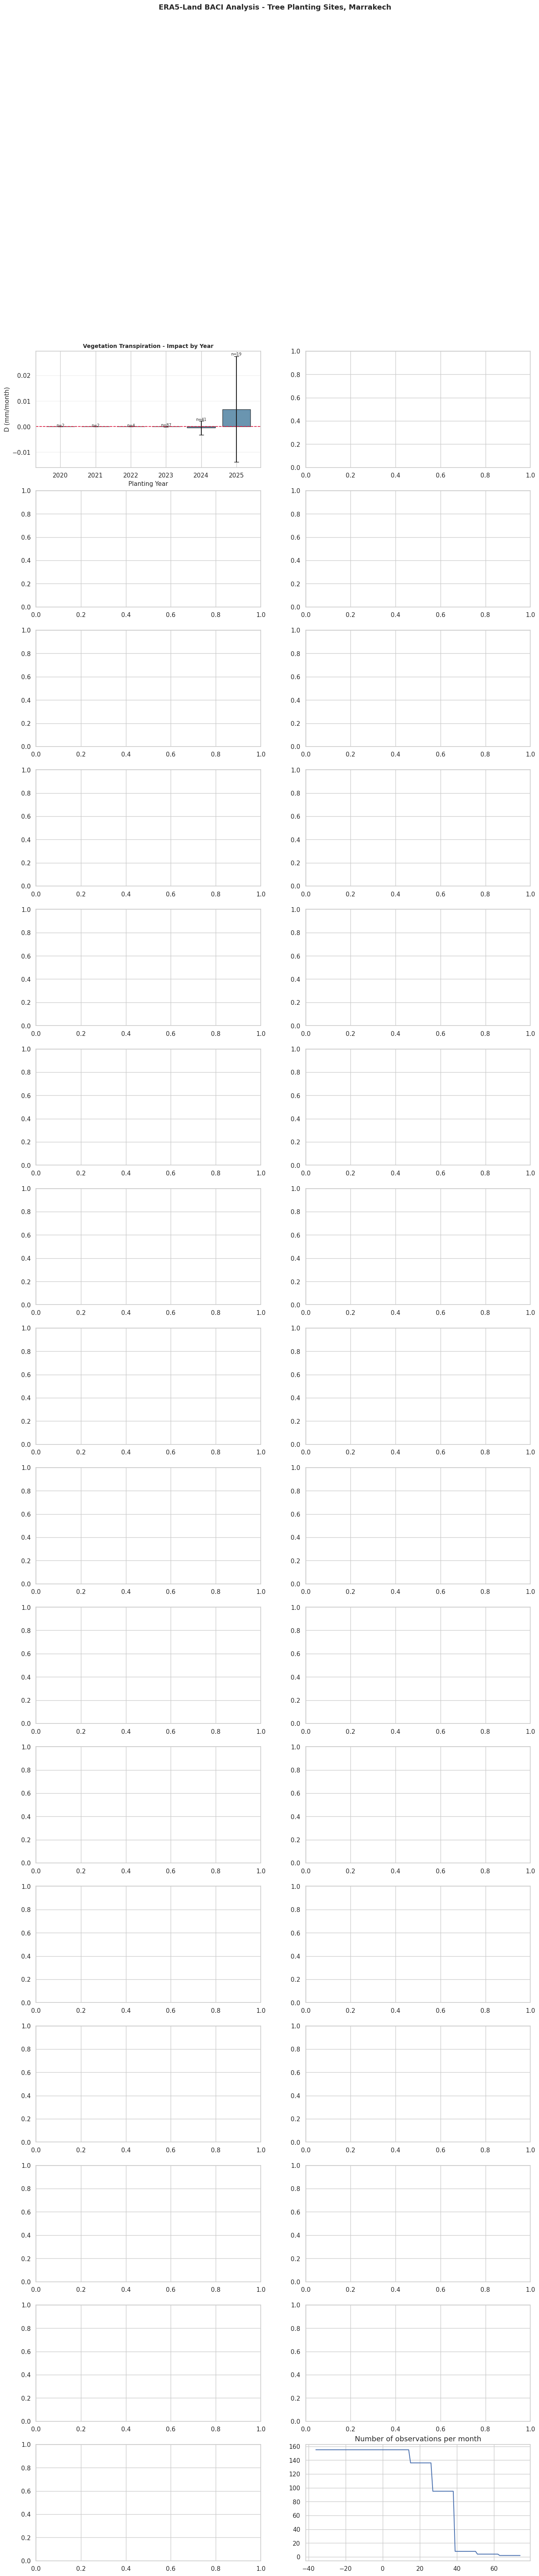

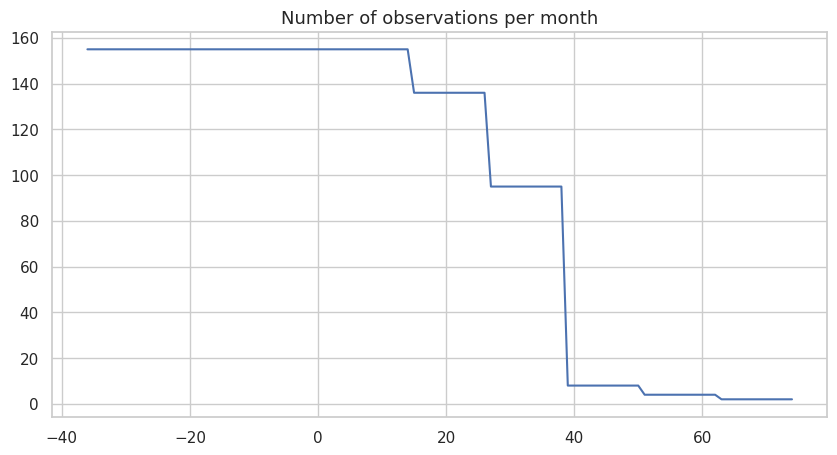

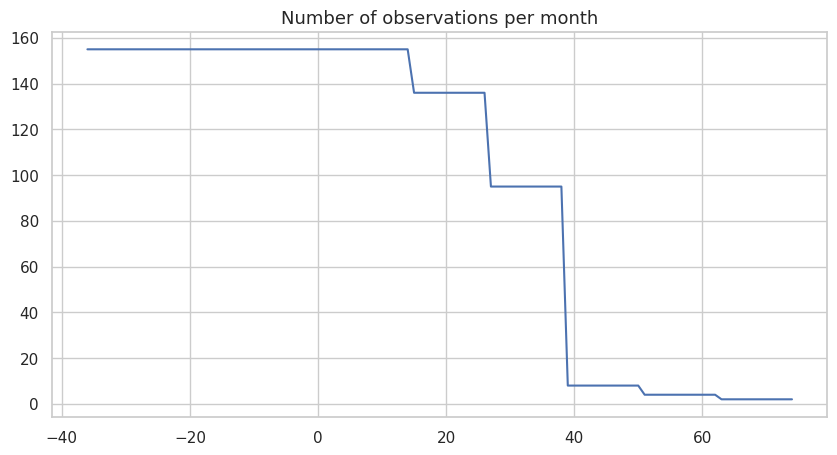

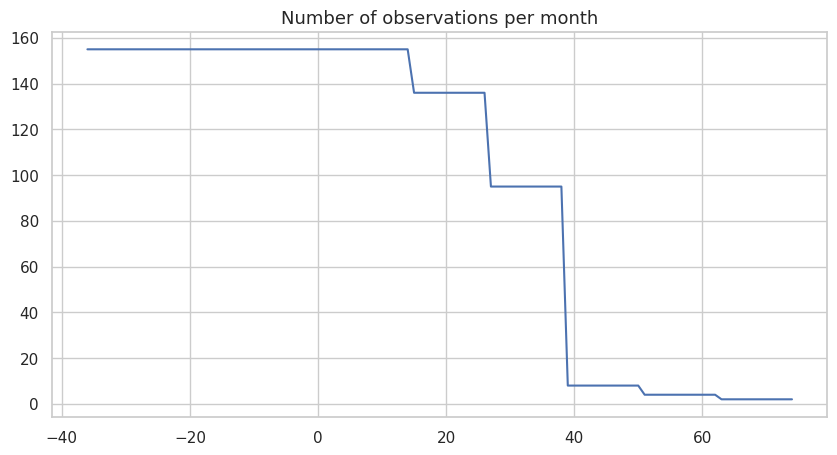

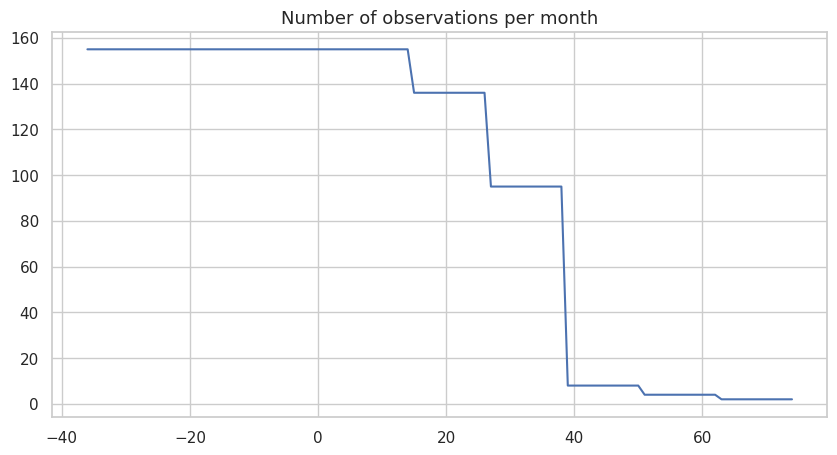

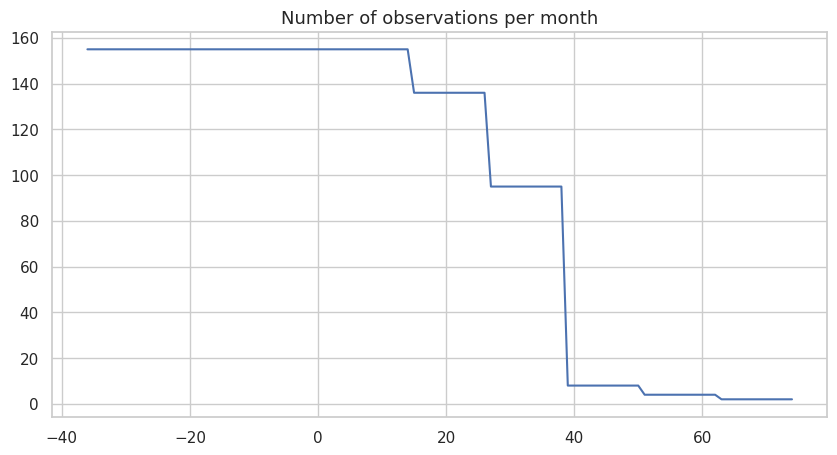

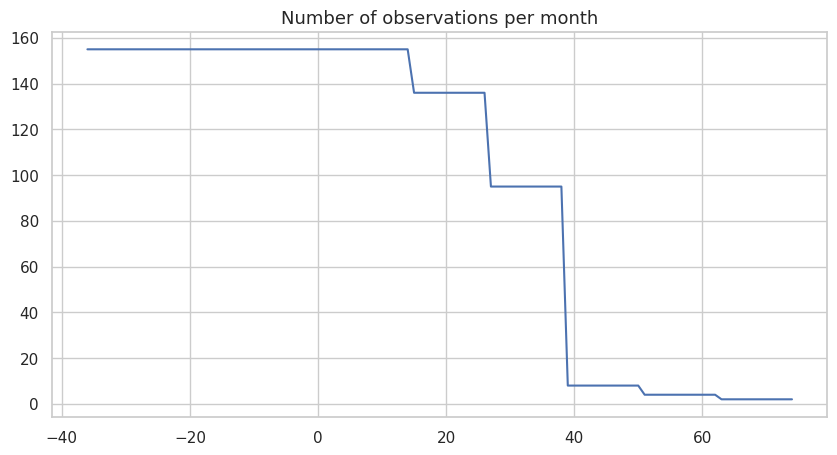

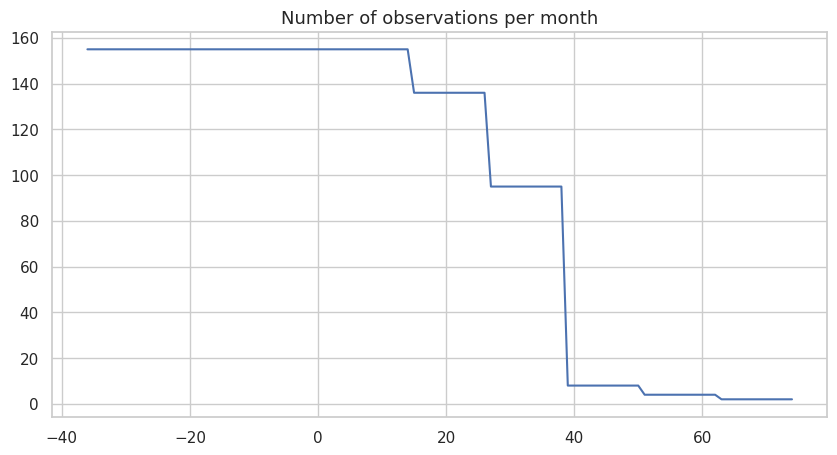

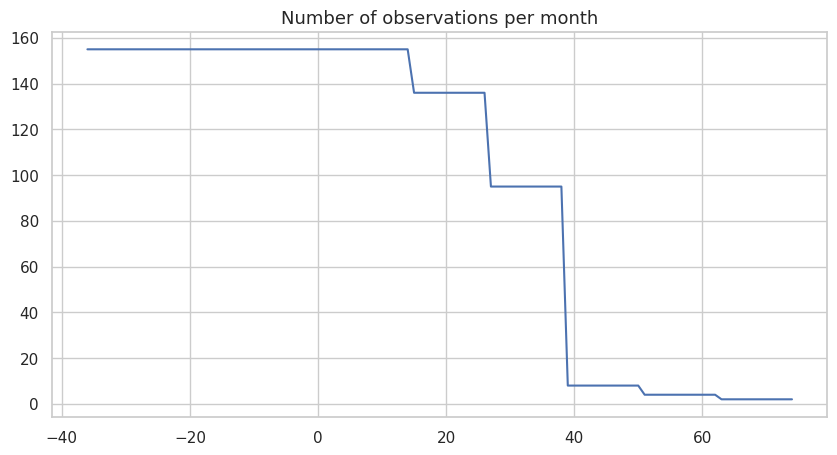

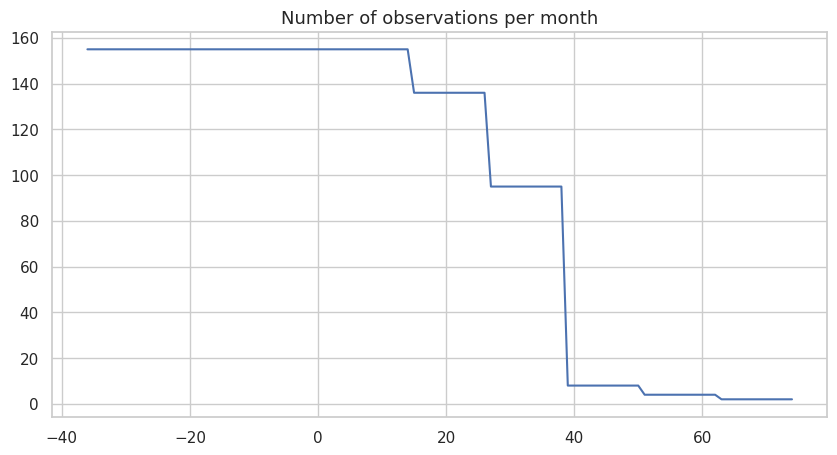

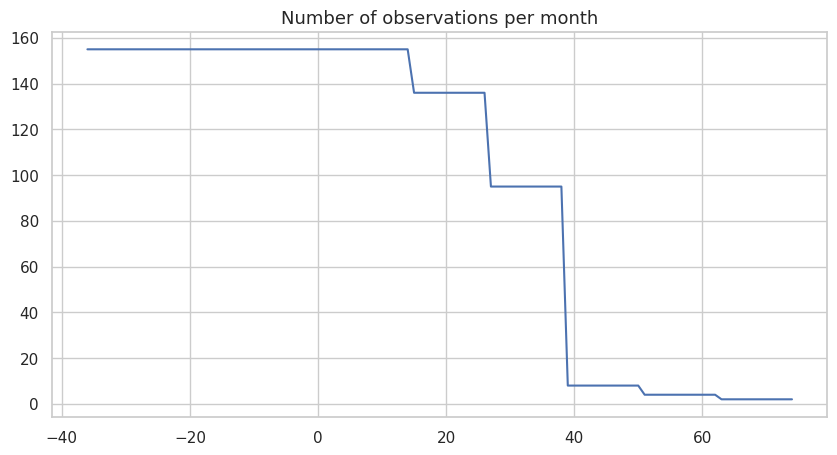

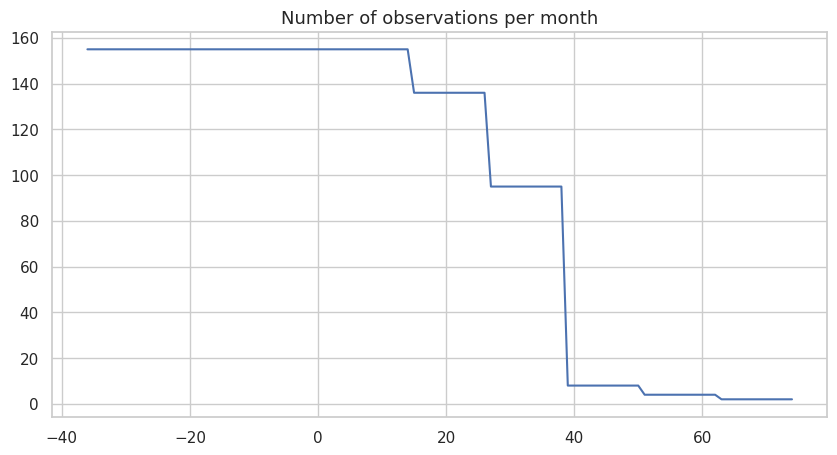

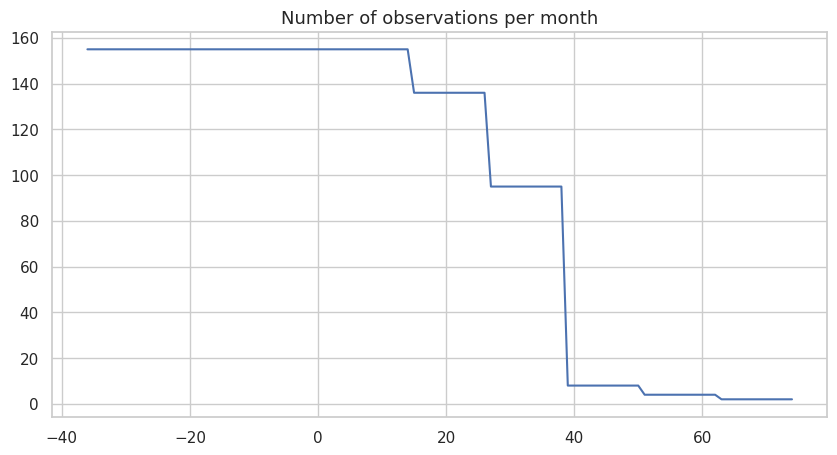

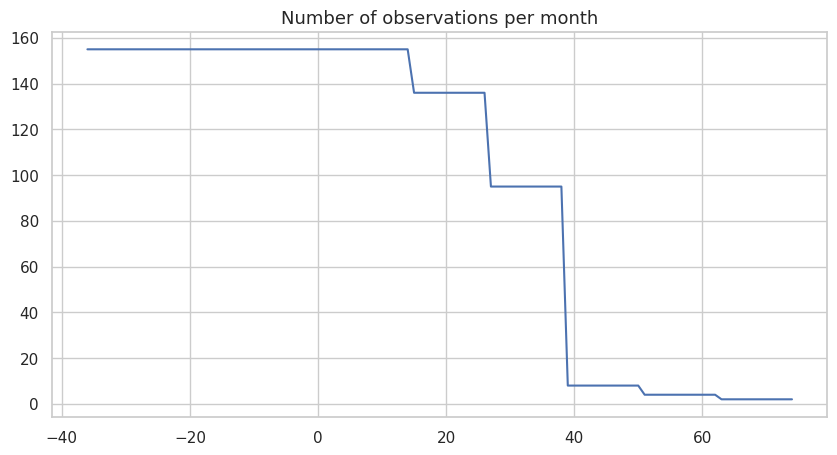

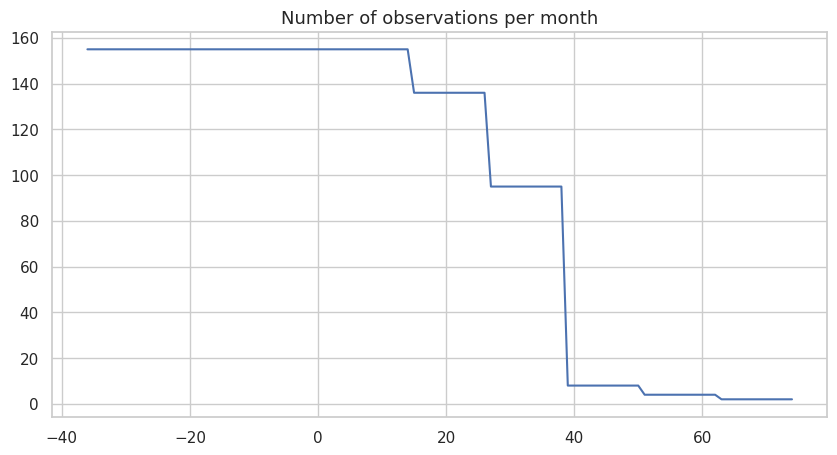

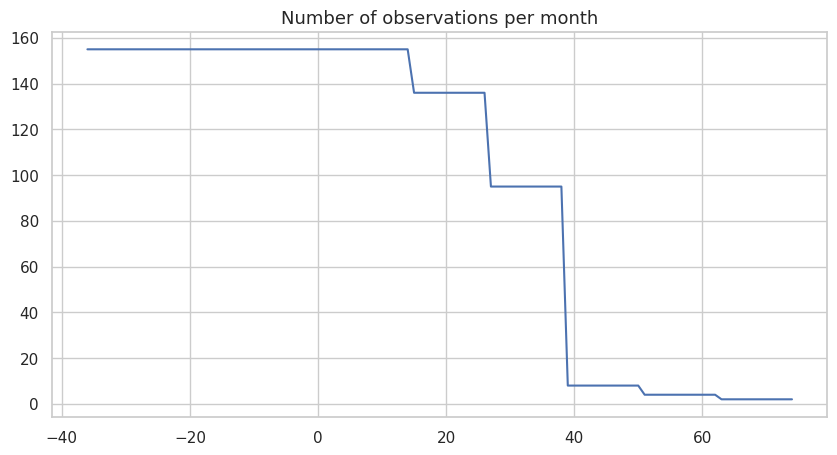

Saved -> figures/era5_summary.png


<Figure size 1000x500 with 0 Axes>

In [ ]:
_plot_era5_summary(era5_results_df, era5_all)
# _plot_era5_spatial(era5_results_df)

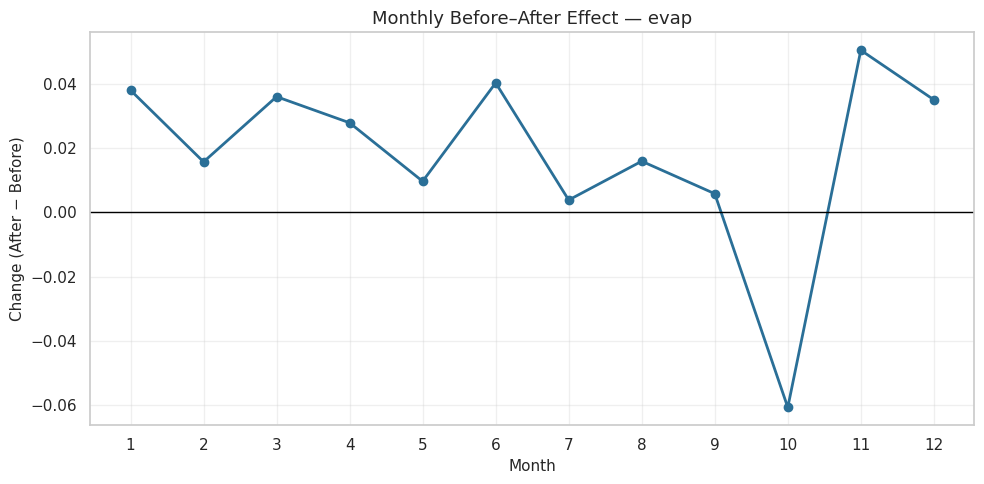

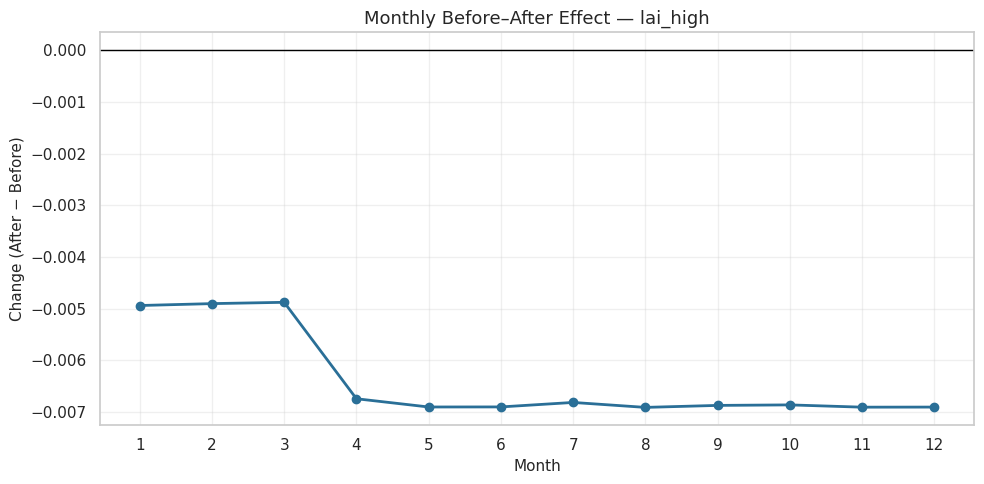

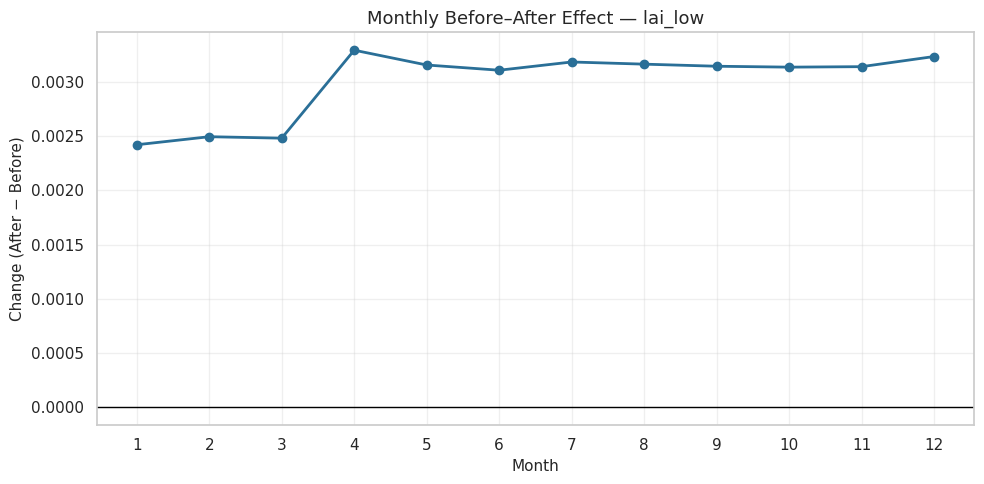

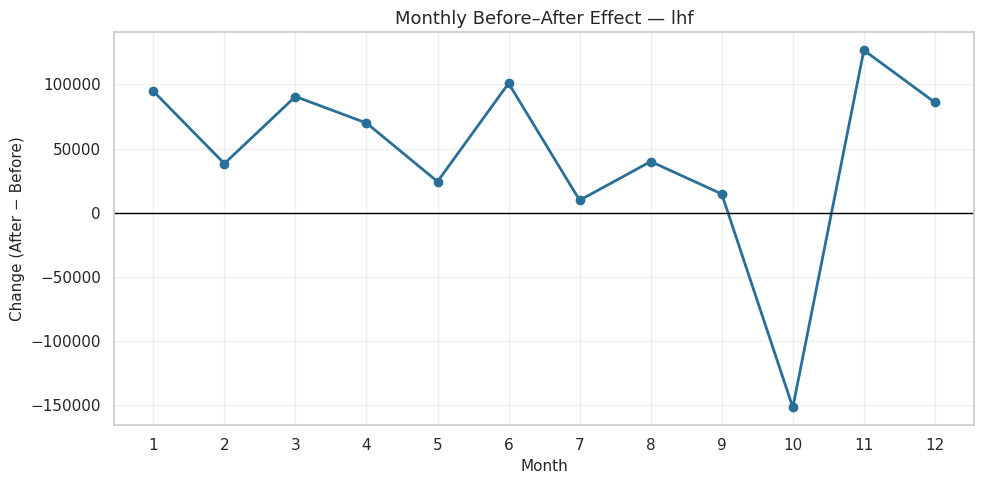

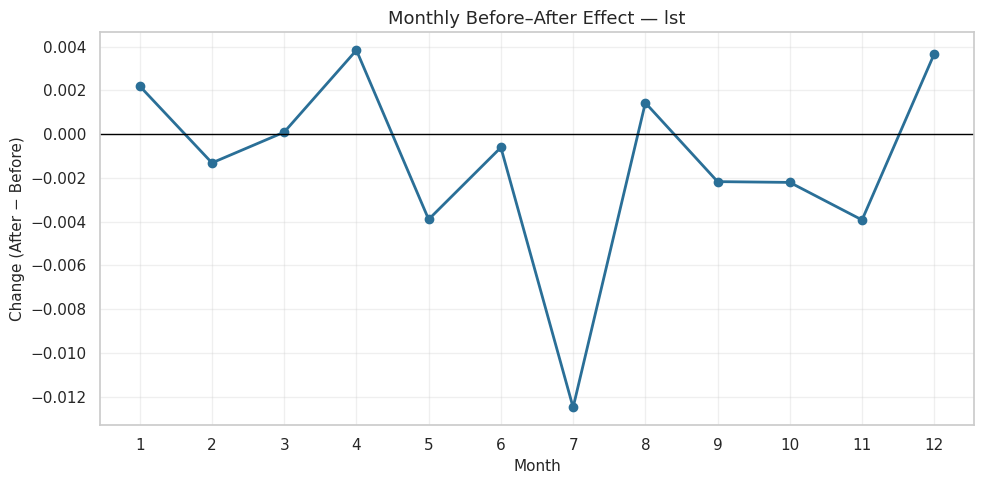

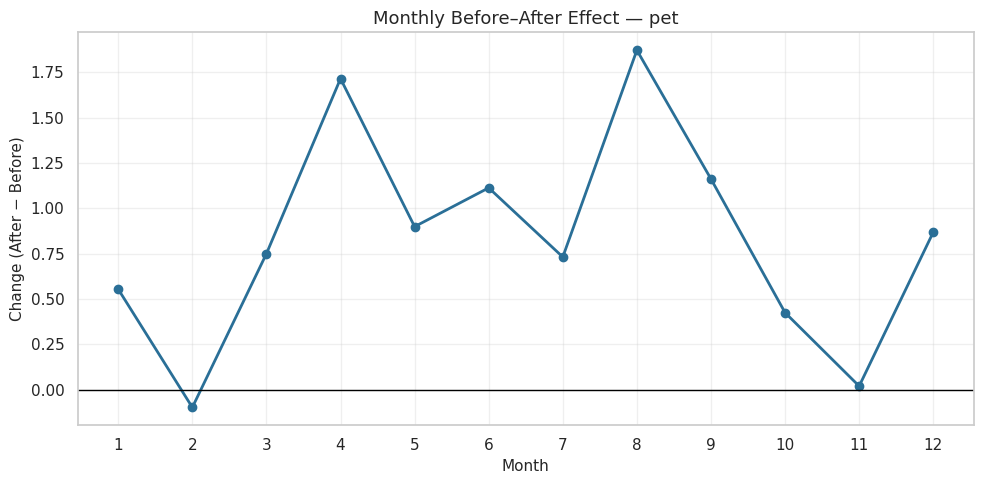

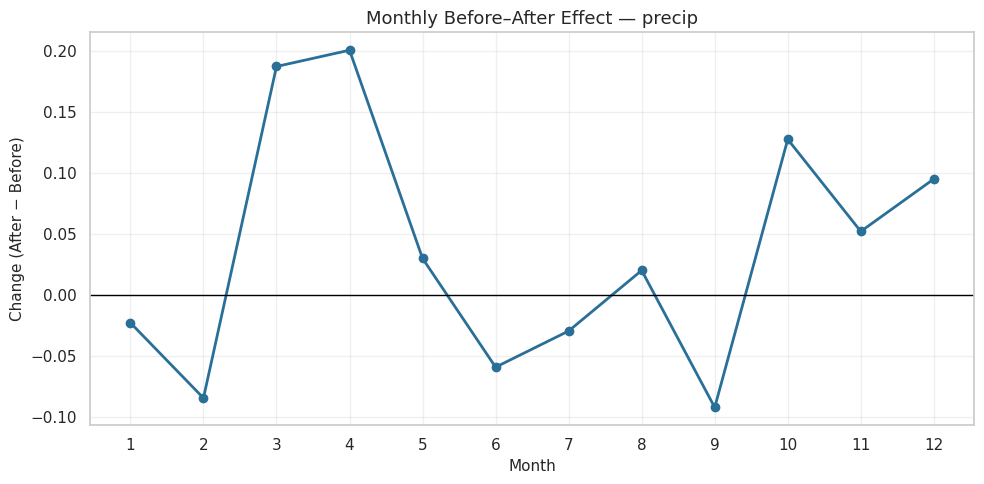

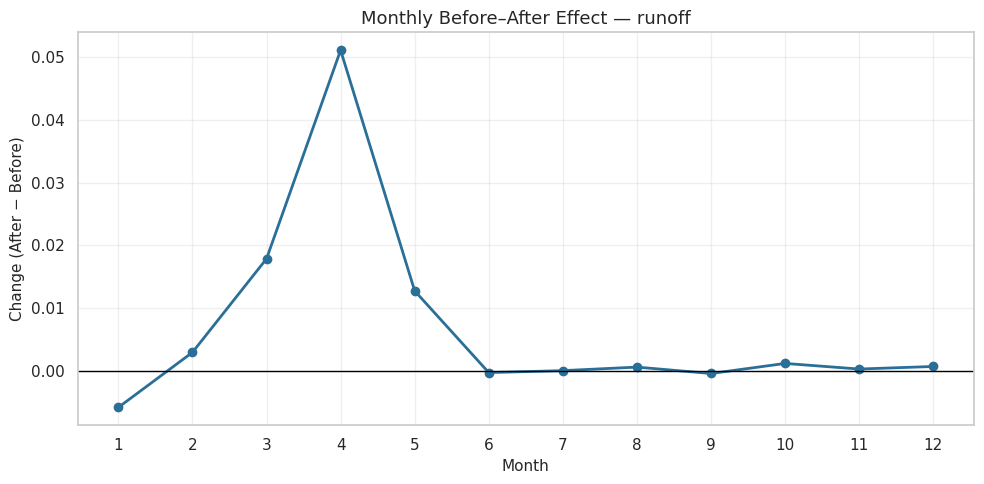

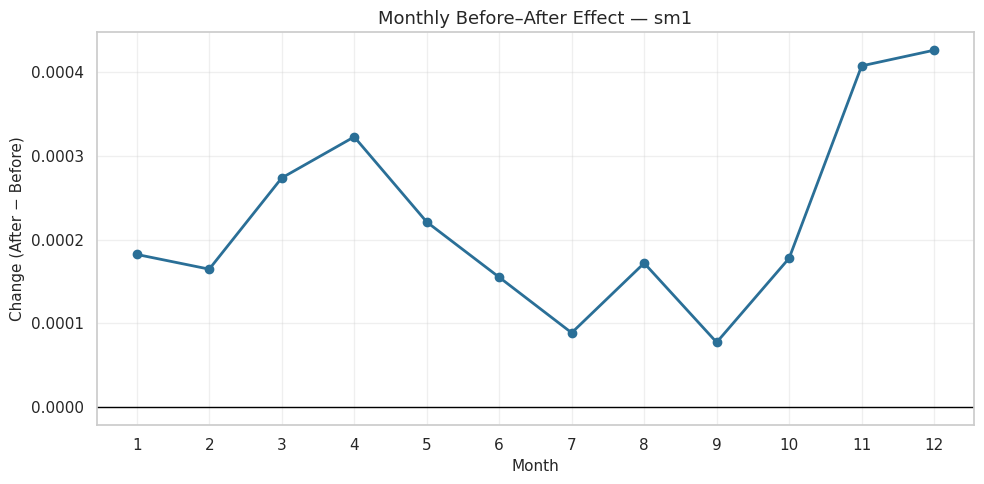

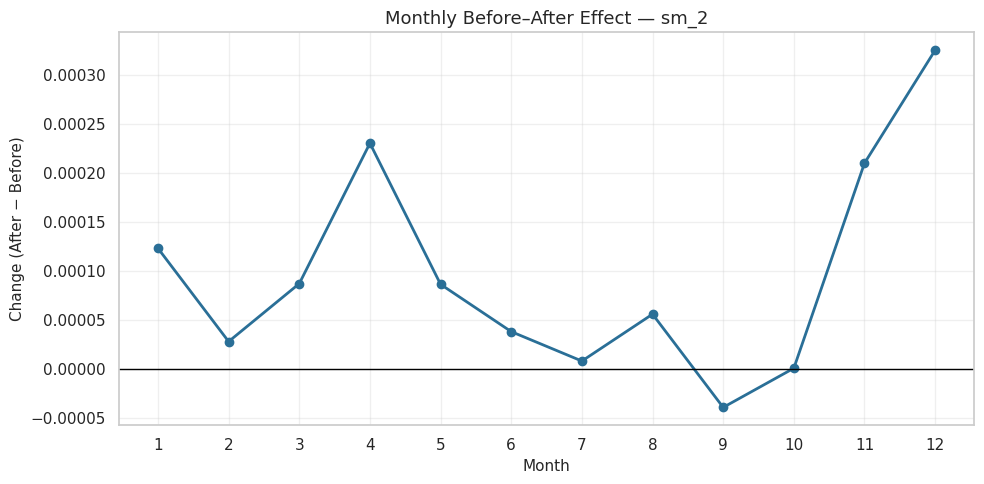

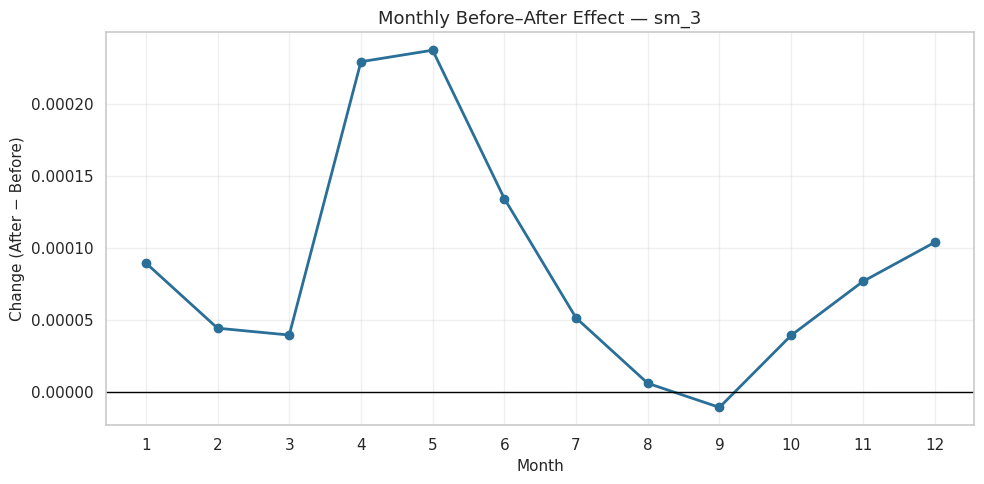

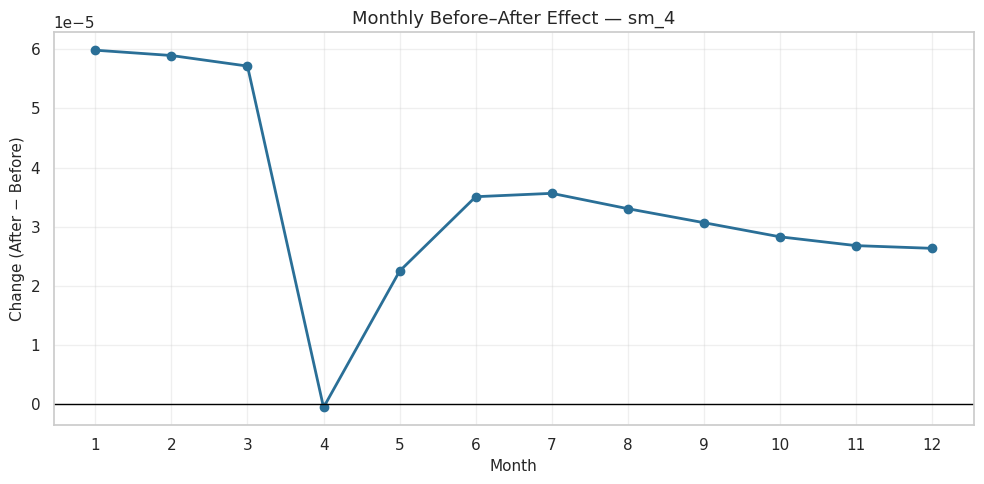

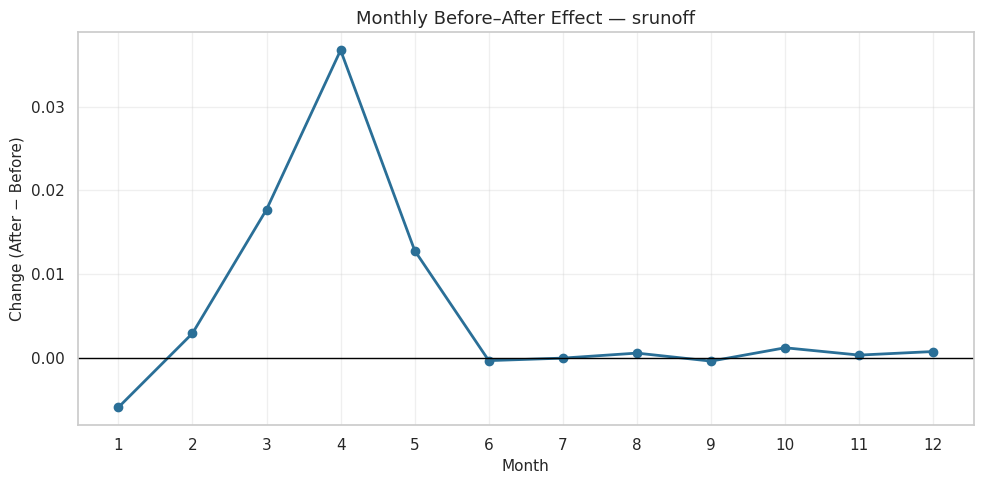

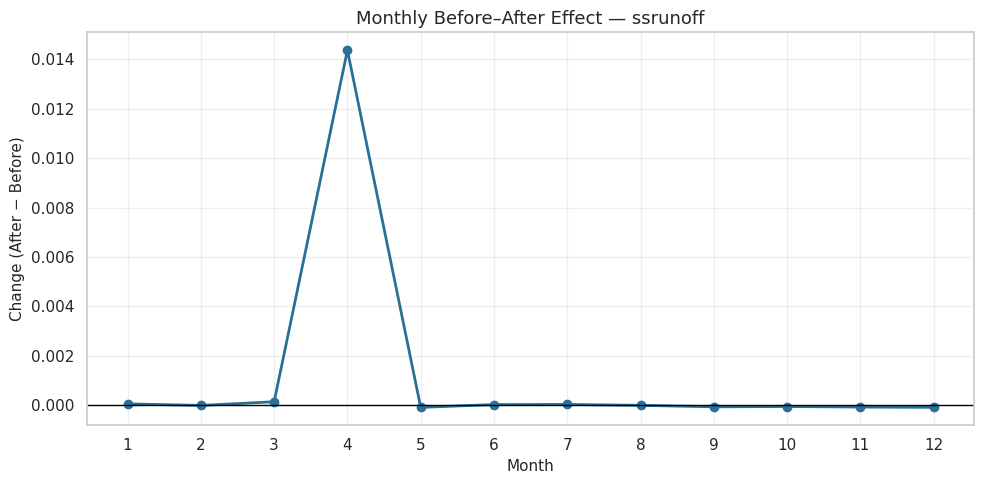

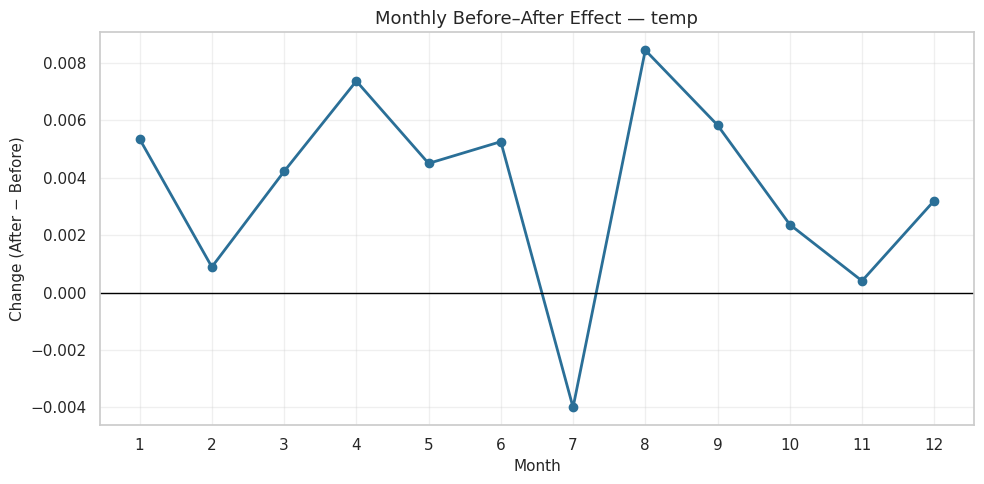

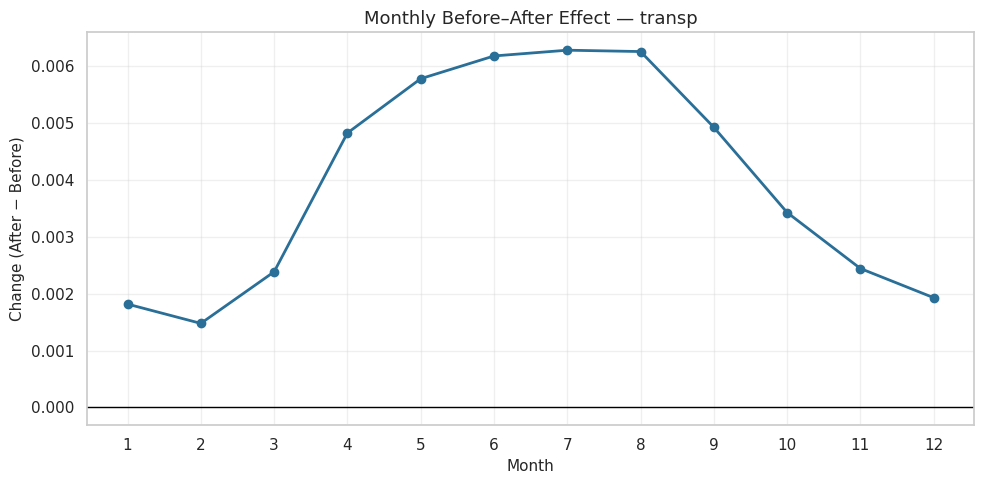

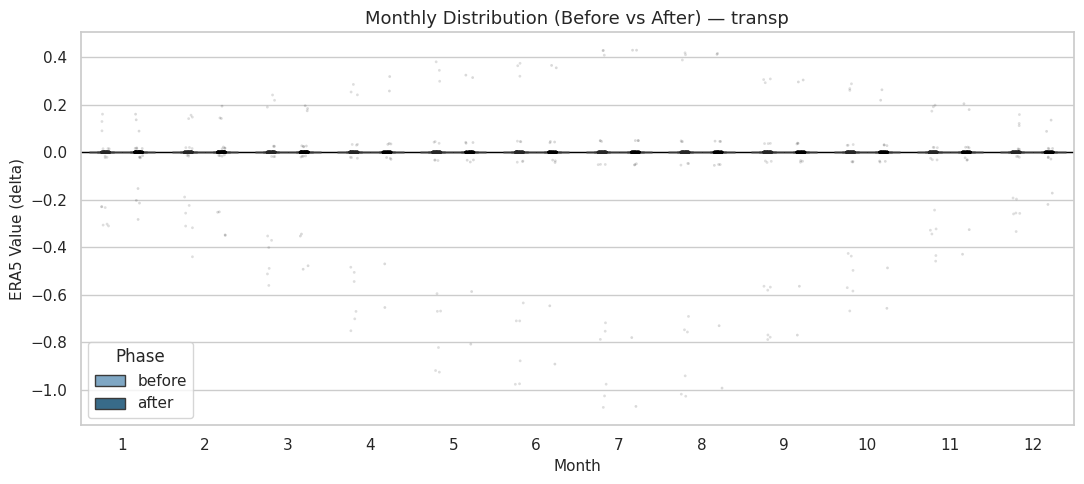

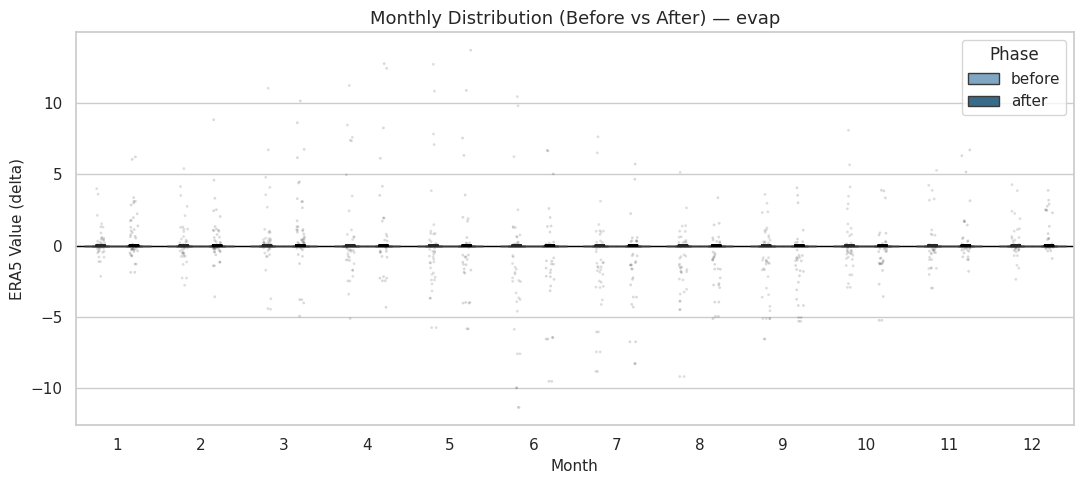

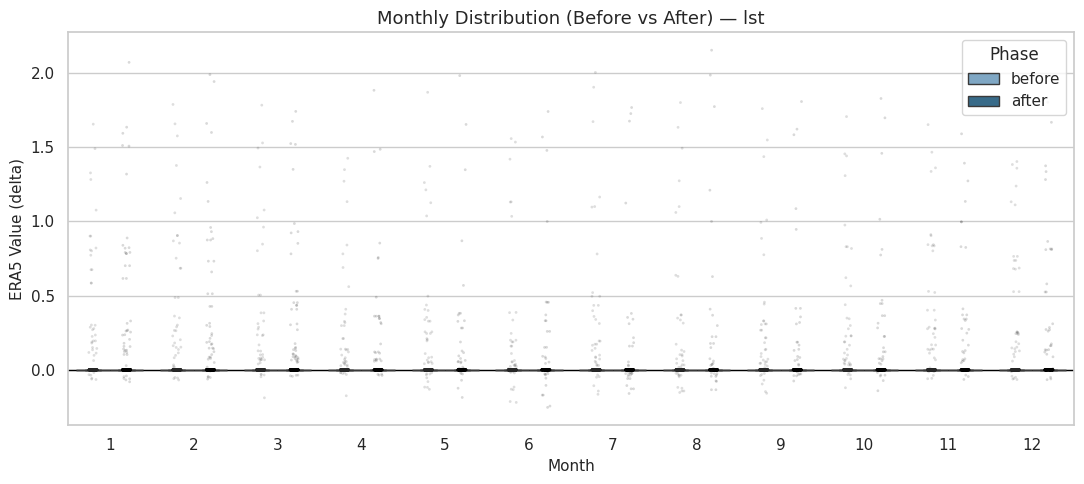

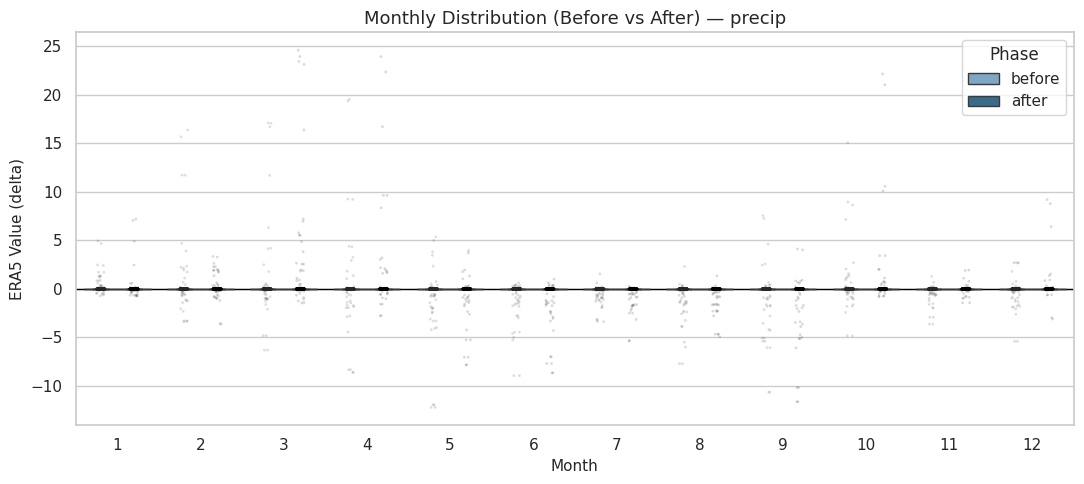

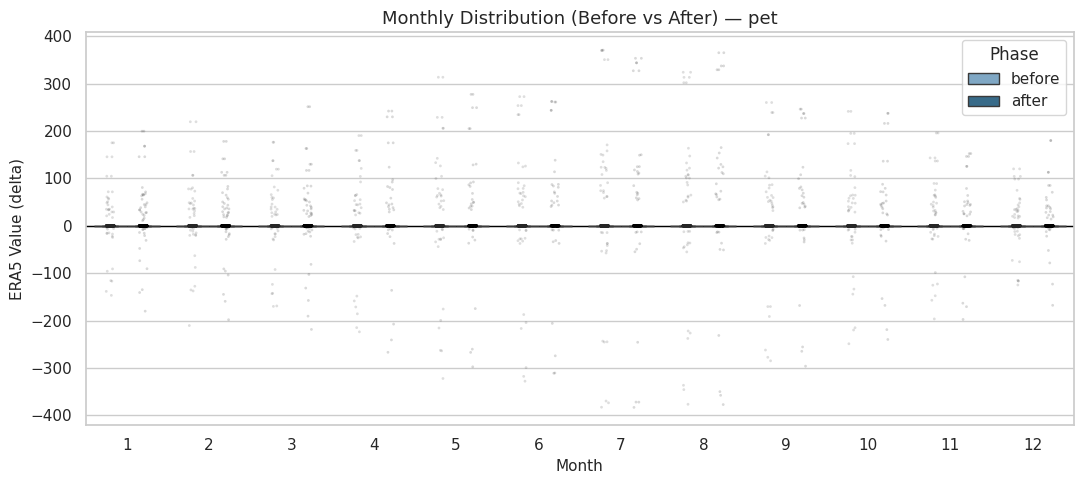

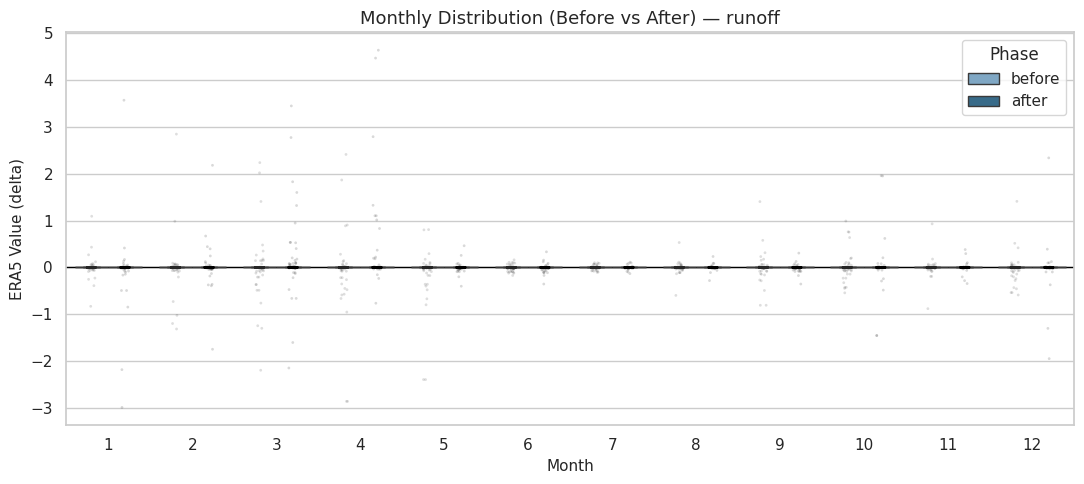

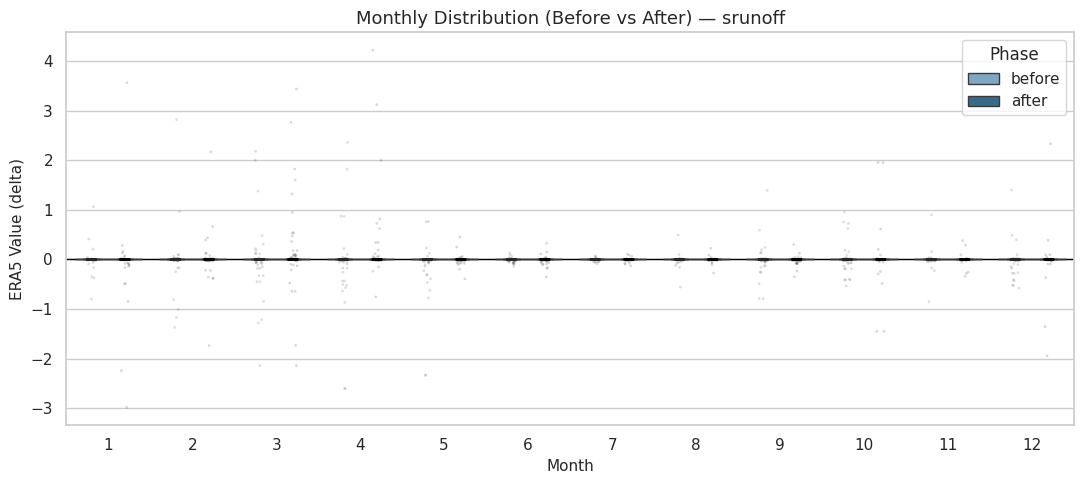

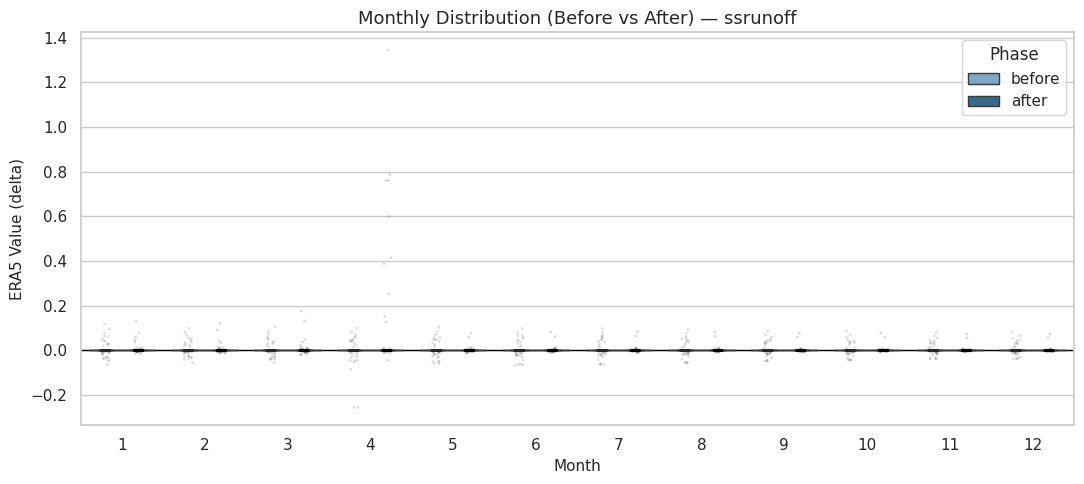

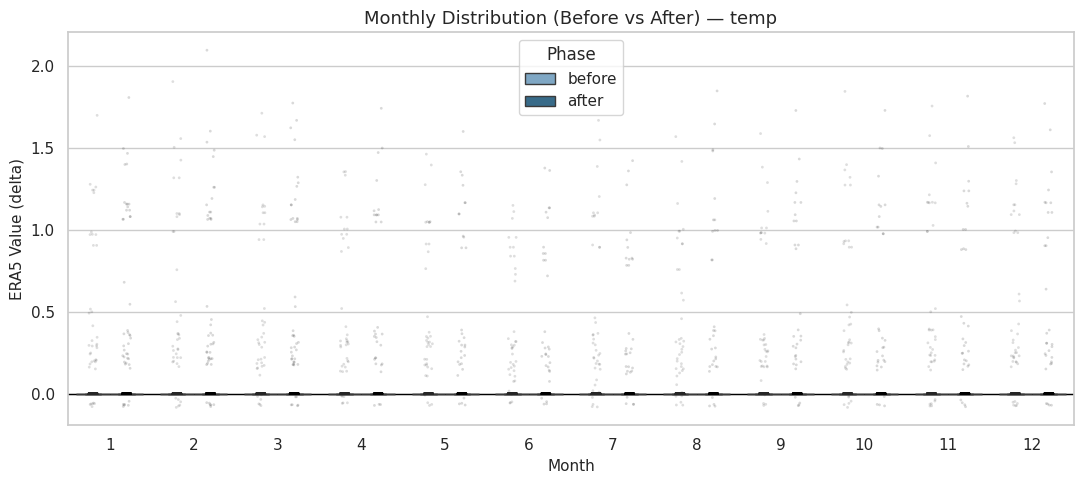

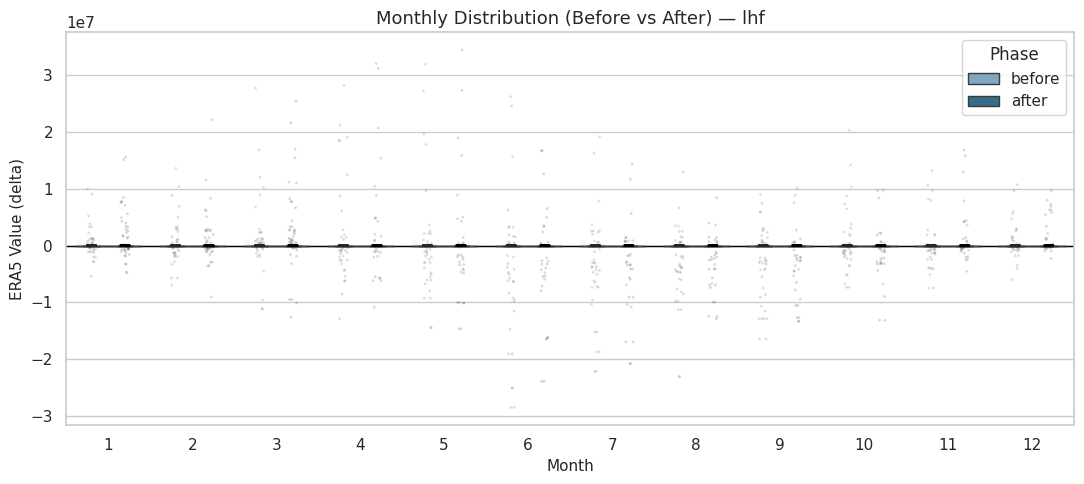

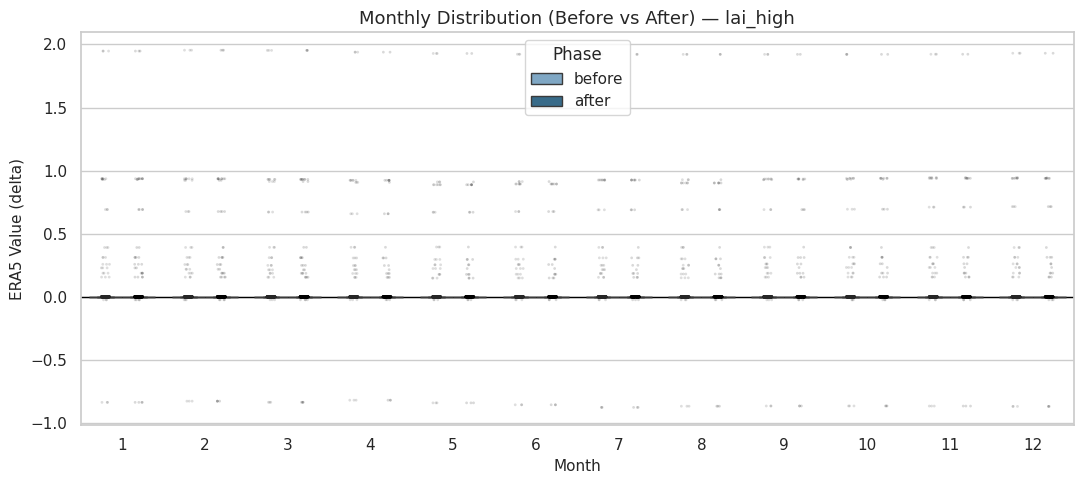

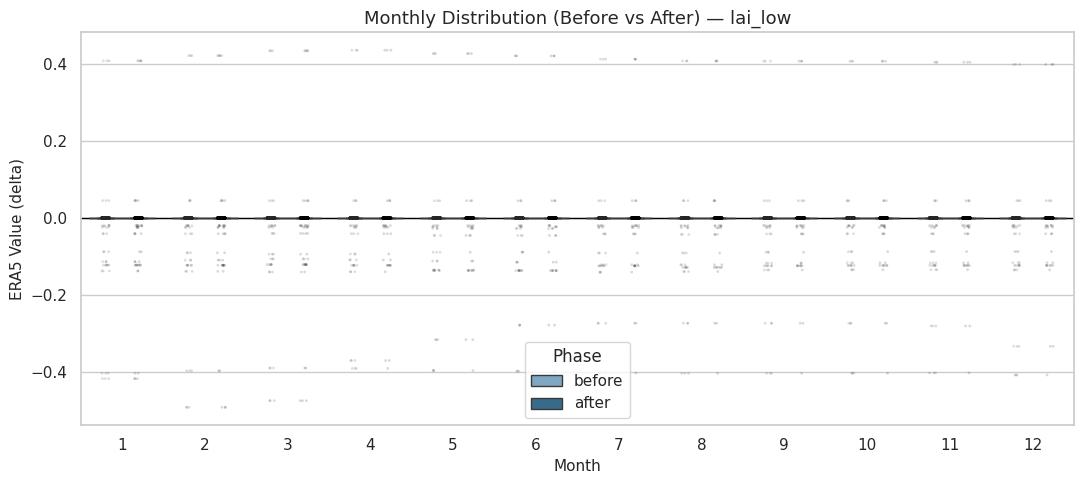

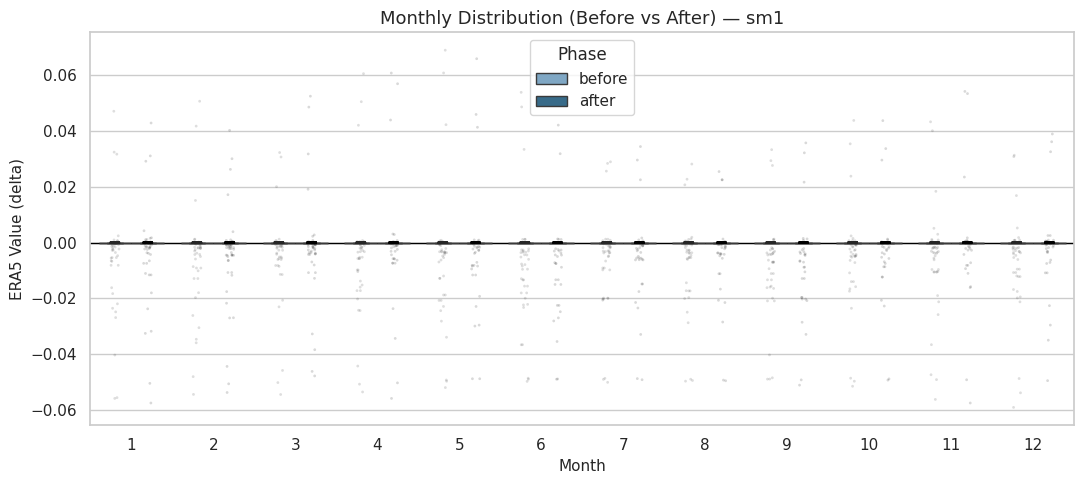

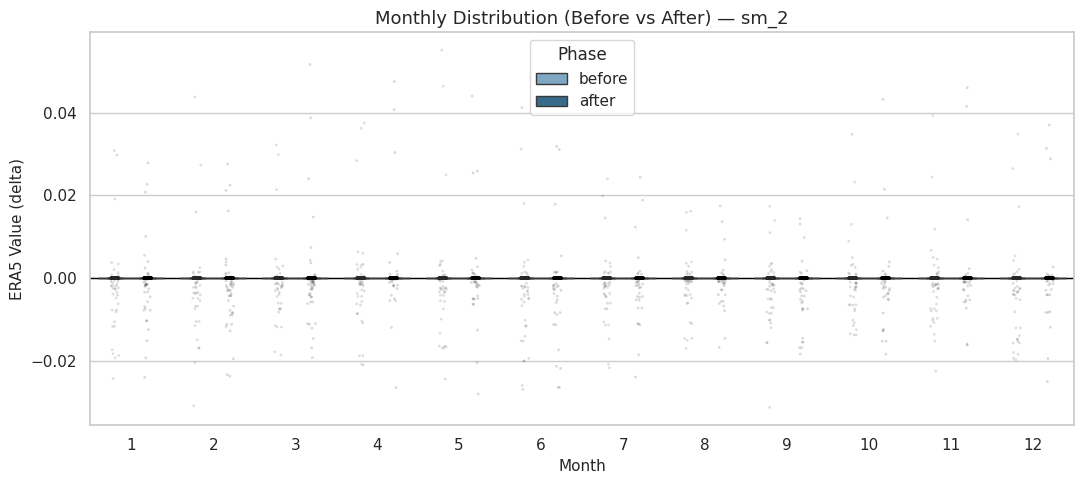

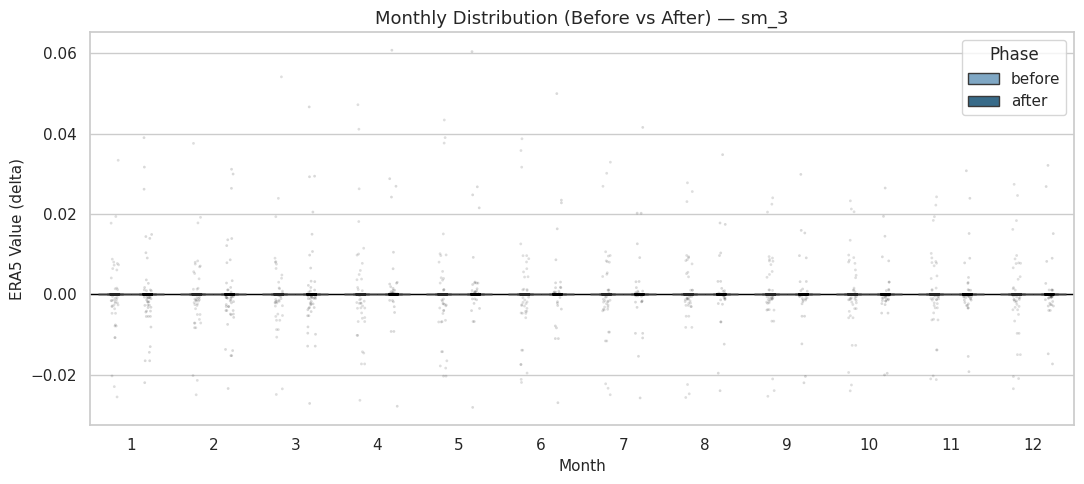

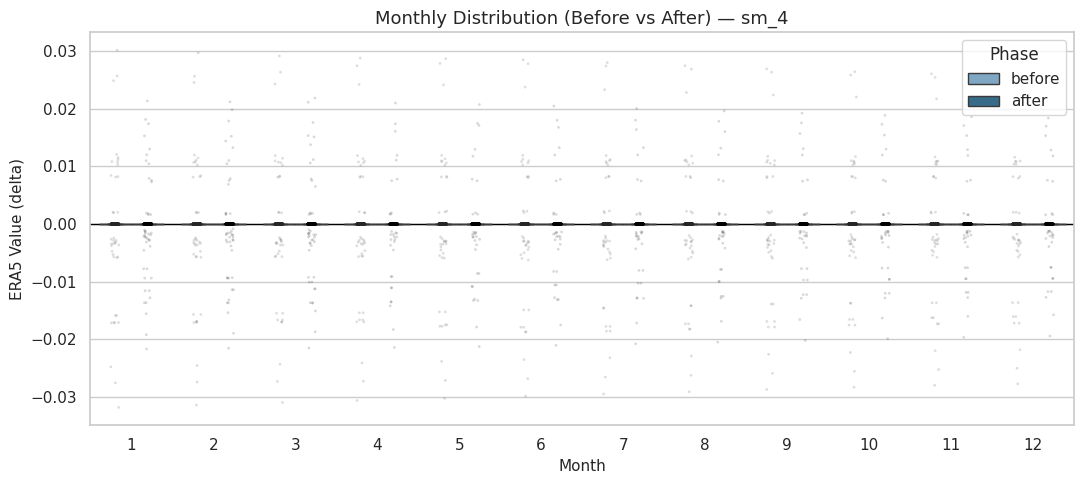

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# =========================
# 1. BUILD DATAFRAME
# =========================
frames = []

for res in era5_all:
    for var in ERA5_VARIABLES.values():
        short = var['short']
        ts = res.get('_era5_ts', {}).get(short)

        if ts is None:
            continue

        ts = ts.copy()
        ts['date'] = pd.to_datetime(ts['date'])

        ts['month'] = ts['date'].dt.month
        ts['planting_date'] = pd.to_datetime(res['planting_date'])

        ts['phase'] = np.where(
            ts['date'] < ts['planting_date'],
            'before',
            'after'
        )

        ts['variable'] = short
        frames.append(ts)

df = pd.concat(frames, ignore_index=True)

# =========================
# 2. STYLE
# =========================
sns.set_theme(style="whitegrid")

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "axes.titlesize": 13,
    "axes.labelsize": 11
})

# =========================
# 3. MONTHLY MEAN EFFECT (After - Before)
# =========================
before = df[df['phase'] == 'before']
after  = df[df['phase'] == 'after']

before_mean = before.groupby(['variable','month'])['delta'].mean()
after_mean  = after.groupby(['variable','month'])['delta'].mean()

monthly_effect = (after_mean - before_mean).reset_index()
monthly_effect.columns = ['variable','month','effect']

# =========================
# 4. MONTHLY LINE PLOTS (PER VARIABLE)
# =========================
for var in monthly_effect['variable'].unique():

    sub = monthly_effect[monthly_effect['variable'] == var].sort_values('month')

    fig, ax = plt.subplots()

    ax.plot(
        sub['month'],
        sub['effect'],
        marker='o',
        linewidth=2,
        color='#2A6F97'
    )

    ax.axhline(0, color='black', lw=1)
    ax.set_xticks(range(1,13))

    ax.set_title(f"Monthly Before–After Effect — {var}")
    ax.set_xlabel("Month")
    ax.set_ylabel("Change (After − Before)")
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

# =========================
# 5. BOXPLOT DATA (MONTH + PHASE COMPARISON)
# =========================
box_data = df.copy()

# =========================
# 6. BOXPLOTS: BEFORE vs AFTER BY MONTH (PER VARIABLE)
# =========================
for var in box_data['variable'].unique():

    sub = box_data[box_data['variable'] == var]

    plt.figure(figsize=(11,5))

    sns.boxplot(
        data=sub,
        x='month',
        y='delta',
        hue='phase',
        showfliers=False,
        palette={'before':'#74A9CF', 'after':'#2A6F97'}
    )

    sns.stripplot(
        data=sub,
        x='month',
        y='delta',
        hue='phase',
        dodge=True,
        color='black',
        alpha=0.15,
        size=2
    )

    # remove duplicate legend from stripplot
    handles, labels = plt.gca().get_legend_handles_labels()
    plt.legend(handles[:2], labels[:2], title="Phase")

    plt.axhline(0, color='black', lw=1)

    plt.title(f"Monthly Distribution (Before vs After) — {var}")
    plt.xlabel("Month")
    plt.ylabel("ERA5 Value (delta)")
    plt.tight_layout()
    plt.show()

In [ ]:
combined.groupby('mo')['delta'].count()

NameError: name 'combined' is not defined

## old

HLS NDVI IMPACT ANALYSIS - TREE PLANTING SITES
Before-After Control-Impact (BACI) Design with 3 Closest Control Sites

ANALYZING ALL FARMS WITH 3 CLOSEST CONTROLS

Farm 255762007: Planted in 2023
  Selected 3 control sites at distances: ['343m', '578m', '615m']
  Treatment buffer: 100m
  Monthly composites: 59

Extracting NDVI time series...
  Extracted 59 valid observations
  Mean ΔNDVI: -0.0048 ± 0.0197
  Baseline: 36 obs, ΔNDVI = -0.0069
  Impact: 17 obs, ΔNDVI = -0.0058
  Change: +0.0012, p-value: 0.8876

Farm 255762013: Planted in 2023
  Selected 3 control sites at distances: ['116m', '127m', '154m']
  Treatment buffer: 30m
  Monthly composites: 59

Extracting NDVI time series...
  Extracted 59 valid observations
  Mean ΔNDVI: -0.0234 ± 0.0177
  Baseline: 36 obs, ΔNDVI = -0.0238
  Impact: 17 obs, ΔNDVI = -0.0183
  Change: +0.0055, p-value: 0.5218

Farm 255762023: Planted in 2023
  Selected 3 control sites at distances: ['402m', '495m', '503m']
  Treatment buffer: 48m
  Monthly com

  Selected 3 control sites at distances: ['182m', '213m', '230m']
  Treatment buffer: 30m
  Monthly composites: 59

Extracting NDVI time series...
  Extracted 59 valid observations
  Mean ΔNDVI: 0.0310 ± 0.0636
  Baseline: 36 obs, ΔNDVI = 0.0199
  Impact: 17 obs, ΔNDVI = 0.0515
  Change: +0.0316, p-value: 0.2140

Farm 261430486: Planted in 2023
  Selected 3 control sites at distances: ['247m', '259m', '289m']
  Treatment buffer: 30m
  Monthly composites: 59

Extracting NDVI time series...
  Extracted 59 valid observations
  Mean ΔNDVI: 0.0305 ± 0.0546
  Baseline: 36 obs, ΔNDVI = 0.0082
  Impact: 17 obs, ΔNDVI = 0.0639
  Change: +0.0557, p-value: 0.0543

Farm 261433290: Planted in 2023
  Selected 3 control sites at distances: ['529m', '551m', '572m']
  Treatment buffer: 100m
  Monthly composites: 59

Extracting NDVI time series...
  Extracted 59 valid observations
  Mean ΔNDVI: -0.1361 ± 0.0432
  Baseline: 36 obs, ΔNDVI = -0.1467
  Impact: 17 obs, ΔNDVI = -0.1280
  Change: +0.0187, p-va

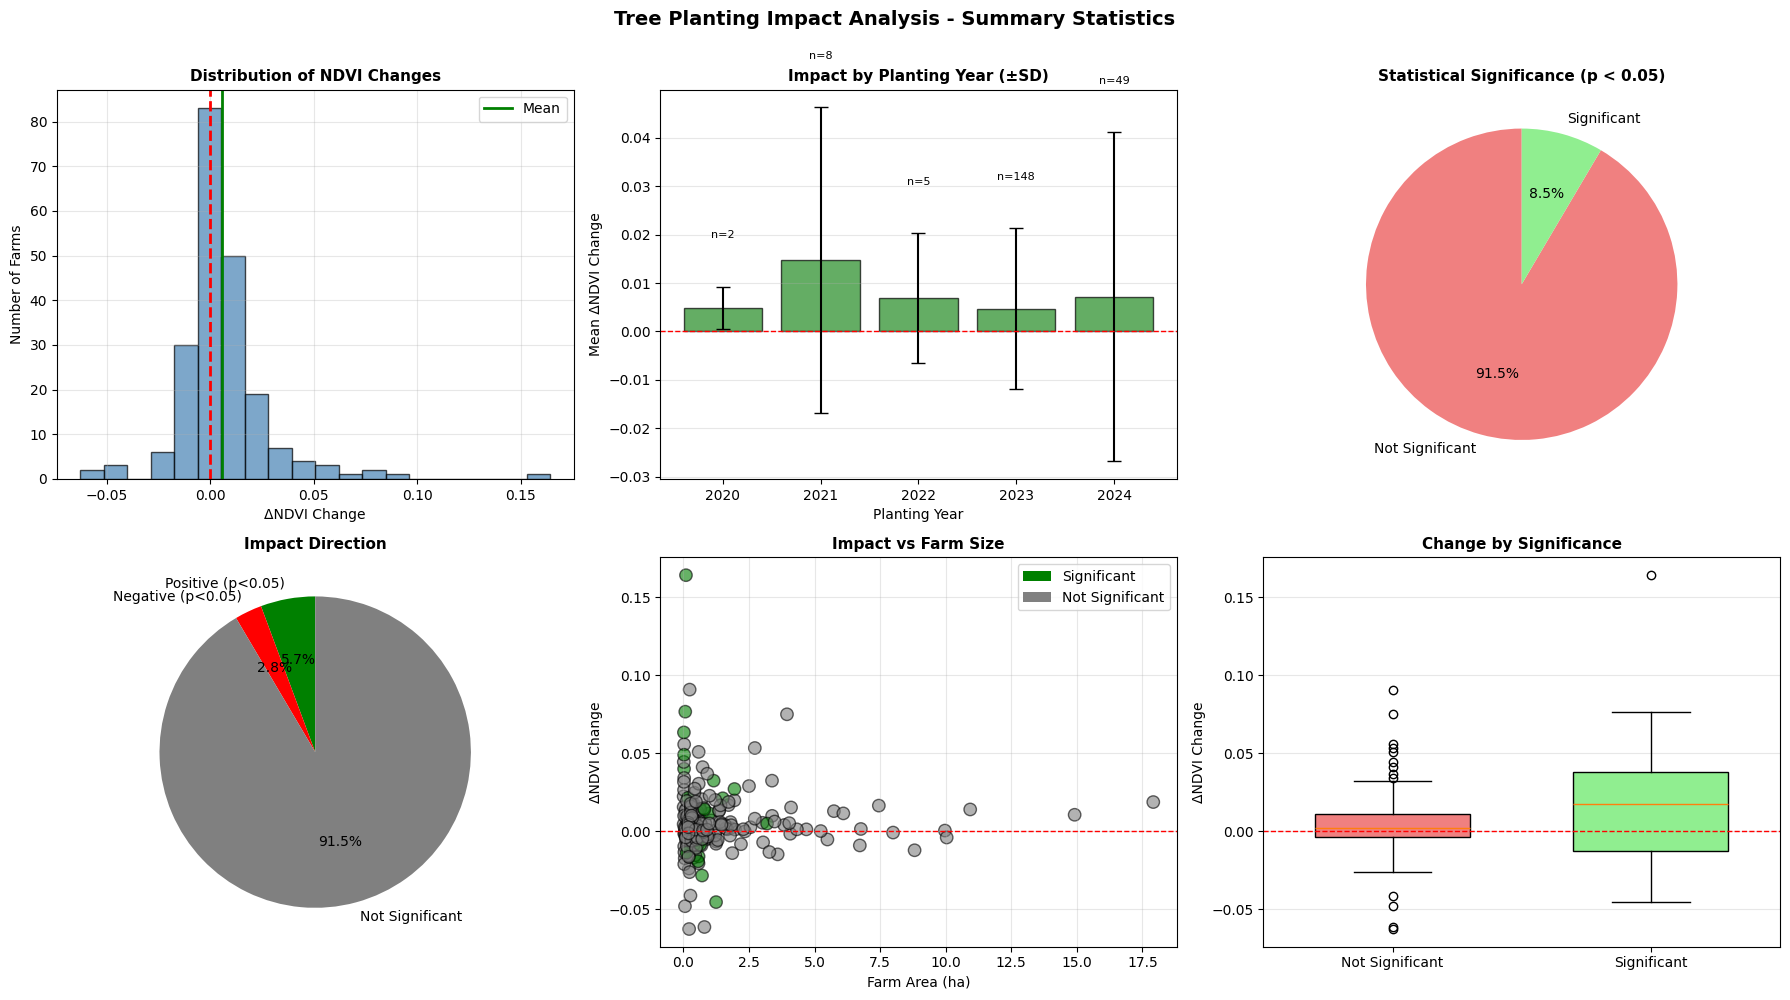


Creating aggregate time series plot...
✓ Aggregate time series plot saved to 'aggregate_time_series.png'


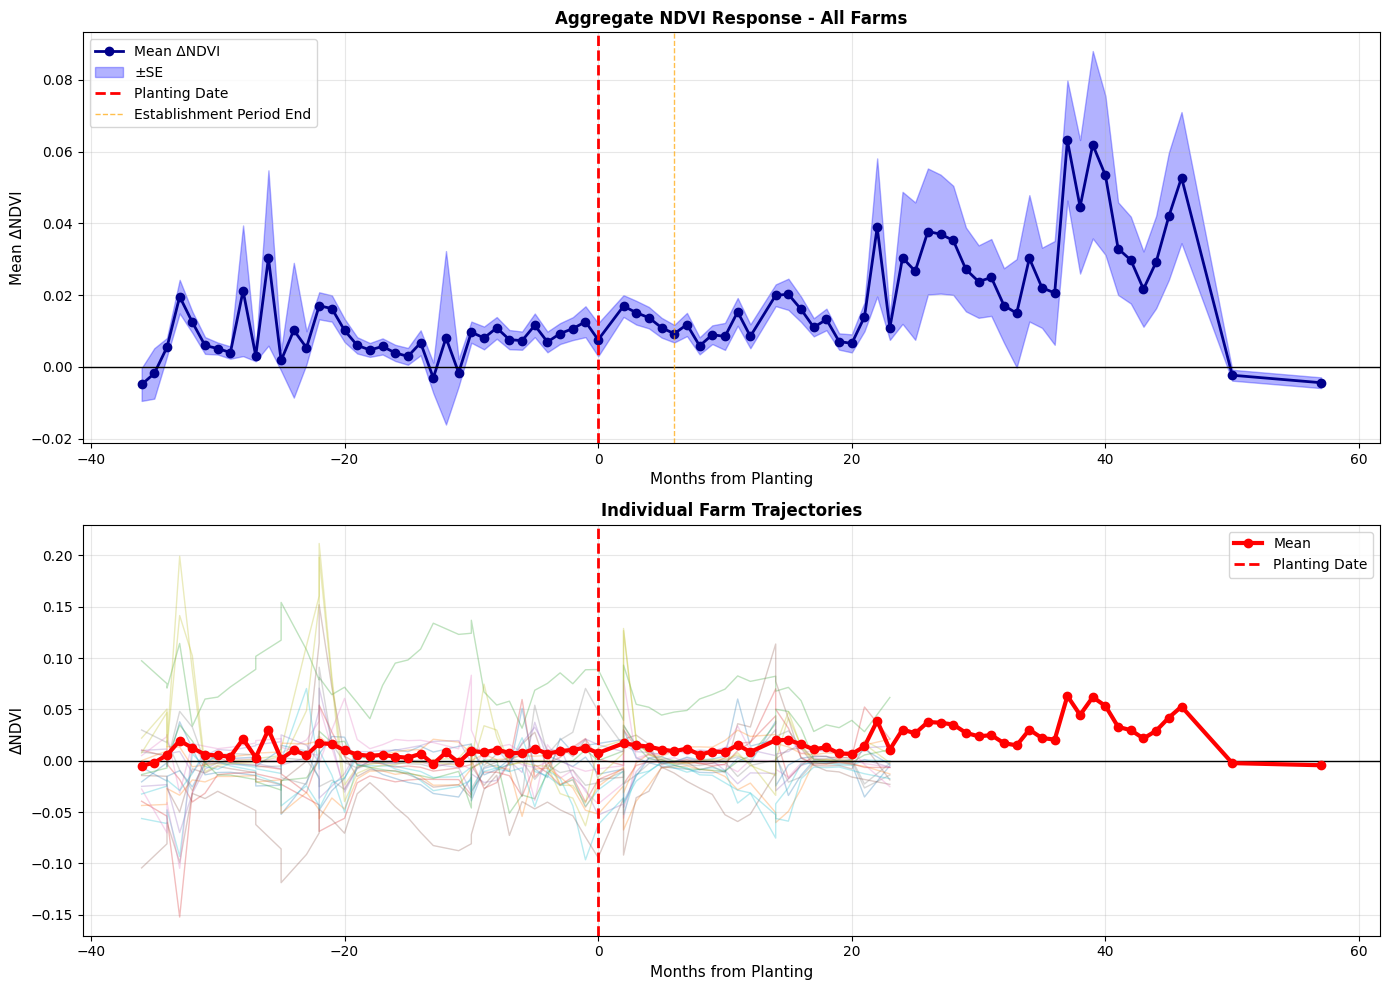


Creating spatial distribution map...
✓ Spatial distribution map saved to 'spatial_distribution_map.png'


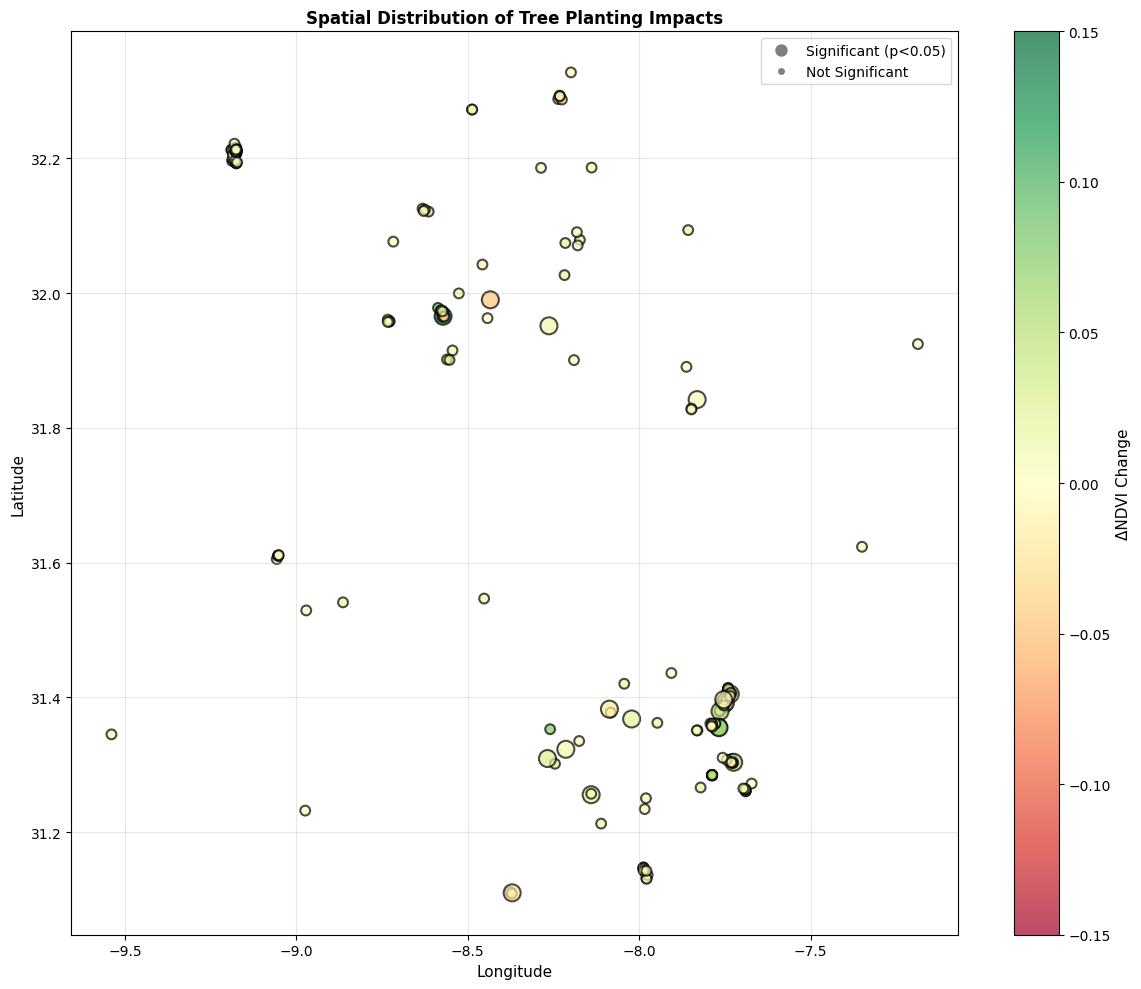


ALL PROCESSING COMPLETE

Generated files:
  • farm_impact_results_top3controls.csv - Detailed results for all farms
  • aggregate_summary_statistics.png - 6-panel summary statistics
  • aggregate_time_series.png - Aggregate temporal response
  • spatial_distribution_map.png - Geographic distribution of impacts


In [ ]:
# ============================================================================
# STEP 0: Fix package compatibility (run once, then restart runtime)
# ============================================================================
# Uncomment and run these lines, then restart runtime:
# import subprocess, sys
# subprocess.check_call([sys.executable, "-m", "pip", "install",
#                       "numpy==1.26.4", "scipy==1.12.0", "-q"])
# print("✓ Please RESTART RUNTIME, then run the rest of the code")

# ============================================================================
# After restarting runtime, run from here:
# ============================================================================

import ee
import geemap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from datetime import datetime

# Import scipy with error handling
try:
    from scipy import stats
    SCIPY_AVAILABLE = True
except ImportError:
    print("Warning: SciPy not available. Using alternative statistics.")
    SCIPY_AVAILABLE = False

    # Simple t-test implementation as fallback
    class SimpleStats:
        @staticmethod
        def ttest_ind(a, b):
            """Simple independent t-test"""
            n1, n2 = len(a), len(b)
            mean1, mean2 = np.mean(a), np.mean(b)
            var1, var2 = np.var(a, ddof=1), np.var(b, ddof=1)

            pooled_se = np.sqrt(var1/n1 + var2/n2)
            t_stat = (mean1 - mean2) / pooled_se

            # Approximate p-value (two-tailed)
            df = n1 + n2 - 2
            # Rough approximation
            p_value = 2 * (1 - 0.5 * (1 + np.tanh(abs(t_stat)/2)))

            return t_stat, p_value

        @staticmethod
        def linregress(x, y):
            """Simple linear regression"""
            n = len(x)
            x_mean, y_mean = np.mean(x), np.mean(y)

            slope = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean)**2)
            intercept = y_mean - slope * x_mean

            y_pred = slope * x + intercept
            ss_tot = np.sum((y - y_mean)**2)
            ss_res = np.sum((y - y_pred)**2)
            r_squared = 1 - (ss_res / ss_tot)
            r_value = np.sqrt(r_squared) if r_squared > 0 else 0

            # Standard error
            std_err = np.sqrt(ss_res / (n - 2)) / np.sqrt(np.sum((x - x_mean)**2))

            # Approximate p-value
            t_stat = slope / std_err if std_err > 0 else 0
            p_value = 2 * (1 - 0.5 * (1 + np.tanh(abs(t_stat)/2)))

            return slope, intercept, r_value, p_value, std_err

    stats = SimpleStats()

print("="*80)
print("HLS NDVI IMPACT ANALYSIS - TREE PLANTING SITES")
print("Before-After Control-Impact (BACI) Design with 3 Closest Control Sites")
print("="*80)

# ===================================================================
# STEP 1: DEFINE TREATMENT AND TOP 3 CONTROL AREAS
# ===================================================================

def create_treatment_and_top3_controls(farm_row, dem):
    """
    Create treatment mask and identify 3 closest terrain-matched control sites.

    Parameters:
    - farm_row: Single row from farm_df with farm characteristics
    - dem: Digital Elevation Model (SRTM or similar)

    Returns treatment geometry and list of 3 control geometries
    """

    farm_id = farm_row['farm_id']
    lon = farm_row['lon']
    lat = farm_row['lat']
    altitude = farm_row['altitude']
    area_ha = farm_row['shape_ha']

    # 1.1 TREATMENT AREA
    if pd.notna(area_ha) and area_ha > 0:
        area_m2 = area_ha * 10000
        treatment_buffer = np.sqrt(area_m2 / np.pi)
        treatment_buffer = max(30, min(treatment_buffer, 100))
    else:
        treatment_buffer = 50

    farm_point = ee.Geometry.Point([lon, lat])
    treatment_geom = farm_point.buffer(treatment_buffer)

    # 1.2 SEARCH RING FOR CONTROLS
    if area_ha and area_ha > 1:
        inner_buffer = 150
        outer_buffer = 1000
    else:
        inner_buffer = 100
        outer_buffer = 600

    inner_ring = farm_point.buffer(inner_buffer)
    outer_ring = farm_point.buffer(outer_buffer)
    control_ring = outer_ring.difference(inner_ring)

    # Calculate slope
    slope = ee.Terrain.slope(dem)

    # Get treatment terrain characteristics
    if pd.notna(altitude):
        altitude_tolerance = 50
        elev_min = altitude - altitude_tolerance
        elev_max = altitude + altitude_tolerance
    else:
        treatment_elevation = dem.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=treatment_geom,
            scale=30,
            maxPixels=1e6
        )
        elev_mean = ee.Number(treatment_elevation.get('elevation'))
        elev_tolerance = 50
        elev_min = elev_mean.subtract(elev_tolerance)
        elev_max = elev_mean.add(elev_tolerance)

    treatment_slope = slope.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=treatment_geom,
        scale=30,
        maxPixels=1e6
    )
    slope_mean = ee.Number(treatment_slope.get('slope'))
    slope_tolerance = slope_mean.multiply(0.20)
    slope_min = slope_mean.subtract(slope_tolerance)
    slope_max = slope_mean.add(slope_tolerance)

    # Create terrain similarity mask
    terrain_mask = dem.gte(elev_min).And(dem.lte(elev_max)) \
                      .And(slope.gte(slope_min)).And(slope.lte(slope_max))

    # Sample candidate control points within the ring
    similar_terrain = terrain_mask.selfMask()

    # Generate sample points
    sample_points = similar_terrain.sample(
        region=control_ring,
        scale=60,
        numPixels=100,
        seed=42,
        geometries=True
    )

    # Get info about points
    points_list = sample_points.getInfo()['features']

    if len(points_list) < 3:
        print(f"  Warning: Only {len(points_list)} control candidates found")
        # Fallback to relaxed criteria
        points_list = dem.sample(
            region=control_ring,
            scale=60,
            numPixels=100,
            seed=42,
            geometries=True
        ).getInfo()['features']

    # Calculate distances from treatment center
    distances = []
    for point in points_list:
        coords = point['geometry']['coordinates']
        point_geom = ee.Geometry.Point(coords)
        dist = farm_point.distance(point_geom).getInfo()
        distances.append((dist, coords))

    # Sort by distance and take closest 3
    distances.sort(key=lambda x: x[0])
    top3_coords = [coords for _, coords in distances[:3]]

    # Create control geometries (same size as treatment)
    control_geoms = [ee.Geometry.Point(coords).buffer(treatment_buffer)
                     for coords in top3_coords]

    print(f"  Selected 3 control sites at distances: {[f'{d:.0f}m' for d, _ in distances[:3]]}")

    return treatment_geom, control_geoms, treatment_buffer, top3_coords

# ===================================================================
# STEP 2: LOAD & PREPROCESS HLS DATA
# ===================================================================

def cloud_mask_hls(image):
    """Apply cloud and quality masking to HLS imagery."""
    qa = image.select('Fmask')
    clear_mask = qa.bitwiseAnd(1).eq(0) \
                   .And(qa.bitwiseAnd(2).eq(0)) \
                   .And(qa.bitwiseAnd(4).eq(0)) \
                   .And(qa.bitwiseAnd(8).eq(0)) \
                   .And(qa.bitwiseAnd(16).eq(0))
    return image.updateMask(clear_mask)

def calculate_ndvi_hls(image):
    """Calculate NDVI from HLS bands."""
    nir = image.select('B5')
    red = image.select('B4')
    ndvi = nir.subtract(red).divide(nir.add(red)).rename('NDVI')
    return image.addBands(ndvi)

def load_hls_data(geometry, start_date, end_date, verbose=True):
    """Load and preprocess HLS L30 and S30 data."""
    if verbose:
        print(f"\nLoading HLS data: {start_date} to {end_date}")

    l30 = ee.ImageCollection('NASA/HLS/HLSL30/v002') \
        .filterBounds(geometry) \
        .filterDate(start_date, end_date) \
        .map(cloud_mask_hls) \
        .map(calculate_ndvi_hls) \
        .select('NDVI')

    s30 = ee.ImageCollection('NASA/HLS/HLSS30/v002') \
        .filterBounds(geometry) \
        .filterDate(start_date, end_date) \
        .map(cloud_mask_hls) \
        .map(calculate_ndvi_hls) \
        .select('NDVI')

    hls_merged = l30.merge(s30)

    if verbose:
        print(f"  Total merged images: {hls_merged.size().getInfo()}")

    return hls_merged

# ===================================================================
# STEP 3: TIME-SERIES CONSTRUCTION
# ===================================================================

def create_monthly_ndvi_composites(collection, start_date, end_date, verbose=True):
    """Create monthly median NDVI composites."""
    start = ee.Date(start_date)
    end = ee.Date(end_date)
    months = ee.List.sequence(0, end.difference(start, 'month').subtract(1))

    def create_monthly_image(month_offset):
        start_month = start.advance(month_offset, 'month')
        end_month = start_month.advance(1, 'month')
        monthly_images = collection.filterDate(start_month, end_month)

        monthly = ee.Algorithms.If(
            monthly_images.size().gt(0),
            monthly_images.median().set({
                'system:time_start': start_month.advance(15, 'day').millis(),
                'month': start_month.format('YYYY-MM')
            }),
            None
        )
        return monthly

    monthly_list = months.map(create_monthly_image)
    monthly_collection = ee.ImageCollection(monthly_list.removeAll([None]))

    if verbose:
        print(f"  Monthly composites: {monthly_collection.size().getInfo()}")

    return monthly_collection

def extract_ndvi_timeseries_top3(collection, treatment_geom, control_geoms):
    """Extract NDVI time series for treatment and 3 control areas."""
    print("\nExtracting NDVI time series...")

    # Create FeatureCollection with treatment and 3 controls
    regions = ee.FeatureCollection([
        ee.Feature(treatment_geom, {'type': 'treatment'}),
        ee.Feature(control_geoms[0], {'type': 'control_1'}),
        ee.Feature(control_geoms[1], {'type': 'control_2'}),
        ee.Feature(control_geoms[2], {'type': 'control_3'})
    ])

    def reduce_per_image(image):
        reduced = image.select('NDVI').reduceRegions(
            collection=regions,
            reducer=ee.Reducer.mean(),
            scale=30
        )
        return reduced.map(lambda f: f.set({
            'date': image.date().format('YYYY-MM-dd'),
            'system_time': image.get('system:time_start')
        }))

    features = collection.map(reduce_per_image).flatten()
    data = features.getInfo()['features']

    # Convert to DataFrame
    df = pd.DataFrame([f['properties'] for f in data])
    df['date'] = pd.to_datetime(df['date'])
    df['NDVI'] = pd.to_numeric(df['mean'], errors='coerce')

    # Pivot to get separate columns
    df = df.pivot(index='date', columns='type', values='NDVI').reset_index()

    # Calculate average of 3 controls
    df['ndvi_control_avg'] = df[['control_1', 'control_2', 'control_3']].mean(axis=1)

    # Rename treatment column
    if 'treatment' in df.columns:
        df.rename(columns={'treatment': 'ndvi_treatment'}, inplace=True)

    df = df.dropna(subset=['ndvi_treatment', 'ndvi_control_avg']).sort_values('date').reset_index(drop=True)

    print(f"  Extracted {len(df)} valid observations")

    return df

# ===================================================================
# STEP 4: NORMALIZE FOR CLIMATE VARIABILITY
# ===================================================================

def calculate_difference_in_differences(df, verbose=True):
    """Calculate ΔNDVI = NDVI_treatment - NDVI_control_avg"""
    df['delta_ndvi'] = df['ndvi_treatment'] - df['ndvi_control_avg']

    if verbose:
        print(f"  Mean ΔNDVI: {df['delta_ndvi'].mean():.4f} ± {df['delta_ndvi'].std():.4f}")

    return df

# ===================================================================
# STEP 5: BEFORE-AFTER ANALYSIS
# ===================================================================

def before_after_analysis(df, planting_date, exclusion_months=6, verbose=True):
    """Analyze NDVI changes before and after planting."""
    planting_dt = pd.to_datetime(planting_date)
    exclusion_end = planting_dt + pd.DateOffset(months=exclusion_months)

    df['period'] = 'baseline'
    df.loc[df['date'] >= planting_dt, 'period'] = 'establishment'
    df.loc[df['date'] >= exclusion_end, 'period'] = 'impact'

    baseline_df = df[df['period'] == 'baseline']
    impact_df = df[df['period'] == 'impact']

    if len(baseline_df) < 3 or len(impact_df) < 3:
        if verbose:
            print(f"  Warning: Insufficient data (baseline={len(baseline_df)}, impact={len(impact_df)})")
        return df, baseline_df, impact_df, None, None, None

    change = impact_df['delta_ndvi'].mean() - baseline_df['delta_ndvi'].mean()
    t_stat, p_value = stats.ttest_ind(impact_df['delta_ndvi'], baseline_df['delta_ndvi'])

    if verbose:
        print(f"  Baseline: {len(baseline_df)} obs, ΔNDVI = {baseline_df['delta_ndvi'].mean():.4f}")
        print(f"  Impact: {len(impact_df)} obs, ΔNDVI = {impact_df['delta_ndvi'].mean():.4f}")
        print(f"  Change: {change:+.4f}, p-value: {p_value:.4f}")

    return df, baseline_df, impact_df, change, t_stat, p_value

# ===================================================================
# STEP 6: CREATE BACI MAPS
# ===================================================================

def create_baci_maps(farm_row, treatment_geom, control_geoms, hls_monthly,
                     planting_date, farm_id):
    """
    Create Before-After maps showing NDVI at treatment and control sites.
    """
    print("\nCreating BACI maps...")

    planting_dt = pd.to_datetime(planting_date)

    # Define before period (6 months before planting)
    before_start = (planting_dt - pd.DateOffset(months=6)).strftime('%Y-%m-%d')
    before_end = planting_dt.strftime('%Y-%m-%d')

    # Define after period (6 months after establishment, ~12-18 months after planting)
    after_start = (planting_dt + pd.DateOffset(months=12)).strftime('%Y-%m-%d')
    after_end = (planting_dt + pd.DateOffset(months=18)).strftime('%Y-%m-%d')

    # Get median NDVI for before and after periods
    before_ndvi = hls_monthly.filterDate(before_start, before_end).median().select('NDVI')
    after_ndvi = hls_monthly.filterDate(after_start, after_end).median().select('NDVI')

    # Calculate change
    ndvi_change = after_ndvi.subtract(before_ndvi)

    # Create visualization region (buffer around all sites)
    # Use bounds() directly without union to avoid geometry errors
    all_coords = []

    # Get coordinates from treatment
    treatment_coords = treatment_geom.bounds().coordinates().getInfo()[0]
    all_coords.extend(treatment_coords)

    # Get coordinates from controls
    for geom in control_geoms:
        control_coords = geom.bounds().coordinates().getInfo()[0]
        all_coords.extend(control_coords)

    # Find bounding box
    lons = [coord[0] for coord in all_coords]
    lats = [coord[1] for coord in all_coords]

    # Create rectangle with buffer
    buffer_deg = 0.005  # ~500m buffer
    vis_region = ee.Geometry.Rectangle([
        min(lons) - buffer_deg,
        min(lats) - buffer_deg,
        max(lons) + buffer_deg,
        max(lats) + buffer_deg
    ])

    # Create map
    Map = geemap.Map()
    Map.centerObject(treatment_geom, 14)

    # NDVI visualization parameters
    ndvi_vis = {
        'min': 0.0,
        'max': 0.8,
        'palette': ['red', 'yellow', 'green']
    }

    change_vis = {
        'min': -0.2,
        'max': 0.2,
        'palette': ['red', 'white', 'green']
    }

    # Add layers
    Map.addLayer(before_ndvi.clip(vis_region), ndvi_vis, 'Before NDVI', False)
    Map.addLayer(after_ndvi.clip(vis_region), ndvi_vis, 'After NDVI', False)
    Map.addLayer(ndvi_change.clip(vis_region), change_vis, 'NDVI Change', True)

    # Add site markers
    Map.addLayer(treatment_geom, {'color': 'red'}, 'Treatment Site')
    Map.addLayer(control_geoms[0], {'color': 'blue'}, 'Control 1')
    Map.addLayer(control_geoms[1], {'color': 'blue'}, 'Control 2')
    Map.addLayer(control_geoms[2], {'color': 'blue'}, 'Control 3')

    # Save map
    map_file = f'baci_map_farm_{farm_id}.html'
    Map.save(map_file)
    print(f"  ✓ Map saved to '{map_file}'")

    return Map

# ===================================================================
# STEP 7: ENHANCED VISUALIZATION
# ===================================================================

def plot_time_series_enhanced(df, planting_date, farm_id):
    """Enhanced plots showing all 3 controls and their average."""

    fig, axes = plt.subplots(3, 1, figsize=(14, 12))
    planting_dt = pd.to_datetime(planting_date)

    # Plot 1: Treatment vs Individual Controls
    axes[0].plot(df['date'], df['ndvi_treatment'], 'o-',
                 label='Treatment', color='darkgreen', linewidth=2, markersize=6)

    if 'control_1' in df.columns:
        axes[0].plot(df['date'], df['control_1'], '^--',
                     label='Control 1', color='lightblue', alpha=0.6, markersize=4)
    if 'control_2' in df.columns:
        axes[0].plot(df['date'], df['control_2'], 's--',
                     label='Control 2', color='skyblue', alpha=0.6, markersize=4)
    if 'control_3' in df.columns:
        axes[0].plot(df['date'], df['control_3'], 'd--',
                     label='Control 3', color='steelblue', alpha=0.6, markersize=4)

    axes[0].plot(df['date'], df['ndvi_control_avg'], 'o-',
                 label='Control Average', color='navy', linewidth=2, markersize=5)

    axes[0].axvline(planting_dt, color='red', linestyle='--', linewidth=2, label='Planting Date')
    axes[0].set_ylabel('NDVI', fontsize=11)
    axes[0].set_title(f'Farm {farm_id}: NDVI Time Series - Treatment vs Controls', fontsize=12, fontweight='bold')
    axes[0].legend(loc='best', fontsize=9)
    axes[0].grid(True, alpha=0.3)

    # Plot 2: Difference (ΔNDVI)
    axes[1].plot(df['date'], df['delta_ndvi'], 'o-', color='purple', linewidth=2, markersize=5)
    axes[1].axhline(0, color='black', linestyle='-', linewidth=1)
    axes[1].axvline(planting_dt, color='red', linestyle='--', linewidth=2, label='Planting Date')

    # Add shaded regions for periods
    if 'period' in df.columns:
        baseline_dates = df[df['period'] == 'baseline']['date']
        if len(baseline_dates) > 0:
            axes[1].axvspan(baseline_dates.min(), baseline_dates.max(),
                           alpha=0.1, color='blue', label='Baseline')

        impact_dates = df[df['period'] == 'impact']['date']
        if len(impact_dates) > 0:
            axes[1].axvspan(impact_dates.min(), impact_dates.max(),
                           alpha=0.1, color='green', label='Impact')

    axes[1].set_ylabel('ΔNDVI (Treatment - Control)', fontsize=11)
    axes[1].set_title('Difference-in-Differences Over Time', fontsize=12, fontweight='bold')
    axes[1].legend(loc='best', fontsize=9)
    axes[1].grid(True, alpha=0.3)

    # Plot 3: Before-After Comparison
    baseline = df[df['period'] == 'baseline']['delta_ndvi']
    impact = df[df['period'] == 'impact']['delta_ndvi']

    bp = axes[2].boxplot([baseline, impact], labels=['Before Planting', 'After Planting'],
                         patch_artist=True, widths=0.6)

    # Color the boxes
    bp['boxes'][0].set_facecolor('lightcoral')
    bp['boxes'][1].set_facecolor('lightgreen')

    axes[2].axhline(0, color='black', linestyle='-', linewidth=1)
    axes[2].set_ylabel('ΔNDVI', fontsize=11)
    axes[2].set_title('Before-After Comparison', fontsize=12, fontweight='bold')
    axes[2].grid(True, alpha=0.3, axis='y')

    # Add statistics text
    change = impact.mean() - baseline.mean()
    stats_text = f'Change: {change:+.4f}\nBaseline mean: {baseline.mean():.4f}\nImpact mean: {impact.mean():.4f}'
    axes[2].text(0.02, 0.98, stats_text, transform=axes[2].transAxes,
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5),
                fontsize=9)

    plt.tight_layout()
    plot_file = f'ndvi_analysis_farm_{farm_id}.png'
    plt.savefig(plot_file, dpi=300, bbox_inches='tight')
    print(f"  ✓ Plot saved to '{plot_file}'")
    plt.show()

# ===================================================================
# MAIN ANALYSIS FUNCTION
# ===================================================================

def analyze_single_farm(farm_row, dem, region_geom, overall_start='2018-01-01',
                        overall_end='2024-12-31', exclusion_months=6):
    """Analyze a single farm with 3 closest control sites."""

    farm_id = farm_row['farm_id']
    planting_year = int(farm_row['planting_year'])

    print(f"\n{'='*70}")
    print(f"Farm {farm_id}: Planted in {planting_year}")
    print(f"{'='*70}")

    # Step 1: Create treatment and 3 control areas
    treatment_geom, control_geoms, t_buffer, control_coords = \
        create_treatment_and_top3_controls(farm_row, dem)

    print(f"  Treatment buffer: {t_buffer:.0f}m")

    # Step 2: Set date range
    baseline_start = f"{planting_year - 3}-01-01"
    planting_date = f"{planting_year}-01-01"

    # Step 3: Load HLS data
    buffer_for_load = treatment_geom.buffer(1500)
    hls_collection = load_hls_data(buffer_for_load, baseline_start, overall_end, verbose=False)

    hls_monthly = create_monthly_ndvi_composites(hls_collection, baseline_start,
                                                  overall_end, verbose=True)

    n_months = hls_monthly.size().getInfo()
    if n_months < 12:
        print(f"  ERROR: Too few images ({n_months} < 12)")
        return None

    # Step 4: Extract time series
    ndvi_df = extract_ndvi_timeseries_top3(hls_monthly, treatment_geom, control_geoms)

    if len(ndvi_df) < 12:
        print(f"  ERROR: Insufficient valid observations ({len(ndvi_df)})")
        return None

    # Step 5: Calculate DiD
    ndvi_df = calculate_difference_in_differences(ndvi_df, verbose=True)

    # Step 6: Before-After analysis
    ndvi_df, baseline_df, impact_df, change, t_stat, p_value = \
        before_after_analysis(ndvi_df, planting_date, exclusion_months, verbose=True)

    if change is None:
        return None

    # NOTE: Removed individual map and plot generation
    # Maps and plots will be created at the end for all farms

    # Compile results
    results = {
        'farm_id': farm_id,
        'lat': farm_row['lat'],
        'lon': farm_row['lon'],
        'altitude': farm_row['altitude'],
        'area_ha': farm_row['shape_ha'],
        'planting_year': planting_year,
        'planting_date': planting_date,
        'n_baseline_obs': len(baseline_df),
        'n_impact_obs': len(impact_df),
        'baseline_mean_delta_ndvi': baseline_df['delta_ndvi'].mean(),
        'baseline_std_delta_ndvi': baseline_df['delta_ndvi'].std(),
        'impact_mean_delta_ndvi': impact_df['delta_ndvi'].mean(),
        'impact_std_delta_ndvi': impact_df['delta_ndvi'].std(),
        'change_delta_ndvi': change,
        't_statistic': t_stat,
        'p_value': p_value,
        'significant': p_value < 0.05,
        'positive_impact': (p_value < 0.05) and (change > 0),
        'treatment_buffer_m': t_buffer,
        'control_1_coords': control_coords[0],
        'control_2_coords': control_coords[1],
        'control_3_coords': control_coords[2],
        'treatment_geom': treatment_geom,
        'control_geoms': control_geoms,
        'timeseries_df': ndvi_df
    }

    # Calculate trend
    if len(impact_df) > 3:
        impact_df_sorted = impact_df.sort_values('date')
        x = np.arange(len(impact_df_sorted))
        y = impact_df_sorted['delta_ndvi'].values

        slope, intercept, r_value, p_trend, std_err = stats.linregress(x, y)
        slope_per_year = slope * 12

        results['trend_slope_per_year'] = slope_per_year
        results['trend_r_squared'] = r_value**2
        results['trend_p_value'] = p_trend

        if p_trend < 0.05:
            print(f"  Trend: {slope_per_year:+.4f} NDVI/year (p={p_trend:.4f})")

    return results

# ===================================================================
# MAIN EXECUTION
# ===================================================================

print("\n" + "="*80)
print("ANALYZING ALL FARMS WITH 3 CLOSEST CONTROLS")
print("="*80)

# Load DEM
dem = ee.Image('USGS/SRTMGL1_003').select('elevation')

# Define overall study region
min_lon = farm_df['lon'].min() - 0.1
max_lon = farm_df['lon'].max() + 0.1
min_lat = farm_df['lat'].min() - 0.1
max_lat = farm_df['lat'].max() + 0.1
region_geom = ee.Geometry.Rectangle([min_lon, min_lat, max_lon, max_lat])

overall_start = '2015-01-01'
overall_end = '2024-12-31'

all_results = []
failed_farms = []

# Loop over each farm
for idx, farm_row in farm_df.iterrows():
    result = analyze_single_farm(
        farm_row=farm_row,
        dem=dem,
        region_geom=region_geom,
        overall_start=overall_start,
        overall_end=overall_end,
        exclusion_months=6
    )

    if result is not None:
        all_results.append(result)
    else:
        failed_farms.append(farm_row['farm_id'])

# ===================================================================
# AGGREGATE RESULTS
# ===================================================================

print("\n" + "="*80)
print("ANALYSIS COMPLETE")
print("="*80)
print(f"Successfully analyzed: {len(all_results)} farms")
print(f"Failed: {len(failed_farms)} farms")

if len(all_results) > 0:
    results_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ['timeseries_df', 'treatment_geom', 'control_geoms']}
                                for r in all_results])

    print("\n" + "="*80)
    print("SUMMARY STATISTICS")
    print("="*80)

    print(f"\nTotal farms analyzed: {len(results_df)}")
    print(f"Statistically significant impacts: {results_df['significant'].sum()} "
          f"({100*results_df['significant'].mean():.1f}%)")
    print(f"Positive impacts: {results_df['positive_impact'].sum()} "
          f"({100*results_df['positive_impact'].mean():.1f}%)")

    print("\nΔNDVI Change Distribution:")
    print(f"  Mean: {results_df['change_delta_ndvi'].mean():+.4f}")
    print(f"  Median: {results_df['change_delta_ndvi'].median():+.4f}")
    print(f"  Std Dev: {results_df['change_delta_ndvi'].std():.4f}")
    print(f"  Min: {results_df['change_delta_ndvi'].min():+.4f}")
    print(f"  Max: {results_df['change_delta_ndvi'].max():+.4f}")

    # Summary by planting year
    print("\n" + "="*60)
    print("Results by Planting Year:")
    print("="*60)
    year_summary = results_df.groupby('planting_year').agg({
        'farm_id': 'count',
        'change_delta_ndvi': ['mean', 'std'],
        'positive_impact': 'sum',
        'significant': 'sum'
    })
    year_summary.columns = ['N_farms', 'Mean_Change', 'Std_Change', 'N_Positive', 'N_Significant']
    print(year_summary)

    results_df.to_csv('farm_impact_results_top3controls.csv', index=False)
    print("\n✓ Results saved to 'farm_impact_results_top3controls.csv'")

    # ===================================================================
    # CREATE COMPREHENSIVE AGGREGATE PLOTS
    # ===================================================================

    print("\n" + "="*80)
    print("CREATING AGGREGATE VISUALIZATIONS")
    print("="*80)

    # FIGURE 1: Summary Statistics (2x3 grid)
    fig1, axes = plt.subplots(2, 3, figsize=(18, 10))

    # Plot 1: Distribution of NDVI changes
    axes[0, 0].hist(results_df['change_delta_ndvi'], bins=20, edgecolor='black', alpha=0.7, color='steelblue')
    axes[0, 0].axvline(0, color='red', linestyle='--', linewidth=2)
    axes[0, 0].axvline(results_df['change_delta_ndvi'].mean(), color='green', linestyle='-', linewidth=2, label='Mean')
    axes[0, 0].set_xlabel('ΔNDVI Change', fontsize=10)
    axes[0, 0].set_ylabel('Number of Farms', fontsize=10)
    axes[0, 0].set_title('Distribution of NDVI Changes', fontsize=11, fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    # Plot 2: Change by planting year
    year_data = results_df.groupby('planting_year')['change_delta_ndvi'].agg(['mean', 'std', 'count'])
    axes[0, 1].bar(year_data.index, year_data['mean'], yerr=year_data['std'],
                   edgecolor='black', alpha=0.7, color='forestgreen', capsize=5)
    axes[0, 1].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[0, 1].set_xlabel('Planting Year', fontsize=10)
    axes[0, 1].set_ylabel('Mean ΔNDVI Change', fontsize=10)
    axes[0, 1].set_title('Impact by Planting Year (±SD)', fontsize=11, fontweight='bold')
    axes[0, 1].grid(True, alpha=0.3, axis='y')

    # Add sample size labels
    for year, row in year_data.iterrows():
        axes[0, 1].text(year, row['mean'] + row['std'] + 0.01, f"n={int(row['count'])}",
                       ha='center', fontsize=8)

    # Plot 3: Significance pie chart
    sig_counts = results_df['significant'].value_counts()
    colors_sig = ['lightcoral', 'lightgreen']
    axes[0, 2].pie(sig_counts, labels=['Not Significant', 'Significant'],
                    autopct='%1.1f%%', startangle=90, colors=colors_sig)
    axes[0, 2].set_title('Statistical Significance (p < 0.05)', fontsize=11, fontweight='bold')

    # Plot 4: Impact direction pie chart
    impact_counts = pd.Series({
        'Positive (p<0.05)': results_df['positive_impact'].sum(),
        'Negative (p<0.05)': ((results_df['significant']) &
                               (results_df['change_delta_ndvi'] < 0)).sum(),
        'Not Significant': (~results_df['significant']).sum()
    })
    colors_impact = ['green', 'red', 'gray']
    axes[1, 0].pie(impact_counts, labels=impact_counts.index,
                    autopct='%1.1f%%', startangle=90, colors=colors_impact)
    axes[1, 0].set_title('Impact Direction', fontsize=11, fontweight='bold')

    # Plot 5: Scatter plot - Change vs Area
    scatter = axes[1, 1].scatter(results_df['area_ha'], results_df['change_delta_ndvi'],
                                 c=results_df['significant'].map({True: 'green', False: 'gray'}),
                                 alpha=0.6, s=80, edgecolor='black')
    axes[1, 1].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[1, 1].set_xlabel('Farm Area (ha)', fontsize=10)
    axes[1, 1].set_ylabel('ΔNDVI Change', fontsize=10)
    axes[1, 1].set_title('Impact vs Farm Size', fontsize=11, fontweight='bold')
    axes[1, 1].grid(True, alpha=0.3)

    # Add legend
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='green', label='Significant'),
                      Patch(facecolor='gray', label='Not Significant')]
    axes[1, 1].legend(handles=legend_elements, loc='best')

    # Plot 6: Box plot by significance
    sig_data = [results_df[results_df['significant'] == False]['change_delta_ndvi'],
                results_df[results_df['significant'] == True]['change_delta_ndvi']]
    bp = axes[1, 2].boxplot(sig_data, labels=['Not Significant', 'Significant'],
                            patch_artist=True, widths=0.6)
    bp['boxes'][0].set_facecolor('lightcoral')
    bp['boxes'][1].set_facecolor('lightgreen')
    axes[1, 2].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[1, 2].set_ylabel('ΔNDVI Change', fontsize=10)
    axes[1, 2].set_title('Change by Significance', fontsize=11, fontweight='bold')
    axes[1, 2].grid(True, alpha=0.3, axis='y')

    plt.suptitle('Tree Planting Impact Analysis - Summary Statistics', fontsize=14, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.savefig('aggregate_summary_statistics.png', dpi=300, bbox_inches='tight')
    print("✓ Summary statistics plot saved to 'aggregate_summary_statistics.png'")
    plt.show()

    # ===================================================================
    # FIGURE 2: Aggregate Time Series
    # ===================================================================

    print("\nCreating aggregate time series plot...")

    # Combine all time series data
    all_timeseries = []
    for result in all_results:
        ts_df = result['timeseries_df'].copy()
        ts_df['farm_id'] = result['farm_id']
        ts_df['planting_year'] = result['planting_year']

        # Normalize time relative to planting
        planting_dt = pd.to_datetime(result['planting_date'])
        ts_df['months_from_planting'] = ((ts_df['date'] - planting_dt).dt.days / 30.44).round().astype(int)

        all_timeseries.append(ts_df)

    combined_ts = pd.concat(all_timeseries, ignore_index=True)

    # Create aggregate plot
    fig2, axes = plt.subplots(2, 1, figsize=(14, 10))

    # Plot 1: Mean trajectory with confidence interval
    monthly_stats = combined_ts.groupby('months_from_planting')['delta_ndvi'].agg(['mean', 'std', 'count'])
    monthly_stats = monthly_stats[monthly_stats['count'] >= 3]  # At least 3 farms

    # Calculate standard error
    monthly_stats['se'] = monthly_stats['std'] / np.sqrt(monthly_stats['count'])

    axes[0].plot(monthly_stats.index, monthly_stats['mean'], 'o-', color='darkblue', linewidth=2, label='Mean ΔNDVI')
    axes[0].fill_between(monthly_stats.index,
                         monthly_stats['mean'] - monthly_stats['se'],
                         monthly_stats['mean'] + monthly_stats['se'],
                         alpha=0.3, color='blue', label='±SE')
    axes[0].axhline(0, color='black', linestyle='-', linewidth=1)
    axes[0].axvline(0, color='red', linestyle='--', linewidth=2, label='Planting Date')
    axes[0].axvline(6, color='orange', linestyle='--', linewidth=1, alpha=0.7, label='Establishment Period End')
    axes[0].set_xlabel('Months from Planting', fontsize=11)
    axes[0].set_ylabel('Mean ΔNDVI', fontsize=11)
    axes[0].set_title('Aggregate NDVI Response - All Farms', fontsize=12, fontweight='bold')
    axes[0].legend(loc='best')
    axes[0].grid(True, alpha=0.3)

    # Plot 2: Individual farm trajectories (with transparency)
    for farm_id in combined_ts['farm_id'].unique()[:20]:  # Show first 20 farms
        farm_data = combined_ts[combined_ts['farm_id'] == farm_id]
        axes[1].plot(farm_data['months_from_planting'], farm_data['delta_ndvi'],
                    alpha=0.3, linewidth=1)

    # Overlay mean
    axes[1].plot(monthly_stats.index, monthly_stats['mean'], 'o-',
                color='red', linewidth=3, label='Mean', zorder=10)
    axes[1].axhline(0, color='black', linestyle='-', linewidth=1)
    axes[1].axvline(0, color='red', linestyle='--', linewidth=2, label='Planting Date')
    axes[1].set_xlabel('Months from Planting', fontsize=11)
    axes[1].set_ylabel('ΔNDVI', fontsize=11)
    axes[1].set_title('Individual Farm Trajectories', fontsize=12, fontweight='bold')
    axes[1].legend(loc='best')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('aggregate_time_series.png', dpi=300, bbox_inches='tight')
    print("✓ Aggregate time series plot saved to 'aggregate_time_series.png'")
    plt.show()

    # ===================================================================
    # FIGURE 3: Spatial Distribution Map
    # ===================================================================

    print("\nCreating spatial distribution map...")

    fig3, ax = plt.subplots(1, 1, figsize=(12, 10))

    # Color by impact
    colors = results_df['change_delta_ndvi'].apply(
        lambda x: 'darkgreen' if x > 0.05 else ('lightgreen' if x > 0 else ('lightcoral' if x > -0.05 else 'darkred'))
    )

    # Size by significance
    sizes = results_df['significant'].map({True: 150, False: 50})

    scatter = ax.scatter(results_df['lon'], results_df['lat'],
                        c=results_df['change_delta_ndvi'], cmap='RdYlGn',
                        s=sizes, alpha=0.7, edgecolors='black', linewidth=1.5,
                        vmin=-0.15, vmax=0.15)

    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('ΔNDVI Change', fontsize=11)

    # Add legend for size
    from matplotlib.lines import Line2D
    legend_elements = [Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                             markersize=10, label='Significant (p<0.05)'),
                      Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                             markersize=6, label='Not Significant')]
    ax.legend(handles=legend_elements, loc='best', fontsize=10)

    ax.set_xlabel('Longitude', fontsize=11)
    ax.set_ylabel('Latitude', fontsize=11)
    ax.set_title('Spatial Distribution of Tree Planting Impacts', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('spatial_distribution_map.png', dpi=300, bbox_inches='tight')
    print("✓ Spatial distribution map saved to 'spatial_distribution_map.png'")
    plt.show()

else:
    print("\n⚠ No farms were successfully analyzed!")

print("\n" + "="*80)
print("ALL PROCESSING COMPLETE")
print("="*80)
print("\nGenerated files:")
print("  • farm_impact_results_top3controls.csv - Detailed results for all farms")
print("  • aggregate_summary_statistics.png - 6-panel summary statistics")
print("  • aggregate_time_series.png - Aggregate temporal response")
print("  • spatial_distribution_map.png - Geographic distribution of impacts")

# Landsat 2 NDVI

SENTINEL-2 NDVI IMPACT ANALYSIS - TREE PLANTING SITES
Before-After Control-Impact (BACI) Design with 3 Closest Control Sites
Using Sentinel-2 Surface Reflectance (10m resolution)
OPTIMIZED FOR PARALLEL PROCESSING

ANALYZING ALL FARMS WITH 3 CLOSEST CONTROLS
Using Sentinel-2 SR Harmonized (10m resolution)
PARALLEL PROCESSING MODE

Loading DEM...

Processing 233 farms...
Mode: PARALLEL
Workers: 4

Starting parallel processing...
  Selected 3 control sites at distances: ['402m', '495m', '503m']
  Selected 3 control sites at distances: ['343m', '578m', '615m']
  Selected 3 control sites at distances: ['158m', '207m', '414m']

Extracting NDVI time series...
  Fetching data from GEE (single batched request)...

Extracting NDVI time series...
  Fetching data from GEE (single batched request)...

Extracting NDVI time series...
  Fetching data from GEE (single batched request)...
  Extracted 59 valid observations
  ✓ [1/233] Farm 255762023: ΔNDVI = -0.0430, p = 0.0000
  Selected 3 control sites

  Extracted 59 valid observations
  ✓ [25/233] Farm 257529599: ΔNDVI = +0.0213, p = 0.0131


  Selected 3 control sites at distances: ['188m', '238m', '289m']
  Extracted 59 valid observations
  ✓ [26/233] Farm 257530540: ΔNDVI = +0.0125, p = 0.2438
  Selected 3 control sites at distances: ['227m', '257m', '340m']

Extracting NDVI time series...
  Fetching data from GEE (single batched request)...
  Extracted 59 valid observations
  ✓ [27/233] Farm 257527597: ΔNDVI = -0.0038, p = 0.6924

Extracting NDVI time series...
  Fetching data from GEE (single batched request)...


  Selected 3 control sites at distances: ['172m', '182m', '210m']
  Extracted 59 valid observations
  ✓ [28/233] Farm 257984341: ΔNDVI = -0.0160, p = 0.1669
  Extracted 59 valid observations
  ✓ [29/233] Farm 257984432: ΔNDVI = -0.0044, p = 0.7066

Extracting NDVI time series...
  Fetching data from GEE (single batched request)...
  Selected 3 control sites at distances: ['239m', '266m', '268m']
  Selected 3 control sites at distances: ['109m', '185m', '195m']

Extracting NDVI time series...
  Fetching data from GEE (single batched request)...

Extracting NDVI time series...
  Fetching data from GEE (single batched request)...
  Extracted 59 valid observations
  ✓ [30/233] Farm 257978874: ΔNDVI = -0.0303, p = 0.2459
  Selected 3 control sites at distances: ['215m', '256m', '274m']
  Extracted 59 valid observations
  ✓ [31/233] Farm 258946834: ΔNDVI = -0.0101, p = 0.5040



Extracting NDVI time series...
  Fetching data from GEE (single batched request)...


  Selected 3 control sites at distances: ['113m', '121m', '136m']
  Extracted 59 valid observations
  ✓ [32/233] Farm 258989071: ΔNDVI = +0.0138, p = 0.2826
  Selected 3 control sites at distances: ['107m', '132m', '133m']

Extracting NDVI time series...
  Fetching data from GEE (single batched request)...
  Extracted 59 valid observations
  ✓ [33/233] Farm 258988861: ΔNDVI = +0.0147, p = 0.3921

Extracting NDVI time series...
  Fetching data from GEE (single batched request)...
  Extracted 59 valid observations
  ✓ [34/233] Farm 258988911: ΔNDVI = +0.0291, p = 0.0019
  Selected 3 control sites at distances: ['112m', '140m', '146m']


... (74 outputs left out)

  Selected 3 control sites at distances: ['289m', '293m', '297m']
  Extracted 35 valid observations
  ✗ [227/233] Farm 470728592: Failed analysis

Extracting NDVI time series...
  Fetching data from GEE (single batched request)...
  Extracted 35 valid observations
  ✗ [228/233] Farm 503026518: Failed analysis
  Selected 3 control sites at distances: ['314m', '360m', '385m']

Extracting NDVI time series...
  Fetching data from GEE (single batched request)...
  Extracted 47 valid observations
  ✓ [229/233] Farm 410255694: ΔNDVI = -0.0008, p = 0.8706
  Extracted 35 valid observations
  ✗ [230/233] Farm 503026518: Failed analysis
  Selected 3 control sites at distances: ['166m', '175m', '188m']
  Selected 3 control sites at distances: ['224m', '322m', '403m']

Extracting NDVI time series...
  Fetching data from GEE (single batched request)...

Extracting NDVI time series...
  Fetching data from GEE (single batched request)...
  Extracted 47 valid observations
  ✓ [231/233] Farm 569132577: 

  Extracted 35 valid observations
  ✗ [232/233] Farm 549325262: Failed analysis
  Extracted 47 valid observations
  ✓ [233/233] Farm 569132577: ΔNDVI = -0.0094, p = 0.6643

PROCESSING COMPLETE
Total time: 849.4 seconds (14.2 minutes)
Average time per farm: 3.6 seconds
Successfully analyzed: 210 farms
Failed: 23 farms
Failed farm IDs (first 10): [472900145, 472899732, 485074865, 485074865, 507239696, 485074865, 507239742, 470718016, 507236880, 503020174]...

SUMMARY STATISTICS

Total farms analyzed: 210
Statistically significant impacts: 68 (32.4%)
Positive impacts: 54 (25.7%)

ΔNDVI Change Distribution:
  Mean: +0.0117
  Median: +0.0050
  Std Dev: 0.0396
  Min: -0.1049
  Max: +0.2827

Results by Planting Year:
               N_farms  Mean_Change  Std_Change  N_Positive  N_Significant
planting_year                                                             
2020                 2     0.002184    0.009489           0              0
2021                 8     0.034948    0.046002        

/tmp/ipython-input-2317617451.py:924: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1, 2].boxplot(sig_data, labels=['Not Significant', 'Significant'],


✓ Summary statistics plot saved to 'aggregate_summary_statistics.png'


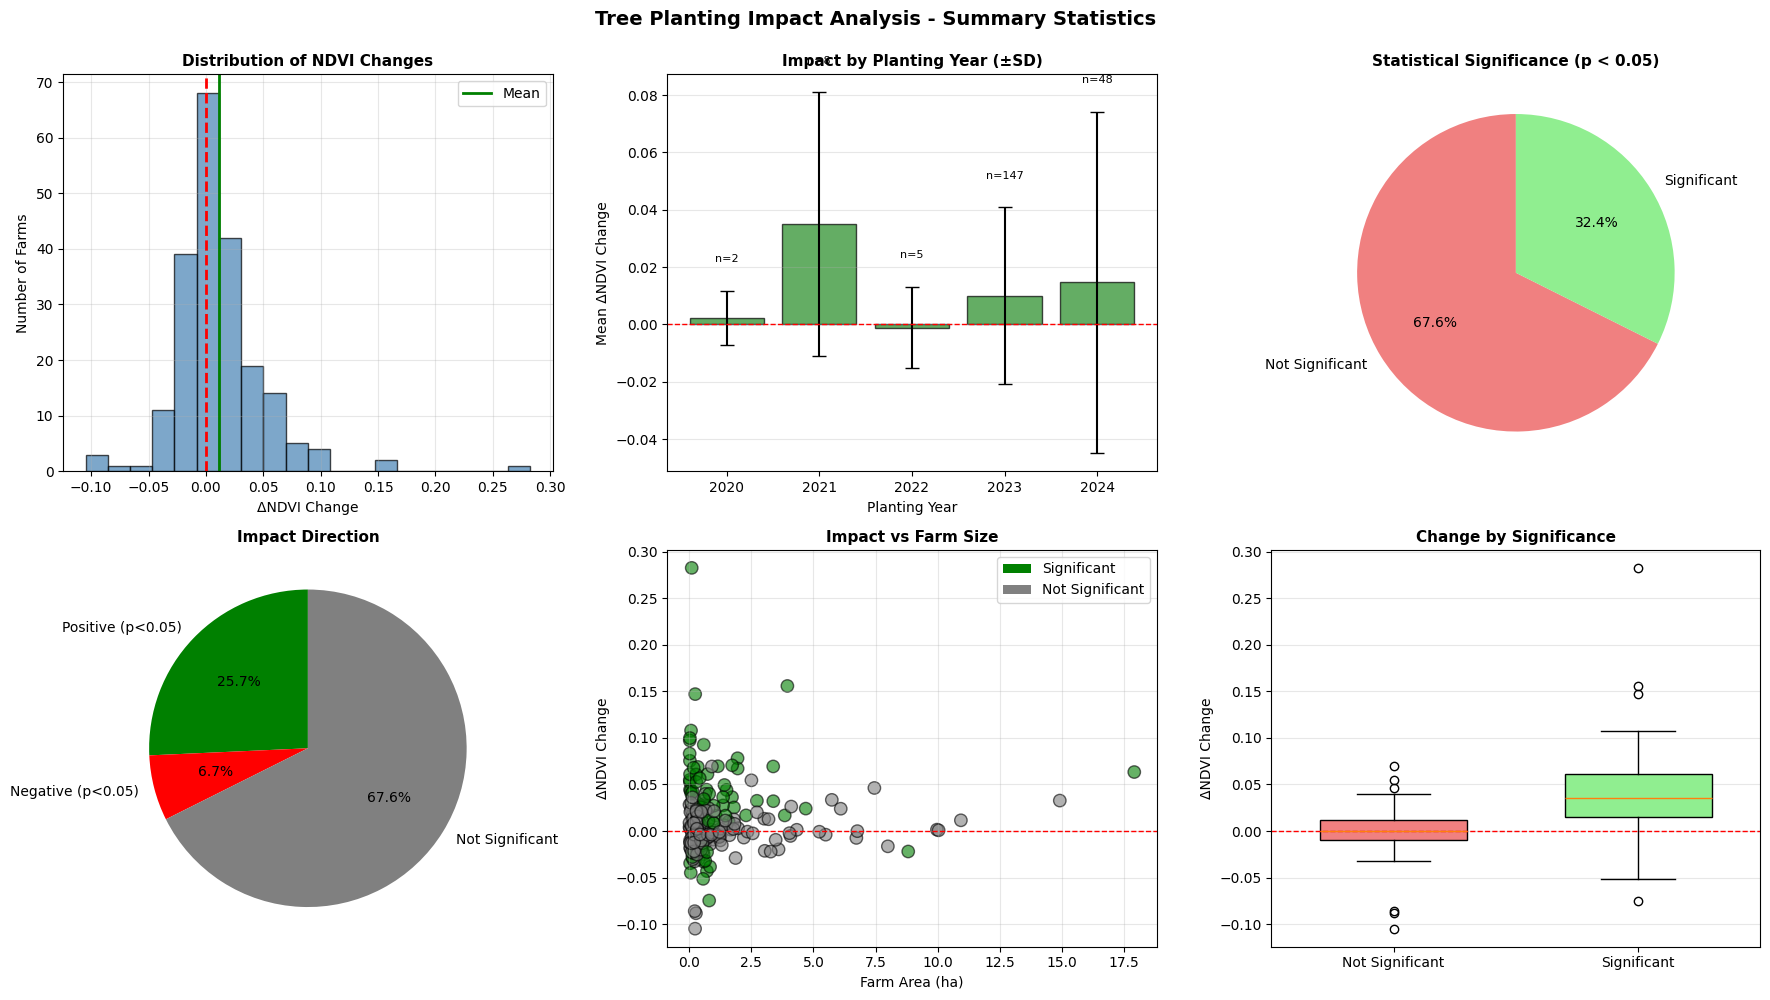


Creating aggregate time series plot...
✓ Aggregate time series plot saved to 'aggregate_time_series.png'


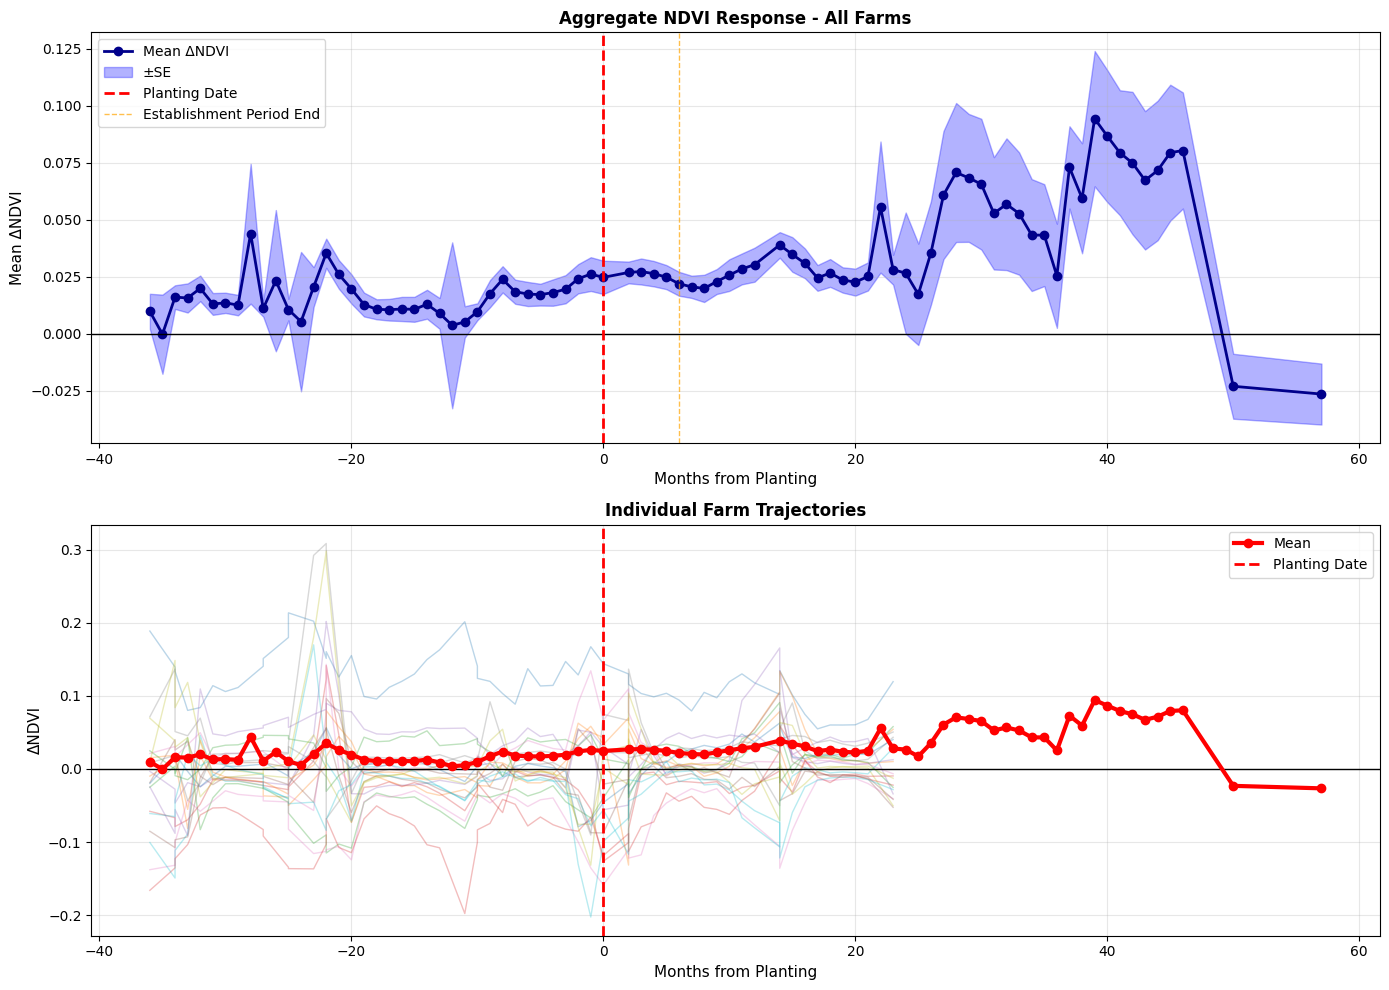


Creating spatial distribution map...
✓ Spatial distribution map saved to 'spatial_distribution_map.png'


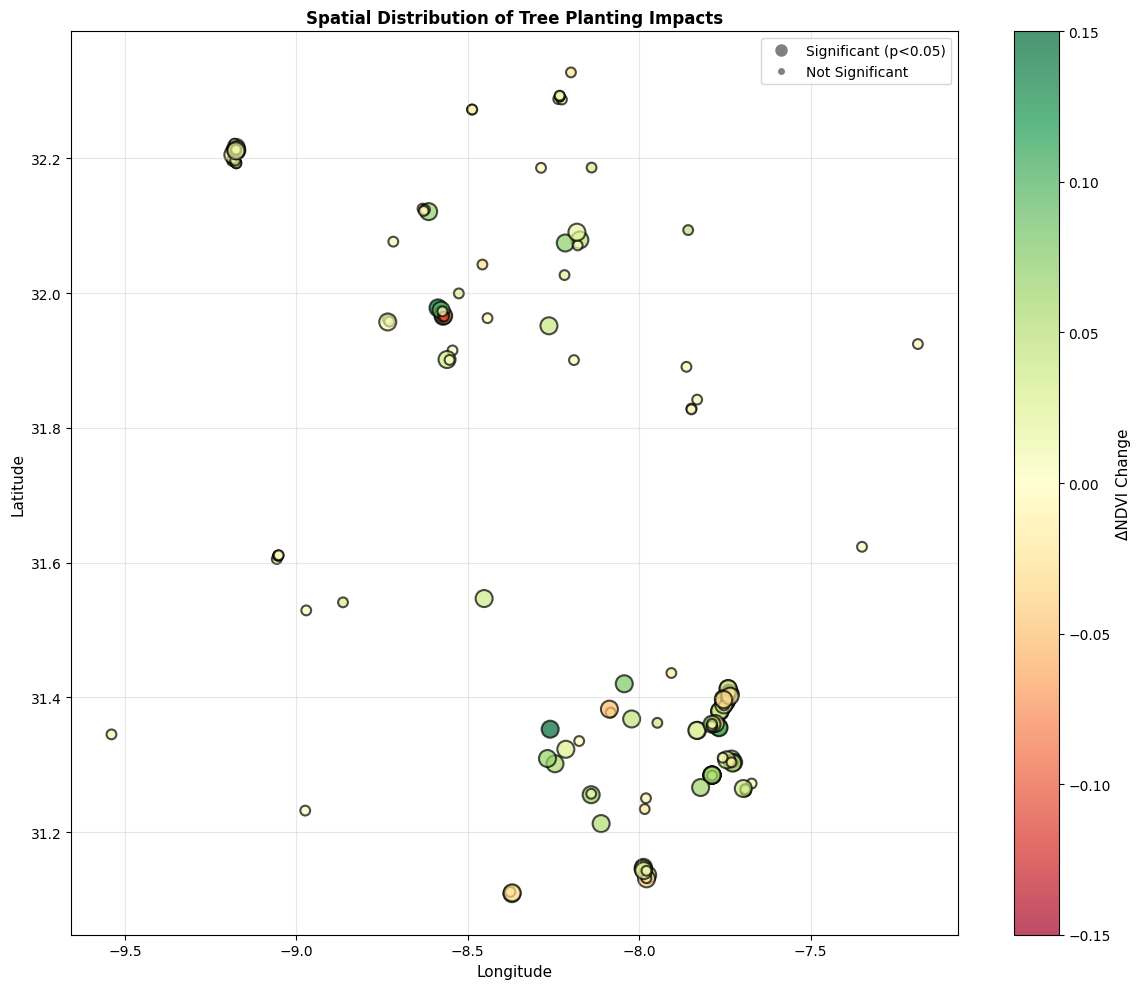


ALL PROCESSING COMPLETE

Generated files:
  • farm_impact_results_top3controls.csv - Detailed results for all farms
  • aggregate_summary_statistics.png - 6-panel summary statistics
  • aggregate_time_series.png - Aggregate temporal response
  • spatial_distribution_map.png - Geographic distribution of impacts


In [ ]:
# ============================================================================
# STEP 0: Fix package compatibility (run once, then restart runtime)
# ============================================================================
# Uncomment and run these lines, then restart runtime:
# import subprocess, sys
# subprocess.check_call([sys.executable, "-m", "pip", "install",
#                       "numpy==1.26.4", "scipy==1.12.0", "-q"])
# print("✓ Please RESTART RUNTIME, then run the rest of the code")

# ============================================================================
# After restarting runtime, run from here:
# ============================================================================

import ee
import geemap
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor, as_completed
from functools import partial
import time

# Import scipy with error handling
try:
    from scipy import stats
    SCIPY_AVAILABLE = True
except ImportError:
    print("Warning: SciPy not available. Using alternative statistics.")
    SCIPY_AVAILABLE = False

    # Simple t-test implementation as fallback
    class SimpleStats:
        @staticmethod
        def ttest_ind(a, b):
            """Simple independent t-test"""
            n1, n2 = len(a), len(b)
            mean1, mean2 = np.mean(a), np.mean(b)
            var1, var2 = np.var(a, ddof=1), np.var(b, ddof=1)

            pooled_se = np.sqrt(var1/n1 + var2/n2)
            t_stat = (mean1 - mean2) / pooled_se

            # Approximate p-value (two-tailed)
            df = n1 + n2 - 2
            # Rough approximation
            p_value = 2 * (1 - 0.5 * (1 + np.tanh(abs(t_stat)/2)))

            return t_stat, p_value

        @staticmethod
        def linregress(x, y):
            """Simple linear regression"""
            n = len(x)
            x_mean, y_mean = np.mean(x), np.mean(y)

            slope = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean)**2)
            intercept = y_mean - slope * x_mean

            y_pred = slope * x + intercept
            ss_tot = np.sum((y - y_mean)**2)
            ss_res = np.sum((y - y_pred)**2)
            r_squared = 1 - (ss_res / ss_tot)
            r_value = np.sqrt(r_squared) if r_squared > 0 else 0

            # Standard error
            std_err = np.sqrt(ss_res / (n - 2)) / np.sqrt(np.sum((x - x_mean)**2))

            # Approximate p-value
            t_stat = slope / std_err if std_err > 0 else 0
            p_value = 2 * (1 - 0.5 * (1 + np.tanh(abs(t_stat)/2)))

            return slope, intercept, r_value, p_value, std_err

    stats = SimpleStats()

print("="*80)
print("SENTINEL-2 NDVI IMPACT ANALYSIS - TREE PLANTING SITES")
print("Before-After Control-Impact (BACI) Design with 3 Closest Control Sites")
print("Using Sentinel-2 Surface Reflectance (10m resolution)")
print("OPTIMIZED FOR PARALLEL PROCESSING")
print("="*80)

# ===================================================================
# STEP 1: DEFINE TREATMENT AND TOP 3 CONTROL AREAS
# ===================================================================

def create_treatment_and_top3_controls(farm_row, dem):
    """
    Create treatment mask and identify 3 closest terrain-matched control sites.

    Parameters:
    - farm_row: Single row from farm_df with farm characteristics
    - dem: Digital Elevation Model (SRTM or similar)

    Returns treatment geometry and list of 3 control geometries
    """

    farm_id = farm_row['farm_id']
    lon = farm_row['lon']
    lat = farm_row['lat']
    altitude = farm_row['altitude']
    area_ha = farm_row['shape_ha']

    # 1.1 TREATMENT AREA
    if pd.notna(area_ha) and area_ha > 0:
        area_m2 = area_ha * 10000
        treatment_buffer = np.sqrt(area_m2 / np.pi)
        treatment_buffer = max(30, min(treatment_buffer, 100))
    else:
        treatment_buffer = 50

    farm_point = ee.Geometry.Point([lon, lat])
    treatment_geom = farm_point.buffer(treatment_buffer)

    # 1.2 SEARCH RING FOR CONTROLS
    if area_ha and area_ha > 1:
        inner_buffer = 150
        outer_buffer = 1000
    else:
        inner_buffer = 100
        outer_buffer = 600

    inner_ring = farm_point.buffer(inner_buffer)
    outer_ring = farm_point.buffer(outer_buffer)
    control_ring = outer_ring.difference(inner_ring)

    # Calculate slope
    slope = ee.Terrain.slope(dem)

    # Get treatment terrain characteristics
    if pd.notna(altitude):
        altitude_tolerance = 50
        elev_min = altitude - altitude_tolerance
        elev_max = altitude + altitude_tolerance
    else:
        treatment_elevation = dem.reduceRegion(
            reducer=ee.Reducer.mean(),
            geometry=treatment_geom,
            scale=30,
            maxPixels=1e6
        )
        elev_mean = ee.Number(treatment_elevation.get('elevation'))
        elev_tolerance = 50
        elev_min = elev_mean.subtract(elev_tolerance)
        elev_max = elev_mean.add(elev_tolerance)

    treatment_slope = slope.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=treatment_geom,
        scale=30,
        maxPixels=1e6
    )
    slope_mean = ee.Number(treatment_slope.get('slope'))
    slope_tolerance = slope_mean.multiply(0.20)
    slope_min = slope_mean.subtract(slope_tolerance)
    slope_max = slope_mean.add(slope_tolerance)

    # Create terrain similarity mask
    terrain_mask = dem.gte(elev_min).And(dem.lte(elev_max)) \
                      .And(slope.gte(slope_min)).And(slope.lte(slope_max))

    # Sample candidate control points within the ring
    similar_terrain = terrain_mask.selfMask()

    # Generate sample points
    sample_points = similar_terrain.sample(
        region=control_ring,
        scale=60,
        numPixels=100,
        seed=42,
        geometries=True
    )

    # Get info about points
    points_list = sample_points.getInfo()['features']

    if len(points_list) < 3:
        print(f"  Warning: Only {len(points_list)} control candidates found")
        # Fallback to relaxed criteria
        points_list = dem.sample(
            region=control_ring,
            scale=60,
            numPixels=100,
            seed=42,
            geometries=True
        ).getInfo()['features']

    # Calculate distances from treatment center
    distances = []
    for point in points_list:
        coords = point['geometry']['coordinates']
        point_geom = ee.Geometry.Point(coords)
        dist = farm_point.distance(point_geom).getInfo()
        distances.append((dist, coords))

    # Sort by distance and take closest 3
    distances.sort(key=lambda x: x[0])
    top3_coords = [coords for _, coords in distances[:3]]

    # Create control geometries (same size as treatment)
    control_geoms = [ee.Geometry.Point(coords).buffer(treatment_buffer)
                     for coords in top3_coords]

    print(f"  Selected 3 control sites at distances: {[f'{d:.0f}m' for d, _ in distances[:3]]}")

    return treatment_geom, control_geoms, treatment_buffer, top3_coords

# ===================================================================
# STEP 2: LOAD & PREPROCESS SENTINEL-2 DATA
# ===================================================================

def mask_s2_clouds(image):
    """
    Mask clouds in Sentinel-2 imagery using QA60 band.
    QA60 contains cloud mask information from the MSI sensor.
    """
    qa = image.select('QA60')

    # Bits 10 and 11 are clouds and cirrus, respectively
    cloudBitMask = 1 << 10
    cirrusBitMask = 1 << 11

    # Both flags should be set to zero, indicating clear conditions
    mask = qa.bitwiseAnd(cloudBitMask).eq(0).And(
           qa.bitwiseAnd(cirrusBitMask).eq(0))

    return image.updateMask(mask)

def calculate_ndvi_s2(image):
    """Calculate NDVI from Sentinel-2 bands."""
    # Sentinel-2: B8 = NIR, B4 = Red
    ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')
    return image.addBands(ndvi)

def load_sentinel2_data(geometry, start_date, end_date, verbose=True):
    """
    Load and preprocess Sentinel-2 Surface Reflectance (Harmonized) data.

    Parameters:
    - geometry: ee.Geometry for spatial filtering
    - start_date: Start date (string 'YYYY-MM-DD')
    - end_date: End date (string 'YYYY-MM-DD')
    - verbose: Print loading information

    Returns:
    - ee.ImageCollection with NDVI band
    """
    if verbose:
        print(f"\nLoading Sentinel-2 data: {start_date} to {end_date}")

    # Load Sentinel-2 Surface Reflectance Harmonized
    s2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED') \
        .filterBounds(geometry) \
        .filterDate(start_date, end_date) \
        .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)) \
        .map(mask_s2_clouds) \
        .map(calculate_ndvi_s2) \
        .select('NDVI')

    if verbose:
        count = s2.size().getInfo()
        print(f"  Sentinel-2 images loaded: {count}")

    return s2

# ===================================================================
# STEP 3: TIME-SERIES CONSTRUCTION
# ===================================================================

def create_monthly_ndvi_composites(collection, start_date, end_date, verbose=True):
    """Create monthly median NDVI composites."""
    start = ee.Date(start_date)
    end = ee.Date(end_date)
    months = ee.List.sequence(0, end.difference(start, 'month').subtract(1))

    def create_monthly_image(month_offset):
        start_month = start.advance(month_offset, 'month')
        end_month = start_month.advance(1, 'month')
        monthly_images = collection.filterDate(start_month, end_month)

        monthly = ee.Algorithms.If(
            monthly_images.size().gt(0),
            monthly_images.median().set({
                'system:time_start': start_month.advance(15, 'day').millis(),
                'month': start_month.format('YYYY-MM')
            }),
            None
        )
        return monthly

    monthly_list = months.map(create_monthly_image)
    monthly_collection = ee.ImageCollection(monthly_list.removeAll([None]))

    if verbose:
        print(f"  Monthly composites: {monthly_collection.size().getInfo()}")

    return monthly_collection

def extract_ndvi_timeseries_top3(collection, treatment_geom, control_geoms):
    """
    Extract NDVI time series for treatment and 3 control areas.
    Optimized to reduce API calls.
    """
    print("\nExtracting NDVI time series...")

    # Create FeatureCollection with treatment and 3 controls
    regions = ee.FeatureCollection([
        ee.Feature(treatment_geom, {'type': 'treatment'}),
        ee.Feature(control_geoms[0], {'type': 'control_1'}),
        ee.Feature(control_geoms[1], {'type': 'control_2'}),
        ee.Feature(control_geoms[2], {'type': 'control_3'})
    ])

    def reduce_per_image(image):
        reduced = image.select('NDVI').reduceRegions(
            collection=regions,
            reducer=ee.Reducer.mean(),
            scale=10  # Sentinel-2 10m resolution
        )
        return reduced.map(lambda f: f.set({
            'date': image.date().format('YYYY-MM-dd'),
            'system_time': image.get('system:time_start')
        }))

    # Map over the collection and flatten - all in one server-side operation
    features = collection.map(reduce_per_image).flatten()

    # Single getInfo call instead of multiple
    print("  Fetching data from GEE (single batched request)...")
    data = features.getInfo()['features']

    # Convert to DataFrame
    df = pd.DataFrame([f['properties'] for f in data])
    df['date'] = pd.to_datetime(df['date'])
    df['NDVI'] = pd.to_numeric(df['mean'], errors='coerce')

    # Pivot to get separate columns
    df = df.pivot(index='date', columns='type', values='NDVI').reset_index()

    # Calculate average of 3 controls
    df['ndvi_control_avg'] = df[['control_1', 'control_2', 'control_3']].mean(axis=1)

    # Rename treatment column
    if 'treatment' in df.columns:
        df.rename(columns={'treatment': 'ndvi_treatment'}, inplace=True)

    df = df.dropna(subset=['ndvi_treatment', 'ndvi_control_avg']).sort_values('date').reset_index(drop=True)

    print(f"  Extracted {len(df)} valid observations")

    return df

# ===================================================================
# STEP 4: NORMALIZE FOR CLIMATE VARIABILITY
# ===================================================================

def calculate_difference_in_differences(df, verbose=True):
    """Calculate ΔNDVI = NDVI_treatment - NDVI_control_avg"""
    df['delta_ndvi'] = df['ndvi_treatment'] - df['ndvi_control_avg']

    if verbose:
        print(f"  Mean ΔNDVI: {df['delta_ndvi'].mean():.4f} ± {df['delta_ndvi'].std():.4f}")

    return df

# ===================================================================
# STEP 5: BEFORE-AFTER ANALYSIS
# ===================================================================

def before_after_analysis(df, planting_date, exclusion_months=6, verbose=True):
    """Analyze NDVI changes before and after planting."""
    planting_dt = pd.to_datetime(planting_date)
    exclusion_end = planting_dt + pd.DateOffset(months=exclusion_months)

    df['period'] = 'baseline'
    df.loc[df['date'] >= planting_dt, 'period'] = 'establishment'
    df.loc[df['date'] >= exclusion_end, 'period'] = 'impact'

    baseline_df = df[df['period'] == 'baseline']
    impact_df = df[df['period'] == 'impact']

    if len(baseline_df) < 3 or len(impact_df) < 3:
        if verbose:
            print(f"  Warning: Insufficient data (baseline={len(baseline_df)}, impact={len(impact_df)})")
        return df, baseline_df, impact_df, None, None, None

    change = impact_df['delta_ndvi'].mean() - baseline_df['delta_ndvi'].mean()
    t_stat, p_value = stats.ttest_ind(impact_df['delta_ndvi'], baseline_df['delta_ndvi'])

    if verbose:
        print(f"  Baseline: {len(baseline_df)} obs, ΔNDVI = {baseline_df['delta_ndvi'].mean():.4f}")
        print(f"  Impact: {len(impact_df)} obs, ΔNDVI = {impact_df['delta_ndvi'].mean():.4f}")
        print(f"  Change: {change:+.4f}, p-value: {p_value:.4f}")

    return df, baseline_df, impact_df, change, t_stat, p_value

# ===================================================================
# STEP 6: CREATE BACI MAPS
# ===================================================================

def create_baci_maps(farm_row, treatment_geom, control_geoms, hls_monthly,
                     planting_date, farm_id):
    """
    Create Before-After maps showing NDVI at treatment and control sites.
    """
    print("\nCreating BACI maps...")

    planting_dt = pd.to_datetime(planting_date)

    # Define before period (6 months before planting)
    before_start = (planting_dt - pd.DateOffset(months=6)).strftime('%Y-%m-%d')
    before_end = planting_dt.strftime('%Y-%m-%d')

    # Define after period (6 months after establishment, ~12-18 months after planting)
    after_start = (planting_dt + pd.DateOffset(months=12)).strftime('%Y-%m-%d')
    after_end = (planting_dt + pd.DateOffset(months=18)).strftime('%Y-%m-%d')

    # Get median NDVI for before and after periods
    before_ndvi = s2_monthly.filterDate(before_start, before_end).median().select('NDVI')
    after_ndvi = s2_monthly.filterDate(after_start, after_end).median().select('NDVI')

    # Calculate change
    ndvi_change = after_ndvi.subtract(before_ndvi)

    # Create visualization region (buffer around all sites)
    # Use bounds() directly without union to avoid geometry errors
    all_coords = []

    # Get coordinates from treatment
    treatment_coords = treatment_geom.bounds().coordinates().getInfo()[0]
    all_coords.extend(treatment_coords)

    # Get coordinates from controls
    for geom in control_geoms:
        control_coords = geom.bounds().coordinates().getInfo()[0]
        all_coords.extend(control_coords)

    # Find bounding box
    lons = [coord[0] for coord in all_coords]
    lats = [coord[1] for coord in all_coords]

    # Create rectangle with buffer
    buffer_deg = 0.005  # ~500m buffer
    vis_region = ee.Geometry.Rectangle([
        min(lons) - buffer_deg,
        min(lats) - buffer_deg,
        max(lons) + buffer_deg,
        max(lats) + buffer_deg
    ])

    # Create map
    Map = geemap.Map()
    Map.centerObject(treatment_geom, 14)

    # NDVI visualization parameters
    ndvi_vis = {
        'min': 0.0,
        'max': 0.8,
        'palette': ['red', 'yellow', 'green']
    }

    change_vis = {
        'min': -0.2,
        'max': 0.2,
        'palette': ['red', 'white', 'green']
    }

    # Add layers
    Map.addLayer(before_ndvi.clip(vis_region), ndvi_vis, 'Before NDVI', False)
    Map.addLayer(after_ndvi.clip(vis_region), ndvi_vis, 'After NDVI', False)
    Map.addLayer(ndvi_change.clip(vis_region), change_vis, 'NDVI Change', True)

    # Add site markers
    Map.addLayer(treatment_geom, {'color': 'red'}, 'Treatment Site')
    Map.addLayer(control_geoms[0], {'color': 'blue'}, 'Control 1')
    Map.addLayer(control_geoms[1], {'color': 'blue'}, 'Control 2')
    Map.addLayer(control_geoms[2], {'color': 'blue'}, 'Control 3')

    # Save map
    map_file = f'baci_map_farm_{farm_id}.html'
    Map.save(map_file)
    print(f"  ✓ Map saved to '{map_file}'")

    return Map

# ===================================================================
# STEP 7: ENHANCED VISUALIZATION
# ===================================================================

def plot_time_series_enhanced(df, planting_date, farm_id):
    """Enhanced plots showing all 3 controls and their average."""

    fig, axes = plt.subplots(3, 1, figsize=(14, 12))
    planting_dt = pd.to_datetime(planting_date)

    # Plot 1: Treatment vs Individual Controls
    axes[0].plot(df['date'], df['ndvi_treatment'], 'o-',
                 label='Treatment', color='darkgreen', linewidth=2, markersize=6)

    if 'control_1' in df.columns:
        axes[0].plot(df['date'], df['control_1'], '^--',
                     label='Control 1', color='lightblue', alpha=0.6, markersize=4)
    if 'control_2' in df.columns:
        axes[0].plot(df['date'], df['control_2'], 's--',
                     label='Control 2', color='skyblue', alpha=0.6, markersize=4)
    if 'control_3' in df.columns:
        axes[0].plot(df['date'], df['control_3'], 'd--',
                     label='Control 3', color='steelblue', alpha=0.6, markersize=4)

    axes[0].plot(df['date'], df['ndvi_control_avg'], 'o-',
                 label='Control Average', color='navy', linewidth=2, markersize=5)

    axes[0].axvline(planting_dt, color='red', linestyle='--', linewidth=2, label='Planting Date')
    axes[0].set_ylabel('NDVI', fontsize=11)
    axes[0].set_title(f'Farm {farm_id}: NDVI Time Series - Treatment vs Controls', fontsize=12, fontweight='bold')
    axes[0].legend(loc='best', fontsize=9)
    axes[0].grid(True, alpha=0.3)

    # Plot 2: Difference (ΔNDVI)
    axes[1].plot(df['date'], df['delta_ndvi'], 'o-', color='purple', linewidth=2, markersize=5)
    axes[1].axhline(0, color='black', linestyle='-', linewidth=1)
    axes[1].axvline(planting_dt, color='red', linestyle='--', linewidth=2, label='Planting Date')

    # Add shaded regions for periods
    if 'period' in df.columns:
        baseline_dates = df[df['period'] == 'baseline']['date']
        if len(baseline_dates) > 0:
            axes[1].axvspan(baseline_dates.min(), baseline_dates.max(),
                           alpha=0.1, color='blue', label='Baseline')

        impact_dates = df[df['period'] == 'impact']['date']
        if len(impact_dates) > 0:
            axes[1].axvspan(impact_dates.min(), impact_dates.max(),
                           alpha=0.1, color='green', label='Impact')

    axes[1].set_ylabel('ΔNDVI (Treatment - Control)', fontsize=11)
    axes[1].set_title('Difference-in-Differences Over Time', fontsize=12, fontweight='bold')
    axes[1].legend(loc='best', fontsize=9)
    axes[1].grid(True, alpha=0.3)

    # Plot 3: Before-After Comparison
    baseline = df[df['period'] == 'baseline']['delta_ndvi']
    impact = df[df['period'] == 'impact']['delta_ndvi']

    bp = axes[2].boxplot([baseline, impact], labels=['Before Planting', 'After Planting'],
                         patch_artist=True, widths=0.6)

    # Color the boxes
    bp['boxes'][0].set_facecolor('lightcoral')
    bp['boxes'][1].set_facecolor('lightgreen')

    axes[2].axhline(0, color='black', linestyle='-', linewidth=1)
    axes[2].set_ylabel('ΔNDVI', fontsize=11)
    axes[2].set_title('Before-After Comparison', fontsize=12, fontweight='bold')
    axes[2].grid(True, alpha=0.3, axis='y')

    # Add statistics text
    change = impact.mean() - baseline.mean()
    stats_text = f'Change: {change:+.4f}\nBaseline mean: {baseline.mean():.4f}\nImpact mean: {impact.mean():.4f}'
    axes[2].text(0.02, 0.98, stats_text, transform=axes[2].transAxes,
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5),
                fontsize=9)

    plt.tight_layout()
    plot_file = f'ndvi_analysis_farm_{farm_id}.png'
    plt.savefig(plot_file, dpi=300, bbox_inches='tight')
    print(f"  ✓ Plot saved to '{plot_file}'")
    plt.show()

# ===================================================================
# MAIN ANALYSIS FUNCTION
# ===================================================================

def analyze_single_farm(farm_row, dem, region_geom, overall_start='2018-01-01',
                        overall_end='2024-12-31', exclusion_months=6, verbose=False):
    """
    Analyze a single farm with 3 closest control sites.
    Set verbose=False for parallel processing to reduce print clutter.
    """

    farm_id = farm_row['farm_id']
    planting_year = int(farm_row['planting_year'])

    if verbose:
        print(f"\n{'='*70}")
        print(f"Farm {farm_id}: Planted in {planting_year}")
        print(f"{'='*70}")

    try:
        # Step 1: Create treatment and 3 control areas
        treatment_geom, control_geoms, t_buffer, control_coords = \
            create_treatment_and_top3_controls(farm_row, dem)

        if verbose:
            print(f"  Treatment buffer: {t_buffer:.0f}m")

        # Step 2: Set date range
        baseline_start = f"{planting_year - 3}-01-01"
        planting_date = f"{planting_year}-01-01"

        # Step 3: Load Sentinel-2 data
        buffer_for_load = treatment_geom.buffer(1500)
        s2_collection = load_sentinel2_data(buffer_for_load, baseline_start, overall_end, verbose=False)

        s2_monthly = create_monthly_ndvi_composites(s2_collection, baseline_start,
                                                      overall_end, verbose=False)

        n_months = s2_monthly.size().getInfo()
        if n_months < 12:
            if verbose:
                print(f"  ERROR: Too few images ({n_months} < 12)")
            return None

        # Step 4: Extract time series
        ndvi_df = extract_ndvi_timeseries_top3(s2_monthly, treatment_geom, control_geoms)

        if len(ndvi_df) < 12:
            if verbose:
                print(f"  ERROR: Insufficient valid observations ({len(ndvi_df)})")
            return None

        # Step 5: Calculate DiD
        ndvi_df = calculate_difference_in_differences(ndvi_df, verbose=False)

        # Step 6: Before-After analysis
        ndvi_df, baseline_df, impact_df, change, t_stat, p_value = \
            before_after_analysis(ndvi_df, planting_date, exclusion_months, verbose=False)

        if change is None:
            return None

        # NOTE: Removed individual map and plot generation
        # Maps and plots will be created at the end for all farms

        # Compile results
        results = {
            'farm_id': farm_id,
            'lat': farm_row['lat'],
            'lon': farm_row['lon'],
            'altitude': farm_row['altitude'],
            'area_ha': farm_row['shape_ha'],
            'planting_year': planting_year,
            'planting_date': planting_date,
            'n_baseline_obs': len(baseline_df),
            'n_impact_obs': len(impact_df),
            'baseline_mean_delta_ndvi': baseline_df['delta_ndvi'].mean(),
            'baseline_std_delta_ndvi': baseline_df['delta_ndvi'].std(),
            'impact_mean_delta_ndvi': impact_df['delta_ndvi'].mean(),
            'impact_std_delta_ndvi': impact_df['delta_ndvi'].std(),
            'change_delta_ndvi': change,
            't_statistic': t_stat,
            'p_value': p_value,
            'significant': p_value < 0.05,
            'positive_impact': (p_value < 0.05) and (change > 0),
            'treatment_buffer_m': t_buffer,
            'control_1_coords': control_coords[0],
            'control_2_coords': control_coords[1],
            'control_3_coords': control_coords[2],
            'treatment_geom': treatment_geom,
            'control_geoms': control_geoms,
            'timeseries_df': ndvi_df
        }

        # Calculate trend
        if len(impact_df) > 3:
            impact_df_sorted = impact_df.sort_values('date')
            x = np.arange(len(impact_df_sorted))
            y = impact_df_sorted['delta_ndvi'].values

            slope, intercept, r_value, p_trend, std_err = stats.linregress(x, y)
            slope_per_year = slope * 12

            results['trend_slope_per_year'] = slope_per_year
            results['trend_r_squared'] = r_value**2
            results['trend_p_value'] = p_trend

        if verbose:
            print(f"  ✓ Farm {farm_id} complete: Change = {change:+.4f}, p = {p_value:.4f}")

        return results

    except Exception as e:
        print(f"  ✗ Farm {farm_id} failed: {str(e)}")
        return None

# ===================================================================
# MAIN EXECUTION - PARALLEL PROCESSING
# ===================================================================

print("\n" + "="*80)
print("ANALYZING ALL FARMS WITH 3 CLOSEST CONTROLS")
print("Using Sentinel-2 SR Harmonized (10m resolution)")
print("PARALLEL PROCESSING MODE")
print("="*80)

# Load DEM (shared across all farms)
print("\nLoading DEM...")
dem = ee.Image('USGS/SRTMGL1_003').select('elevation')

# Define overall study region
min_lon = farm_df['lon'].min() - 0.1
max_lon = farm_df['lon'].max() + 0.1
min_lat = farm_df['lat'].min() - 0.1
max_lat = farm_df['lat'].max() + 0.1
region_geom = ee.Geometry.Rectangle([min_lon, min_lat, max_lon, max_lat])

overall_start = '2017-01-01'  # Sentinel-2 data availability begins 2017
overall_end = '2024-12-31'

# Create a partial function with fixed parameters
analyze_farm = partial(
    analyze_single_farm,
    dem=dem,
    region_geom=region_geom,
    overall_start=overall_start,
    overall_end=overall_end,
    exclusion_months=6,
    verbose=False  # Suppress verbose output in parallel mode
)

all_results = []
failed_farms = []

# ===================================================================
# PARALLEL PROCESSING OPTIONS
# ===================================================================

# Choose processing mode
USE_PARALLEL = True  # Set to False for sequential processing (easier debugging)
MAX_WORKERS = 6  # Number of parallel threads (adjust based on your system)

print(f"\nProcessing {len(farm_df)} farms...")
print(f"Mode: {'PARALLEL' if USE_PARALLEL else 'SEQUENTIAL'}")
if USE_PARALLEL:
    print(f"Workers: {MAX_WORKERS}")

start_time = time.time()

if USE_PARALLEL:
    # ===================================================================
    # PARALLEL PROCESSING
    # ===================================================================
    print("\nStarting parallel processing...")

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        # Submit all jobs
        future_to_farm = {
            executor.submit(analyze_farm, farm_row): farm_row['farm_id']
            for idx, farm_row in farm_df.iterrows()
        }

        # Process completed jobs as they finish
        completed = 0
        for future in as_completed(future_to_farm):
            farm_id = future_to_farm[future]
            completed += 1

            try:
                result = future.result()
                if result is not None:
                    all_results.append(result)
                    print(f"  ✓ [{completed}/{len(farm_df)}] Farm {farm_id}: "
                          f"ΔNDVI = {result['change_delta_ndvi']:+.4f}, "
                          f"p = {result['p_value']:.4f}")
                else:
                    failed_farms.append(farm_id)
                    print(f"  ✗ [{completed}/{len(farm_df)}] Farm {farm_id}: Failed analysis")

            except Exception as e:
                failed_farms.append(farm_id)
                print(f"  ✗ [{completed}/{len(farm_df)}] Farm {farm_id}: Exception - {str(e)}")

else:
    # ===================================================================
    # SEQUENTIAL PROCESSING (for debugging)
    # ===================================================================
    print("\nStarting sequential processing...")

    for idx, farm_row in farm_df.iterrows():
        farm_id = farm_row['farm_id']
        print(f"\n[{idx+1}/{len(farm_df)}] Processing Farm {farm_id}...")

        result = analyze_farm(farm_row)

        if result is not None:
            all_results.append(result)
            print(f"  ✓ Complete: ΔNDVI = {result['change_delta_ndvi']:+.4f}, "
                  f"p = {result['p_value']:.4f}")
        else:
            failed_farms.append(farm_id)
            print(f"  ✗ Failed")

elapsed_time = time.time() - start_time

# ===================================================================
# TIMING STATISTICS
# ===================================================================

print("\n" + "="*80)
print("PROCESSING COMPLETE")
print("="*80)
print(f"Total time: {elapsed_time:.1f} seconds ({elapsed_time/60:.1f} minutes)")
print(f"Average time per farm: {elapsed_time/len(farm_df):.1f} seconds")
print(f"Successfully analyzed: {len(all_results)} farms")
print(f"Failed: {len(failed_farms)} farms")

if len(failed_farms) > 0 and len(failed_farms) <= 10:
    print(f"Failed farm IDs: {failed_farms}")
elif len(failed_farms) > 10:
    print(f"Failed farm IDs (first 10): {failed_farms[:10]}...")

if len(all_results) > 0:
    results_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ['timeseries_df', 'treatment_geom', 'control_geoms']}
                                for r in all_results])

    print("\n" + "="*80)
    print("SUMMARY STATISTICS")
    print("="*80)

    print(f"\nTotal farms analyzed: {len(results_df)}")
    print(f"Statistically significant impacts: {results_df['significant'].sum()} "
          f"({100*results_df['significant'].mean():.1f}%)")
    print(f"Positive impacts: {results_df['positive_impact'].sum()} "
          f"({100*results_df['positive_impact'].mean():.1f}%)")

    print("\nΔNDVI Change Distribution:")
    print(f"  Mean: {results_df['change_delta_ndvi'].mean():+.4f}")
    print(f"  Median: {results_df['change_delta_ndvi'].median():+.4f}")
    print(f"  Std Dev: {results_df['change_delta_ndvi'].std():.4f}")
    print(f"  Min: {results_df['change_delta_ndvi'].min():+.4f}")
    print(f"  Max: {results_df['change_delta_ndvi'].max():+.4f}")

    # Summary by planting year
    print("\n" + "="*60)
    print("Results by Planting Year:")
    print("="*60)
    year_summary = results_df.groupby('planting_year').agg({
        'farm_id': 'count',
        'change_delta_ndvi': ['mean', 'std'],
        'positive_impact': 'sum',
        'significant': 'sum'
    })
    year_summary.columns = ['N_farms', 'Mean_Change', 'Std_Change', 'N_Positive', 'N_Significant']
    print(year_summary)

    results_df.to_csv('farm_impact_results_top3controls.csv', index=False)
    print("\n✓ Results saved to 'farm_impact_results_top3controls.csv'")

    # ===================================================================
    # CREATE COMPREHENSIVE AGGREGATE PLOTS
    # ===================================================================

    print("\n" + "="*80)
    print("CREATING AGGREGATE VISUALIZATIONS")
    print("="*80)

    # FIGURE 1: Summary Statistics (2x3 grid)
    fig1, axes = plt.subplots(2, 3, figsize=(18, 10))

    # Plot 1: Distribution of NDVI changes
    axes[0, 0].hist(results_df['change_delta_ndvi'], bins=20, edgecolor='black', alpha=0.7, color='steelblue')
    axes[0, 0].axvline(0, color='red', linestyle='--', linewidth=2)
    axes[0, 0].axvline(results_df['change_delta_ndvi'].mean(), color='green', linestyle='-', linewidth=2, label='Mean')
    axes[0, 0].set_xlabel('ΔNDVI Change', fontsize=10)
    axes[0, 0].set_ylabel('Number of Farms', fontsize=10)
    axes[0, 0].set_title('Distribution of NDVI Changes', fontsize=11, fontweight='bold')
    axes[0, 0].legend()
    axes[0, 0].grid(True, alpha=0.3)

    # Plot 2: Change by planting year
    year_data = results_df.groupby('planting_year')['change_delta_ndvi'].agg(['mean', 'std', 'count'])
    axes[0, 1].bar(year_data.index, year_data['mean'], yerr=year_data['std'],
                   edgecolor='black', alpha=0.7, color='forestgreen', capsize=5)
    axes[0, 1].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[0, 1].set_xlabel('Planting Year', fontsize=10)
    axes[0, 1].set_ylabel('Mean ΔNDVI Change', fontsize=10)
    axes[0, 1].set_title('Impact by Planting Year (±SD)', fontsize=11, fontweight='bold')
    axes[0, 1].grid(True, alpha=0.3, axis='y')

    # Add sample size labels
    for year, row in year_data.iterrows():
        axes[0, 1].text(year, row['mean'] + row['std'] + 0.01, f"n={int(row['count'])}",
                       ha='center', fontsize=8)

    # Plot 3: Significance pie chart
    sig_counts = results_df['significant'].value_counts()
    colors_sig = ['lightcoral', 'lightgreen']
    axes[0, 2].pie(sig_counts, labels=['Not Significant', 'Significant'],
                    autopct='%1.1f%%', startangle=90, colors=colors_sig)
    axes[0, 2].set_title('Statistical Significance (p < 0.05)', fontsize=11, fontweight='bold')

    # Plot 4: Impact direction pie chart
    impact_counts = pd.Series({
        'Positive (p<0.05)': results_df['positive_impact'].sum(),
        'Negative (p<0.05)': ((results_df['significant']) &
                               (results_df['change_delta_ndvi'] < 0)).sum(),
        'Not Significant': (~results_df['significant']).sum()
    })
    colors_impact = ['green', 'red', 'gray']
    axes[1, 0].pie(impact_counts, labels=impact_counts.index,
                    autopct='%1.1f%%', startangle=90, colors=colors_impact)
    axes[1, 0].set_title('Impact Direction', fontsize=11, fontweight='bold')

    # Plot 5: Scatter plot - Change vs Area
    scatter = axes[1, 1].scatter(results_df['area_ha'], results_df['change_delta_ndvi'],
                                 c=results_df['significant'].map({True: 'green', False: 'gray'}),
                                 alpha=0.6, s=80, edgecolor='black')
    axes[1, 1].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[1, 1].set_xlabel('Farm Area (ha)', fontsize=10)
    axes[1, 1].set_ylabel('ΔNDVI Change', fontsize=10)
    axes[1, 1].set_title('Impact vs Farm Size', fontsize=11, fontweight='bold')
    axes[1, 1].grid(True, alpha=0.3)

    # Add legend
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor='green', label='Significant'),
                      Patch(facecolor='gray', label='Not Significant')]
    axes[1, 1].legend(handles=legend_elements, loc='best')

    # Plot 6: Box plot by significance
    sig_data = [results_df[results_df['significant'] == False]['change_delta_ndvi'],
                results_df[results_df['significant'] == True]['change_delta_ndvi']]
    bp = axes[1, 2].boxplot(sig_data, labels=['Not Significant', 'Significant'],
                            patch_artist=True, widths=0.6)
    bp['boxes'][0].set_facecolor('lightcoral')
    bp['boxes'][1].set_facecolor('lightgreen')
    axes[1, 2].axhline(0, color='red', linestyle='--', linewidth=1)
    axes[1, 2].set_ylabel('ΔNDVI Change', fontsize=10)
    axes[1, 2].set_title('Change by Significance', fontsize=11, fontweight='bold')
    axes[1, 2].grid(True, alpha=0.3, axis='y')

    plt.suptitle('Tree Planting Impact Analysis - Summary Statistics', fontsize=14, fontweight='bold', y=0.995)
    plt.tight_layout()
    plt.savefig('aggregate_summary_statistics.png', dpi=300, bbox_inches='tight')
    print("✓ Summary statistics plot saved to 'aggregate_summary_statistics.png'")
    plt.show()

    # ===================================================================
    # FIGURE 2: Aggregate Time Series
    # ===================================================================

    print("\nCreating aggregate time series plot...")

    # Combine all time series data
    all_timeseries = []
    for result in all_results:
        ts_df = result['timeseries_df'].copy()
        ts_df['farm_id'] = result['farm_id']
        ts_df['planting_year'] = result['planting_year']

        # Normalize time relative to planting
        planting_dt = pd.to_datetime(result['planting_date'])
        ts_df['months_from_planting'] = ((ts_df['date'] - planting_dt).dt.days / 30.44).round().astype(int)

        all_timeseries.append(ts_df)

    combined_ts = pd.concat(all_timeseries, ignore_index=True)

    # Create aggregate plot
    fig2, axes = plt.subplots(2, 1, figsize=(14, 10))

    # Plot 1: Mean trajectory with confidence interval
    monthly_stats = combined_ts.groupby('months_from_planting')['delta_ndvi'].agg(['mean', 'std', 'count'])
    monthly_stats = monthly_stats[monthly_stats['count'] >= 3]  # At least 3 farms

    # Calculate standard error
    monthly_stats['se'] = monthly_stats['std'] / np.sqrt(monthly_stats['count'])

    axes[0].plot(monthly_stats.index, monthly_stats['mean'], 'o-', color='darkblue', linewidth=2, label='Mean ΔNDVI')
    axes[0].fill_between(monthly_stats.index,
                         monthly_stats['mean'] - monthly_stats['se'],
                         monthly_stats['mean'] + monthly_stats['se'],
                         alpha=0.3, color='blue', label='±SE')
    axes[0].axhline(0, color='black', linestyle='-', linewidth=1)
    axes[0].axvline(0, color='red', linestyle='--', linewidth=2, label='Planting Date')
    axes[0].axvline(6, color='orange', linestyle='--', linewidth=1, alpha=0.7, label='Establishment Period End')
    axes[0].set_xlabel('Months from Planting', fontsize=11)
    axes[0].set_ylabel('Mean ΔNDVI', fontsize=11)
    axes[0].set_title('Aggregate NDVI Response - All Farms', fontsize=12, fontweight='bold')
    axes[0].legend(loc='best')
    axes[0].grid(True, alpha=0.3)

    # Plot 2: Individual farm trajectories (with transparency)
    for farm_id in combined_ts['farm_id'].unique()[:20]:  # Show first 20 farms
        farm_data = combined_ts[combined_ts['farm_id'] == farm_id]
        axes[1].plot(farm_data['months_from_planting'], farm_data['delta_ndvi'],
                    alpha=0.3, linewidth=1)

    # Overlay mean
    axes[1].plot(monthly_stats.index, monthly_stats['mean'], 'o-',
                color='red', linewidth=3, label='Mean', zorder=10)
    axes[1].axhline(0, color='black', linestyle='-', linewidth=1)
    axes[1].axvline(0, color='red', linestyle='--', linewidth=2, label='Planting Date')
    axes[1].set_xlabel('Months from Planting', fontsize=11)
    axes[1].set_ylabel('ΔNDVI', fontsize=11)
    axes[1].set_title('Individual Farm Trajectories', fontsize=12, fontweight='bold')
    axes[1].legend(loc='best')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('aggregate_time_series.png', dpi=300, bbox_inches='tight')
    print("✓ Aggregate time series plot saved to 'aggregate_time_series.png'")
    plt.show()

    # ===================================================================
    # FIGURE 3: Spatial Distribution Map
    # ===================================================================

    print("\nCreating spatial distribution map...")

    fig3, ax = plt.subplots(1, 1, figsize=(12, 10))

    # Color by impact
    colors = results_df['change_delta_ndvi'].apply(
        lambda x: 'darkgreen' if x > 0.05 else ('lightgreen' if x > 0 else ('lightcoral' if x > -0.05 else 'darkred'))
    )

    # Size by significance
    sizes = results_df['significant'].map({True: 150, False: 50})

    scatter = ax.scatter(results_df['lon'], results_df['lat'],
                        c=results_df['change_delta_ndvi'], cmap='RdYlGn',
                        s=sizes, alpha=0.7, edgecolors='black', linewidth=1.5,
                        vmin=-0.15, vmax=0.15)

    # Add colorbar
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label('ΔNDVI Change', fontsize=11)

    # Add legend for size
    from matplotlib.lines import Line2D
    legend_elements = [Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                             markersize=10, label='Significant (p<0.05)'),
                      Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                             markersize=6, label='Not Significant')]
    ax.legend(handles=legend_elements, loc='best', fontsize=10)

    ax.set_xlabel('Longitude', fontsize=11)
    ax.set_ylabel('Latitude', fontsize=11)
    ax.set_title('Spatial Distribution of Tree Planting Impacts', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('spatial_distribution_map.png', dpi=300, bbox_inches='tight')
    print("✓ Spatial distribution map saved to 'spatial_distribution_map.png'")
    plt.show()

else:
    print("\n⚠ No farms were successfully analyzed!")

print("\n" + "="*80)
print("ALL PROCESSING COMPLETE")
print("="*80)
print("\nGenerated files:")
print("  • farm_impact_results_top3controls.csv - Detailed results for all farms")
print("  • aggregate_summary_statistics.png - 6-panel summary statistics")
print("  • aggregate_time_series.png - Aggregate temporal response")
print("  • spatial_distribution_map.png - Geographic distribution of impacts")

Creating plots for 210 farms...


/tmp/ipython-input-287427921.py:89: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1, 2].boxplot(sig_data, labels=['Not Significant', 'Significant'],


✓ Summary statistics plot saved to 'aggregate_summary_statistics.png'


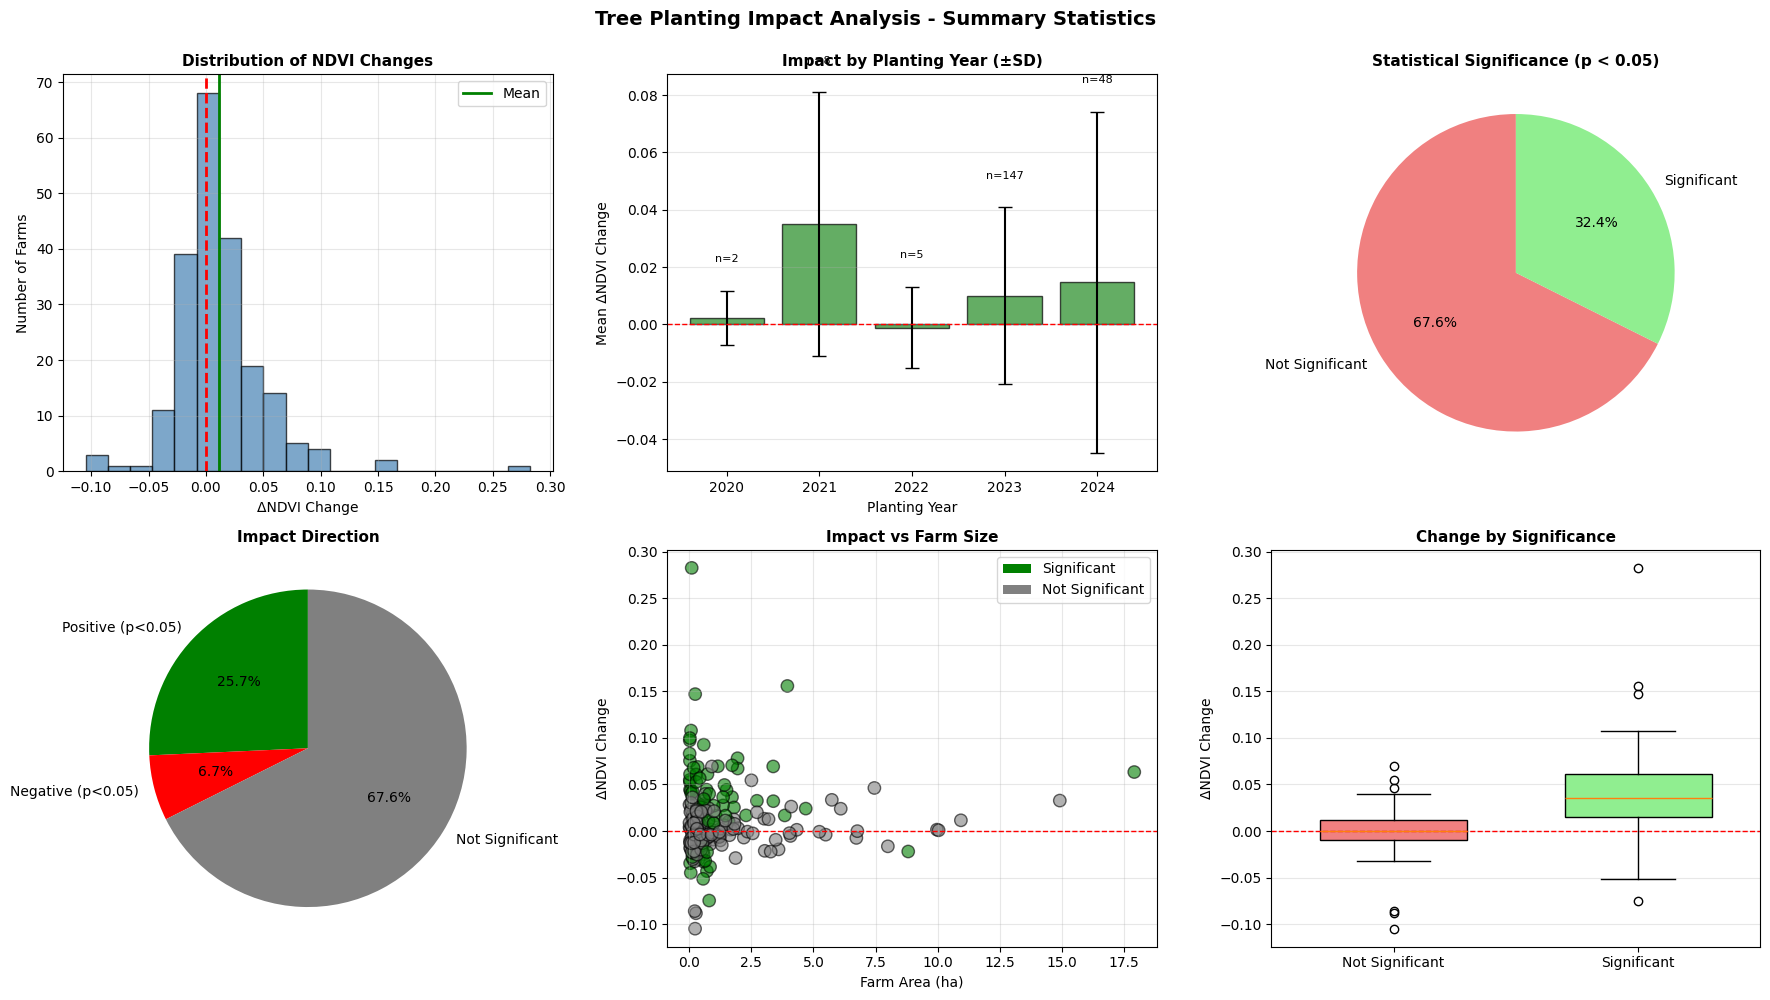


Creating aggregate time series plot...
✓ Aggregate time series plot saved to 'aggregate_time_series.png'


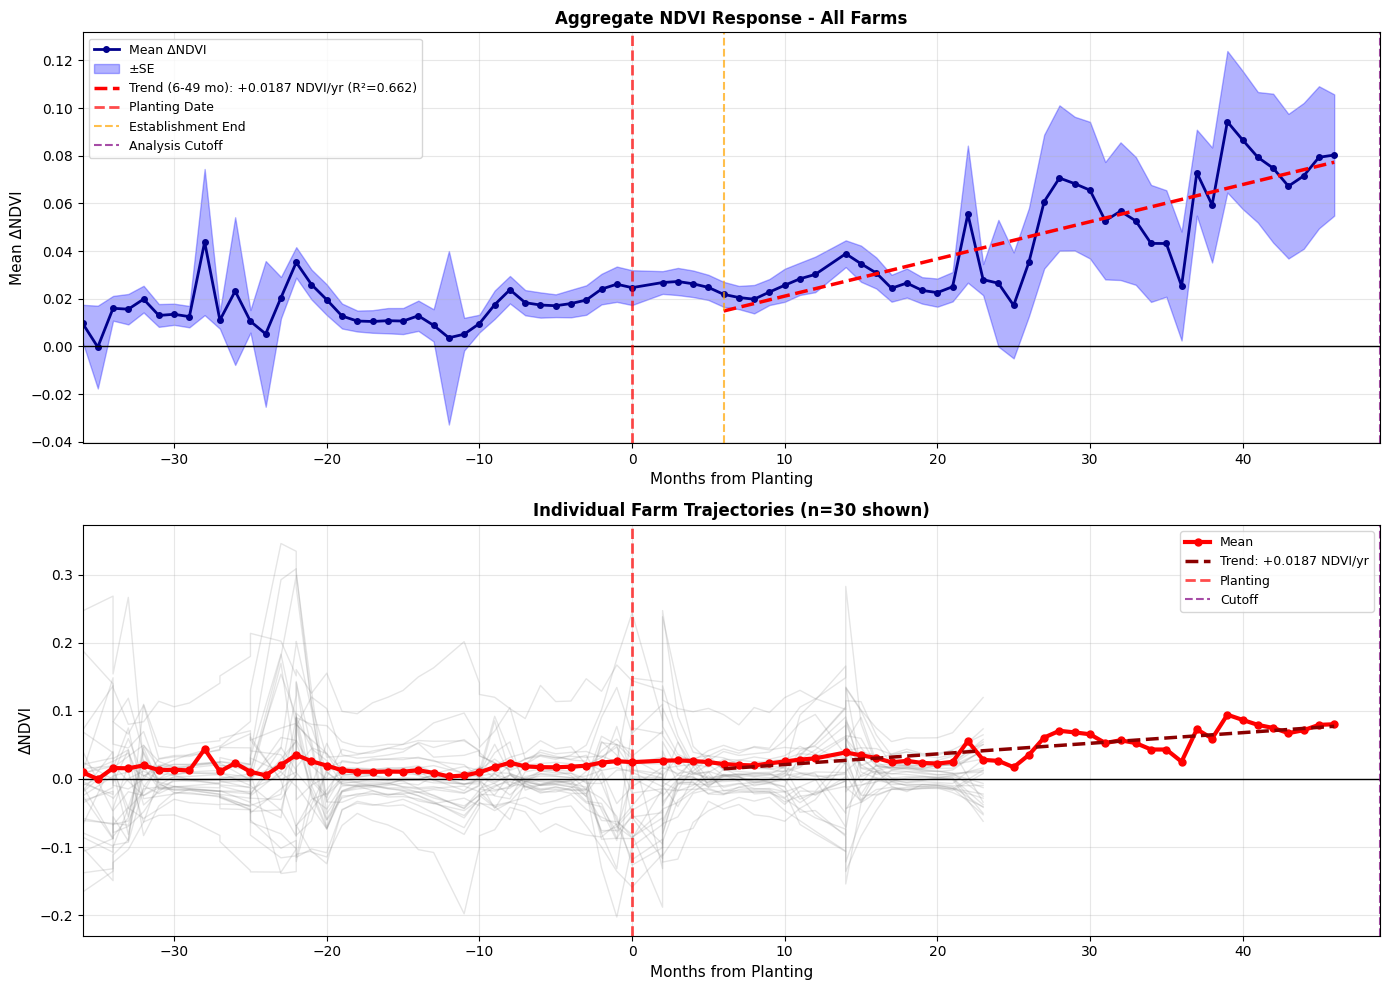


Creating spatial distribution map...
✓ Spatial distribution map saved to 'spatial_distribution_map.png'


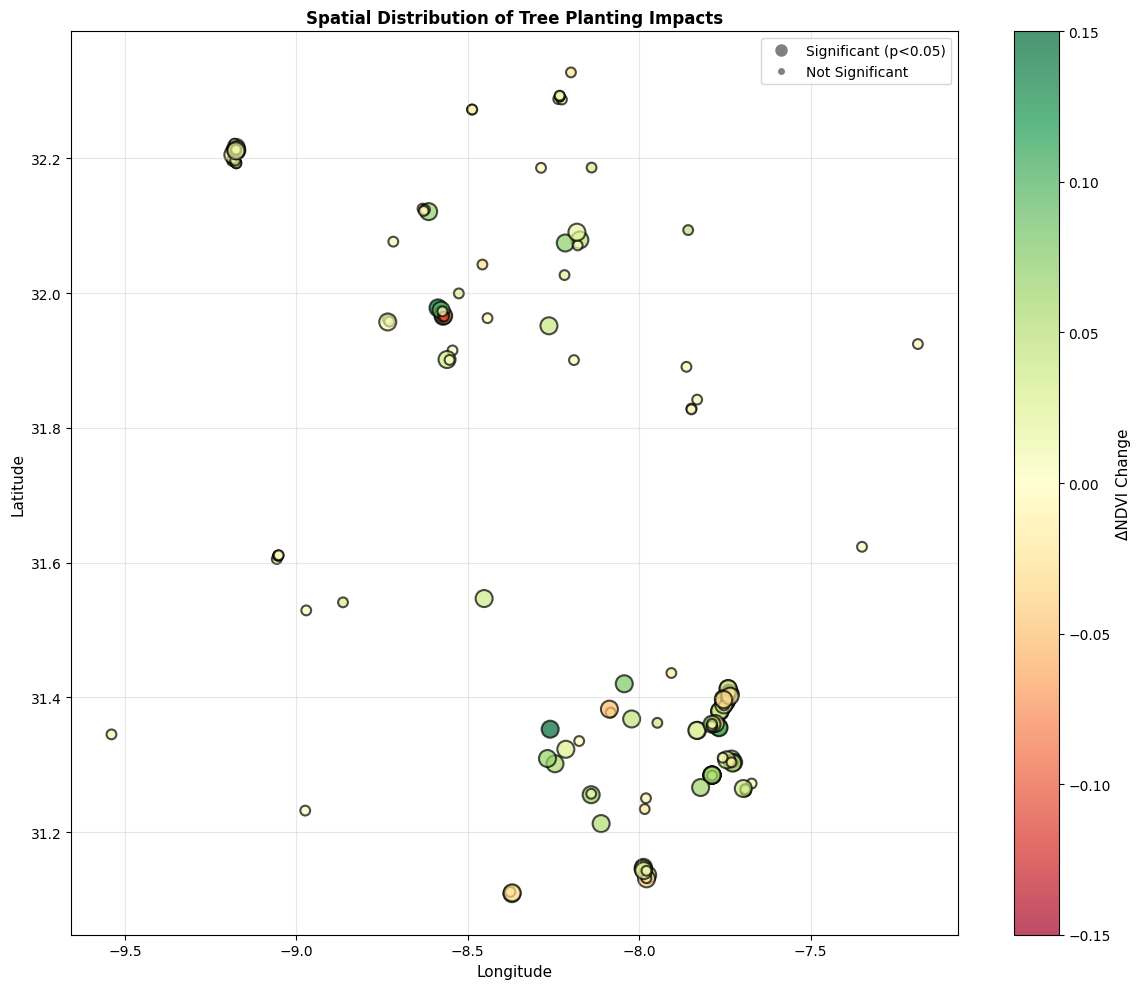


ALL PLOTS GENERATED

Generated files:
  • aggregate_summary_statistics.png - 6-panel summary
  • aggregate_time_series.png - Temporal response with trend lines
  • spatial_distribution_map.png - Geographic distribution


In [ ]:
# ===================================================================
# STANDALONE PLOTTING CODE - RUN AFTER ANALYSIS IS COMPLETE
# ===================================================================
# Prerequisites: all_results list must exist from previous analysis

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Check if results exist
if 'all_results' not in locals() or len(all_results) == 0:
    print("ERROR: No results found. Run the analysis first!")
else:
    print(f"Creating plots for {len(all_results)} farms...")

# ===================================================================
# FIGURE 1: Summary Statistics (2x3 grid)
# ===================================================================

results_df = pd.DataFrame([{k: v for k, v in r.items() if k not in ['timeseries_df', 'treatment_geom', 'control_geoms']}
                            for r in all_results])

fig1, axes = plt.subplots(2, 3, figsize=(18, 10))

# Plot 1: Distribution of NDVI changes
axes[0, 0].hist(results_df['change_delta_ndvi'], bins=20, edgecolor='black', alpha=0.7, color='steelblue')
axes[0, 0].axvline(0, color='red', linestyle='--', linewidth=2)
axes[0, 0].axvline(results_df['change_delta_ndvi'].mean(), color='green', linestyle='-', linewidth=2, label='Mean')
axes[0, 0].set_xlabel('ΔNDVI Change', fontsize=10)
axes[0, 0].set_ylabel('Number of Farms', fontsize=10)
axes[0, 0].set_title('Distribution of NDVI Changes', fontsize=11, fontweight='bold')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Change by planting year
year_data = results_df.groupby('planting_year')['change_delta_ndvi'].agg(['mean', 'std', 'count'])
axes[0, 1].bar(year_data.index, year_data['mean'], yerr=year_data['std'],
               edgecolor='black', alpha=0.7, color='forestgreen', capsize=5)
axes[0, 1].axhline(0, color='red', linestyle='--', linewidth=1)
axes[0, 1].set_xlabel('Planting Year', fontsize=10)
axes[0, 1].set_ylabel('Mean ΔNDVI Change', fontsize=10)
axes[0, 1].set_title('Impact by Planting Year (±SD)', fontsize=11, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Add sample size labels
for year, row in year_data.iterrows():
    axes[0, 1].text(year, row['mean'] + row['std'] + 0.01, f"n={int(row['count'])}",
                   ha='center', fontsize=8)

# Plot 3: Significance pie chart
sig_counts = results_df['significant'].value_counts()
colors_sig = ['lightcoral', 'lightgreen']
axes[0, 2].pie(sig_counts, labels=['Not Significant', 'Significant'],
                autopct='%1.1f%%', startangle=90, colors=colors_sig)
axes[0, 2].set_title('Statistical Significance (p < 0.05)', fontsize=11, fontweight='bold')

# Plot 4: Impact direction pie chart
impact_counts = pd.Series({
    'Positive (p<0.05)': results_df['positive_impact'].sum(),
    'Negative (p<0.05)': ((results_df['significant']) &
                           (results_df['change_delta_ndvi'] < 0)).sum(),
    'Not Significant': (~results_df['significant']).sum()
})
colors_impact = ['green', 'red', 'gray']
axes[1, 0].pie(impact_counts, labels=impact_counts.index,
                autopct='%1.1f%%', startangle=90, colors=colors_impact)
axes[1, 0].set_title('Impact Direction', fontsize=11, fontweight='bold')

# Plot 5: Scatter plot - Change vs Area
scatter = axes[1, 1].scatter(results_df['area_ha'], results_df['change_delta_ndvi'],
                             c=results_df['significant'].map({True: 'green', False: 'gray'}),
                             alpha=0.6, s=80, edgecolor='black')
axes[1, 1].axhline(0, color='red', linestyle='--', linewidth=1)
axes[1, 1].set_xlabel('Farm Area (ha)', fontsize=10)
axes[1, 1].set_ylabel('ΔNDVI Change', fontsize=10)
axes[1, 1].set_title('Impact vs Farm Size', fontsize=11, fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)

# Add legend
legend_elements = [Patch(facecolor='green', label='Significant'),
                  Patch(facecolor='gray', label='Not Significant')]
axes[1, 1].legend(handles=legend_elements, loc='best')

# Plot 6: Box plot by significance
sig_data = [results_df[results_df['significant'] == False]['change_delta_ndvi'],
            results_df[results_df['significant'] == True]['change_delta_ndvi']]
bp = axes[1, 2].boxplot(sig_data, labels=['Not Significant', 'Significant'],
                        patch_artist=True, widths=0.6)
bp['boxes'][0].set_facecolor('lightcoral')
bp['boxes'][1].set_facecolor('lightgreen')
axes[1, 2].axhline(0, color='red', linestyle='--', linewidth=1)
axes[1, 2].set_ylabel('ΔNDVI Change', fontsize=10)
axes[1, 2].set_title('Change by Significance', fontsize=11, fontweight='bold')
axes[1, 2].grid(True, alpha=0.3, axis='y')

plt.suptitle('Tree Planting Impact Analysis - Summary Statistics', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('aggregate_summary_statistics.png', dpi=300, bbox_inches='tight')
print("✓ Summary statistics plot saved to 'aggregate_summary_statistics.png'")
plt.show()

# ===================================================================
# FIGURE 2: Aggregate Time Series with Trend Lines
# ===================================================================

print("\nCreating aggregate time series plot...")

# Combine all time series data
all_timeseries = []
for result in all_results:
    ts_df = result['timeseries_df'].copy()
    ts_df['farm_id'] = result['farm_id']
    ts_df['planting_year'] = result['planting_year']

    # Normalize time relative to planting
    planting_dt = pd.to_datetime(result['planting_date'])
    ts_df['months_from_planting'] = ((ts_df['date'] - planting_dt).dt.days / 30.44).round().astype(int)

    all_timeseries.append(ts_df)

combined_ts = pd.concat(all_timeseries, ignore_index=True)

# Filter to only include -36 to +49 months (limit as specified)
combined_ts_filtered = combined_ts[
    (combined_ts['months_from_planting'] >= -36) &
    (combined_ts['months_from_planting'] <= 49)
]

# Create aggregate plot
fig2, axes = plt.subplots(2, 1, figsize=(14, 10))

# Plot 1: Mean trajectory with confidence interval and trend line
monthly_stats = combined_ts_filtered.groupby('months_from_planting')['delta_ndvi'].agg(['mean', 'std', 'count'])
monthly_stats = monthly_stats[monthly_stats['count'] >= 3]  # At least 3 farms

# Calculate standard error
monthly_stats['se'] = monthly_stats['std'] / np.sqrt(monthly_stats['count'])

axes[0].plot(monthly_stats.index, monthly_stats['mean'], 'o-', color='darkblue', linewidth=2, label='Mean ΔNDVI', markersize=4)
axes[0].fill_between(monthly_stats.index,
                     monthly_stats['mean'] - monthly_stats['se'],
                     monthly_stats['mean'] + monthly_stats['se'],
                     alpha=0.3, color='blue', label='±SE')

# Add trend line for impact period (6-49 months)
impact_period = monthly_stats[(monthly_stats.index >= 6) & (monthly_stats.index <= 49)]
if len(impact_period) > 2:
    x_trend = impact_period.index.values
    y_trend = impact_period['mean'].values

    # Fit linear trend
    z = np.polyfit(x_trend, y_trend, 1)
    p = np.poly1d(z)

    # Calculate R²
    y_pred = p(x_trend)
    ss_res = np.sum((y_trend - y_pred)**2)
    ss_tot = np.sum((y_trend - np.mean(y_trend))**2)
    r_squared = 1 - (ss_res / ss_tot)

    # Plot trend line
    axes[0].plot(x_trend, p(x_trend), '--', color='red', linewidth=2.5,
                label=f'Trend (6-49 mo): {z[0]*12:+.4f} NDVI/yr (R²={r_squared:.3f})')

axes[0].axhline(0, color='black', linestyle='-', linewidth=1)
axes[0].axvline(0, color='red', linestyle='--', linewidth=2, alpha=0.7, label='Planting Date')
axes[0].axvline(6, color='orange', linestyle='--', linewidth=1.5, alpha=0.7, label='Establishment End')
axes[0].axvline(49, color='purple', linestyle='--', linewidth=1.5, alpha=0.7, label='Analysis Cutoff')
axes[0].set_xlabel('Months from Planting', fontsize=11)
axes[0].set_ylabel('Mean ΔNDVI', fontsize=11)
axes[0].set_title('Aggregate NDVI Response - All Farms', fontsize=12, fontweight='bold')
axes[0].legend(loc='best', fontsize=9)
axes[0].grid(True, alpha=0.3)
axes[0].set_xlim(-36, 49)

# Plot 2: Individual farm trajectories (with transparency)
n_farms_to_plot = min(30, len(combined_ts['farm_id'].unique()))
for farm_id in combined_ts['farm_id'].unique()[:n_farms_to_plot]:
    farm_data = combined_ts_filtered[combined_ts_filtered['farm_id'] == farm_id]
    axes[1].plot(farm_data['months_from_planting'], farm_data['delta_ndvi'],
                alpha=0.2, linewidth=1, color='gray')

# Overlay mean with trend
axes[1].plot(monthly_stats.index, monthly_stats['mean'], 'o-',
            color='red', linewidth=3, label='Mean', zorder=10, markersize=5)

# Add trend line
if len(impact_period) > 2:
    axes[1].plot(x_trend, p(x_trend), '--', color='darkred', linewidth=2.5,
                label=f'Trend: {z[0]*12:+.4f} NDVI/yr', zorder=11)

axes[1].axhline(0, color='black', linestyle='-', linewidth=1)
axes[1].axvline(0, color='red', linestyle='--', linewidth=2, alpha=0.7, label='Planting')
axes[1].axvline(49, color='purple', linestyle='--', linewidth=1.5, alpha=0.7, label='Cutoff')
axes[1].set_xlabel('Months from Planting', fontsize=11)
axes[1].set_ylabel('ΔNDVI', fontsize=11)
axes[1].set_title(f'Individual Farm Trajectories (n={n_farms_to_plot} shown)', fontsize=12, fontweight='bold')
axes[1].legend(loc='best', fontsize=9)
axes[1].grid(True, alpha=0.3)
axes[1].set_xlim(-36, 49)

plt.tight_layout()
plt.savefig('aggregate_time_series.png', dpi=300, bbox_inches='tight')
print("✓ Aggregate time series plot saved to 'aggregate_time_series.png'")
plt.show()

# ===================================================================
# FIGURE 3: Spatial Distribution Map
# ===================================================================

print("\nCreating spatial distribution map...")

fig3, ax = plt.subplots(1, 1, figsize=(12, 10))

# Color by impact
colors = results_df['change_delta_ndvi'].apply(
    lambda x: 'darkgreen' if x > 0.05 else ('lightgreen' if x > 0 else ('lightcoral' if x > -0.05 else 'darkred'))
)

# Size by significance
sizes = results_df['significant'].map({True: 150, False: 50})

scatter = ax.scatter(results_df['lon'], results_df['lat'],
                    c=results_df['change_delta_ndvi'], cmap='RdYlGn',
                    s=sizes, alpha=0.7, edgecolors='black', linewidth=1.5,
                    vmin=-0.15, vmax=0.15)

# Add colorbar
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('ΔNDVI Change', fontsize=11)

# Add legend for size
legend_elements = [Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                         markersize=10, label='Significant (p<0.05)'),
                  Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                         markersize=6, label='Not Significant')]
ax.legend(handles=legend_elements, loc='best', fontsize=10)

ax.set_xlabel('Longitude', fontsize=11)
ax.set_ylabel('Latitude', fontsize=11)
ax.set_title('Spatial Distribution of Tree Planting Impacts', fontsize=12, fontweight='bold')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('spatial_distribution_map.png', dpi=300, bbox_inches='tight')
print("✓ Spatial distribution map saved to 'spatial_distribution_map.png'")
plt.show()

print("\n" + "="*80)
print("ALL PLOTS GENERATED")
print("="*80)
print("\nGenerated files:")
print("  • aggregate_summary_statistics.png - 6-panel summary")
print("  • aggregate_time_series.png - Temporal response with trend lines")
print("  • spatial_distribution_map.png - Geographic distribution")
print("="*80)